In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [1]:
#한글 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 24 not upgraded.
Need to get 9,599 kB of archives.
After this operation, 29.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu focal/universe amd64 fonts-nanum all 20180306-3 [9,599 kB]
Fetched 9,599 kB in 0s (21.9 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 76, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122518 files and dir

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt #시각화에 사용하는 것 이거하고 seaborn 두개 있다.
import folium
import re
import openpyxl
!pip install tabulate
from tabulate import tabulate
import math
! pip install haversine
from haversine import haversine
from scipy import stats
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn import preprocessing

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic') 

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
dfm = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/서울특별시 광진구 불법주정차 단속 전체연도.csv',  encoding='UTF-8')
print(dfm)

        Unnamed: 0                 단속일시   단속원금  단속동               단속장소  \
0                0     2015-01-01 06:44  40000  화양동              119-4   
1                1     2015-01-01 07:01  40000  화양동          건대입구1번출구앞   
2                2     2015-01-01 07:24  50000  구의동        동서울터미널 주차장앞   
3                3     2015-01-01 08:00  40000  화양동          건대입구1번출구앞   
4                4     2015-01-01 08:15  40000  화양동          건대입구1번출구앞   
...            ...                  ...    ...  ...                ...   
512801       39727  2023-02-28 20:43:00  32000  군자동               군자빌딩   
512802       39728  2023-02-28 21:23:00   8000  자양동  서울 광진구 자양동 659-32   
512803       39729  2023-02-28 21:38:00  32000  화양동     서울 광진구 능동로 154   
512804       39730  2023-02-28 22:36:00  32000  자양동   서울 광진구 자양동 12-10   
512805       39731  2023-02-28 23:19:00  32000  자양동              02-02   

                 위반내용  견인지시  
0               주정차금지  견인처리  
1         32조내지 34조위반   미견인  
2         32조내지 34조위반

In [ ]:
d63=ddfm[ddfm['단속장소']=='486-1']
print(d63)
d63['단속동'].value_counts()

                       단속일시   단속원금  단속동   단속장소   위반내용 견인지시  단속년도
135584     2017-01-04 15:02  40000  화양동  486-1  주정차위반  미견인  2017
136052     2017-01-06 16:39  50000  화양동  486-1  주정차위반  미견인  2017
144666     2017-02-20 15:09  40000  화양동  486-1  주정차위반  미견인  2017
144667     2017-02-20 15:09  40000  화양동  486-1  주정차위반  미견인  2017
145019     2017-02-22 12:55  40000  화양동  486-1  주정차위반  미견인  2017
...                     ...    ...  ...    ...    ...  ...   ...
39472   2023-02-24 22:06:00  32000  광장동  486-1  버스정류소  미견인  2023
39564   2023-02-26 17:27:00  32000  광장동  486-1    교차로  미견인  2023
39565   2023-02-26 17:30:00  32000  광장동  486-1  버스정류소  미견인  2023
39566   2023-02-26 17:32:00  32000  광장동  486-1  버스정류소  미견인  2023
39722   2023-02-28 19:32:00  32000  광장동  486-1    교차로  미견인  2023

[527 rows x 7 columns]


광장동    499
화양동     28
Name: 단속동, dtype: int64

# 불법 주정차 단속
1. 몇 년동안 가장 많이 단속 한 지점 top10
2. 연도별로 가장 많이 단속하는 지점
3. 동별로 많이 나옴 동
4. 어떤 도로 유형이나 지역이 주로 단속 지점인지

In [ ]:
filename = '/content/gdrive/MyDrive/광진구_아웃라이어/데이터/서울특별시 광진구_주정차 단속현황_20220610.csv'

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
data = pd.read_csv(filename, encoding='CP949')
print(data)

                    단속일시   단속원금  단속동                 단속장소         위반내용  견인지시  \
0       2015-01-01 06:44  40000  화양동                119-4        주정차금지  견인처리   
1       2015-01-01 07:01  40000  화양동            건대입구1번출구앞  32조내지 34조위반   미견인   
2       2015-01-01 07:24  50000  구의동          동서울터미널 주차장앞  32조내지 34조위반   미견인   
3       2015-01-01 08:00  40000  화양동            건대입구1번출구앞  32조내지 34조위반   미견인   
4       2015-01-01 08:15  40000  화양동            건대입구1번출구앞  32조내지 34조위반   미견인   
...                  ...    ...  ...                  ...          ...   ...   
473069  2022-05-31 21:32  40000  구의동          지너스타워 주차장 앞         횡단보도   미견인   
473070  2022-05-31 21:46  40000  구의동  서울특별시 광진구 자양로22길 24         횡단보도   미견인   
473071  2022-05-31 21:46  40000  구의동  서울특별시 광진구 구의로16길 30       교통소통장애   미견인   
473072  2022-05-31 22:51  40000  광장동                328-2           보도   미견인   
473073  2022-05-31 23:36  40000  군자동       서울 광진구 군자동 498           보도   미견인   

           데이터기준일자  
0       2022-06-10

In [ ]:
print(data.columns)

Index(['단속일시', '단속원금', '단속동', '단속장소', '위반내용', '견인지시', '데이터기준일자'], dtype='object')


In [ ]:
# 특정 열 뽑기
df=data.drop(labels='데이터기준일자',axis=1)

In [ ]:
# 시리즈가 2차원이 되면 그게 데이터프레임이 되는거다.
type(df)

pandas.core.frame.DataFrame

In [ ]:
df

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시
0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리
1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인
3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
...,...,...,...,...,...,...
473069,2022-05-31 21:32,40000,구의동,지너스타워 주차장 앞,횡단보도,미견인
473070,2022-05-31 21:46,40000,구의동,서울특별시 광진구 자양로22길 24,횡단보도,미견인
473071,2022-05-31 21:46,40000,구의동,서울특별시 광진구 구의로16길 30,교통소통장애,미견인
473072,2022-05-31 22:51,40000,광장동,328-2,보도,미견인


In [ ]:
filename1 = '/content/gdrive/MyDrive/광진구_아웃라이어/데이터/서울특별시 광진구_주정차단속현황_20230228.csv'

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
data1 = pd.read_csv(filename1, encoding='CP949')
print(data1)

                      단속일시   단속원금  단속동                   단속장소           위반내용  \
0      2022-01-01 02:29:00  40000  중곡동    서울특별시 광진구 영화사로5길 19         교통소통장애   
1      2022-01-01 06:41:00  80000  중곡동                150-196            소화전   
2      2022-01-01 07:02:00  40000  구의동  서울 광진구 구의동 660-1 주차장앞         교통소통장애   
3      2022-01-01 07:29:00  40000  구의동         서울 광진구 구의동 6-4           횡단보도   
4      2022-01-01 10:55:00  40000  구의동             리젠트오피스텔건너편           안전지대   
...                    ...    ...  ...                    ...            ...   
39727  2023-02-28 20:43:00  32000  군자동                   군자빌딩  주정차금지(황색실선)구역   
39728  2023-02-28 21:23:00   8000  자양동      서울 광진구 자양동 659-32             보도   
39729  2023-02-28 21:38:00  32000  화양동         서울 광진구 능동로 154             보도   
39730  2023-02-28 22:36:00  32000  자양동       서울 광진구 자양동 12-10            교차로   
39731  2023-02-28 23:19:00  32000  자양동                  02-02           횡단보도   

       견인지시  
0       미견인  
1       미견인

In [ ]:
type(data1)

pandas.core.frame.DataFrame

In [ ]:
data1

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시
0,2022-01-01 02:29:00,40000,중곡동,서울특별시 광진구 영화사로5길 19,교통소통장애,미견인
1,2022-01-01 06:41:00,80000,중곡동,150-196,소화전,미견인
2,2022-01-01 07:02:00,40000,구의동,서울 광진구 구의동 660-1 주차장앞,교통소통장애,미견인
3,2022-01-01 07:29:00,40000,구의동,서울 광진구 구의동 6-4,횡단보도,견인처리
4,2022-01-01 10:55:00,40000,구의동,리젠트오피스텔건너편,안전지대,미견인
...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인


In [ ]:
dfm=pd.concat([df,data1])

In [ ]:
dfm

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시
0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리
1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인
3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인


In [ ]:
dfm.to_csv("서울특별시 광진구 불법주정차 단속 전체연도.csv", index = True)
dfm

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시
0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리
1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인
3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인


In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic') 

##### 2017년~2023년도까지의 Top200

In [ ]:
ddfm=dfm[(dfm['단속년도']> '2016')]
ddfm

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
134992,2017-01-01 00:40,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134993,2017-01-01 00:41,50000,구의동,구의강변로64,주정차금지,미견인,2017
134994,2017-01-01 00:41,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134995,2017-01-01 00:42,50000,구의동,동서울 일방통행로,주정차위반,미견인,2017
134996,2017-01-01 00:43,50000,구의동,동서울리젠트앞,주정차위반,미견인,2017
...,...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인,2023
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인,2023
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인,2023
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인,2023


In [ ]:
ddfm[ddfm['단속장소']=='484']

,Unnamed: 0,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
135220,135220,2017-01-03 07:58,40000,광장동,484,주정차위반,미견인,2017
135222,135222,2017-01-03 07:58,40000,광장동,484,주정차위반,미견인,2017
135223,135223,2017-01-03 07:58,40000,광장동,484,주정차위반,미견인,2017
135224,135224,2017-01-03 07:58,40000,광장동,484,주정차위반,미견인,2017
135397,135397,2017-01-03 16:42,40000,광장동,484,주정차위반,미견인,2017
...,...,...,...,...,...,...,...,...
512120,39046,2023-02-19 07:52:00,32000,광장동,484,버스정류소,미견인,2023
512131,39057,2023-02-19 11:36:00,40000,광장동,484,교차로,미견인,2023
512233,39159,2023-02-21 08:15:00,96000,광장동,484,특별구역,미견인,2023
512444,39370,2023-02-23 21:43:00,32000,광장동,484,교차로,미견인,2023


In [ ]:
ddfm['단속장소'].replace(" ","")

134992             동서울일방통행로
134993              구의강변로64
134994             동서울일방통행로
134995            동서울 일방통행로
134996              동서울리젠트앞
                ...        
39727                  군자빌딩
39728     서울 광진구 자양동 659-32
39729        서울 광진구 능동로 154
39730      서울 광진구 자양동 12-10
39731                 02-02
Name: 단속장소, Length: 377814, dtype: object

In [ ]:
ddfm['단속장소'].str.split()

134992                [동서울일방통행로]
134993                 [구의강변로64]
134994                [동서울일방통행로]
134995              [동서울, 일방통행로]
134996                 [동서울리젠트앞]
                   ...          
39727                     [군자빌딩]
39728     [서울, 광진구, 자양동, 659-32]
39729        [서울, 광진구, 능동로, 154]
39730      [서울, 광진구, 자양동, 12-10]
39731                    [02-02]
Name: 단속장소, Length: 377814, dtype: object

In [ ]:
ddfm['단속장소'].str.split().str[:]

134992                [동서울일방통행로]
134993                 [구의강변로64]
134994                [동서울일방통행로]
134995              [동서울, 일방통행로]
134996                 [동서울리젠트앞]
                   ...          
39727                     [군자빌딩]
39728     [서울, 광진구, 자양동, 659-32]
39729        [서울, 광진구, 능동로, 154]
39730      [서울, 광진구, 자양동, 12-10]
39731                    [02-02]
Name: 단속장소, Length: 377814, dtype: object

In [ ]:
chartdata_m = ddfm['단속장소'].value_counts().head(200)
chartdata_m

지너스타워 주차장 앞         8142
리젠트오피스텔 건너편         5298
중곡지구대 앞             5099
우리은행 앞              4930
군자역 5번가구할인매장앞       4657
                    ... 
서울 광진구 화양동 8-60      263
서울 광진구 중곡동 437-8     260
자양로                  256
서울 광진구 중곡동 266-1     255
주차-014 프라임아파트 정문     255
Name: 단속장소, Length: 200, dtype: int64

In [ ]:
chartdata_m.replace(" ","")

지너스타워 주차장 앞         8142
리젠트오피스텔 건너편         5298
중곡지구대 앞             5099
우리은행 앞              4930
군자역 5번가구할인매장앞       4657
                    ... 
서울 광진구 화양동 8-60      263
서울 광진구 중곡동 437-8     260
자양로                  256
서울 광진구 중곡동 266-1     255
주차-014 프라임아파트 정문     255
Name: 단속장소, Length: 200, dtype: int64

In [ ]:
print(chartdata_m.iloc[-34:])

자양동 동제한의원 앞           795
강변역 4번출구              792
서울특별시 광진구 아차산로 431    783
광장 힐스테이 상가 건너편        766
건대입구3번출구앞             761
광진광장                  759
주차-023 파리바게트앞         758
신성그랜드타워               757
주차-036 신성그랜드타워        736
361-24                711
이튼타워리버3차 앞            710
세종대정문 택시승강장           704
CU 자양써밋플레이스점 건너       671
프라임아파트 정문             665
성동초등학교 앞              664
63                    649
건국대병원 맞은편             644
공원약국 앞                637
군자역 4번심서방앞            623
237                   610
주차-028 태양주유소 앞        592
서울 광진구 광장동 486-1      580
121                   577
아차산로78길               572
35                    568
19                    563
구의강변로                 561
11                    553
천호대로140길              545
광나루로                  534
13                    534
10                    532
486-1                 527
431                   527
Name: 단속장소, dtype: int64


In [ ]:
d63=ddfm[ddfm['단속장소']=='484']
print(d63)
d63['단속동'].value_counts()

        Unnamed: 0                 단속일시   단속원금  단속동 단속장소   위반내용 견인지시  단속년도
135220      135220     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135222      135222     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135223      135223     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135224      135224     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135397      135397     2017-01-03 16:42  40000  광장동  484  주정차위반  미견인  2017
...            ...                  ...    ...  ...  ...    ...  ...   ...
512120       39046  2023-02-19 07:52:00  32000  광장동  484  버스정류소  미견인  2023
512131       39057  2023-02-19 11:36:00  40000  광장동  484    교차로  미견인  2023
512233       39159  2023-02-21 08:15:00  96000  광장동  484   특별구역  미견인  2023
512444       39370  2023-02-23 21:43:00  32000  광장동  484    교차로  미견인  2023
512545       39471  2023-02-24 22:02:00  32000  광장동  484    교차로  미견인  2023

[1232 rows x 8 columns]


광장동     1213
군자동       14
아차산로       5
Name: 단속동, dtype: int64

In [ ]:
rddfm_1723[rddfm_1723['단속장소']=='484']

,...1,단속장소,단속횟수
41,41,484,1232


### 능동로 75없는데 76은있는 아이러니... 데이터 310정도로 꽤많지만 그냥 삭제..

아차산로 43은 없다... 구리시에 있다.. 삭제

361-24 홍콩반점 이런곳은 특정짓기 어렵기도 하고 
이미 361-24가 있고 홍콩반점도 지점이 여러개이다...삭제

건대1-2출구고가밑는 건대 1번출구로 합침


In [ ]:
d63_m = d63['단속동'].value_counts()
d63_m

아차산로59길     82
능동로4길       69
자양로13길      45
동일로22길      32
뚝섬로52길      29
            ..
천호대로112길     1
용마산로         1
뚝섬로31가길      1
뚝섬로47길       1
천호대로127길     1
Name: 단속동, Length: 61, dtype: int64

In [ ]:
ddfm_1723 = pd.DataFrame(ddfm['단속장소'].value_counts()).reset_index()
ddfm_1723= ddfm_1723 [:200]
ddfm_1723.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
ddfm_1723=pd.DataFrame(ddfm_1723)

ddfm_1723

,단속장소,단속횟수
0,지너스타워 주차장 앞,8142
1,리젠트오피스텔 건너편,5298
2,중곡지구대 앞,5099
3,우리은행 앞,4930
4,군자역 5번가구할인매장앞,4657
...,...,...
195,서울 광진구 화양동 8-60,263
196,서울 광진구 중곡동 437-8,260
197,자양로,256
198,서울 광진구 중곡동 266-1,255


In [ ]:
ddfm_1723.replace(" " , "")

,단속장소,단속횟수
0,지너스타워 주차장 앞,8142
1,리젠트오피스텔 건너편,5298
2,중곡지구대 앞,5099
3,우리은행 앞,4930
4,군자역 5번가구할인매장앞,4657
...,...,...
195,서울 광진구 화양동 8-60,263
196,서울 광진구 중곡동 437-8,260
197,자양로,256
198,서울 광진구 중곡동 266-1,255


In [ ]:
ddfm_1723.to_excel("서울특별시 광진구 불법주정차 단속 2017_2023 Top 200.xlsx", index = True)
ddfm_1723

,단속장소,단속횟수
0,지너스타워 주차장 앞,8142
1,리젠트오피스텔 건너편,5298
2,중곡지구대 앞,5099
3,우리은행 앞,4930
4,군자역 5번가구할인매장앞,4657
...,...,...
195,서울 광진구 화양동 8-60,263
196,서울 광진구 중곡동 437-8,260
197,자양로,256
198,서울 광진구 중곡동 266-1,255


In [ ]:
print(ddfm_1723.iloc[111])

단속장소    361-24 홍콩반점
단속횟수            461
Name: 111, dtype: object


In [ ]:
rddfm_1723=ddfm_1723['단속장소'].replace(" " , "")
print(rddfm_1723)

0           지너스타워 주차장 앞
1           리젠트오피스텔 건너편
2               중곡지구대 앞
3                우리은행 앞
4         군자역 5번가구할인매장앞
             ...       
195     서울 광진구 화양동 8-60
196    서울 광진구 중곡동 437-8
197                 자양로
198    서울 광진구 중곡동 266-1
199    주차-014 프라임아파트 정문
Name: 단속장소, Length: 200, dtype: object


In [ ]:
print(rddfm_1723.iloc[0:50])

...1           111
단속장소    361-24홍콩반점
단속횟수           461
Name: 111, dtype: object


In [ ]:
type(ddfm_1723['단속장소'])

pandas.core.series.Series

In [ ]:
rddfm_1723=pd.DataFrame(ddfm_1723['단속장소'])
rddfm_1723

,단속장소
0,지너스타워 주차장 앞
1,리젠트오피스텔 건너편
2,중곡지구대 앞
3,우리은행 앞
4,군자역 5번가구할인매장앞
...,...
195,서울 광진구 화양동 8-60
196,서울 광진구 중곡동 437-8
197,자양로
198,서울 광진구 중곡동 266-1


In [ ]:
type(rddfm_1723)

pandas.core.frame.DataFrame

In [ ]:
str(rddfm_1723)

'                 단속장소\n0         지너스타워 주차장 앞\n1         리젠트오피스텔 건너편\n2             중곡지구대 앞\n3              우리은행 앞\n4       군자역 5번가구할인매장앞\n..                ...\n195   서울 광진구 화양동 8-60\n196  서울 광진구 중곡동 437-8\n197               자양로\n198  서울 광진구 중곡동 266-1\n199  주차-014 프라임아파트 정문\n\n[200 rows x 1 columns]'

In [ ]:
rddfm_1723 = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/Top200re.xlsx')
print(rddfm_1723)

     ...1            단속장소  단속횟수
0       0       지너스타워주차장앞  8142
1       1      리젠트오피스텔건너편  5298
2       2          중곡지구대앞  5099
3       3           우리은행앞  4930
4       4    군자역5번가구할인매장앞  4657
..    ...             ...   ...
195   195    서울광진구화양동8-60   263
196   196   서울광진구중곡동437-8   260
197   197             자양로   256
198   198   서울광진구중곡동266-1   255
199   199  주차-014프라임아파트정문   255

[200 rows x 3 columns]


In [ ]:
rddfm_1723[rddfm_1723.duplicated(['단속장소'])==True] #200개 중 12쌍이 중복된다. 

,...1,단속장소,단속횟수
5,5,리젠트오피스텔건너편,4388
10,10,건대입구1번출구앞,3324
21,21,건대역약국앞,2366
27,27,강변역1번출구,1951
30,30,파리바게트앞,1866
35,35,강변스파랜드앞,1483
37,37,동서울터미널주차장앞,1410
57,57,모두투어앞,959
67,67,강변역4번출구,792
70,70,건대입구3번출구앞,761


In [ ]:
rddfm = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/Top200res.xlsx')
print(rddfm)

     ...1            단속장소  단속횟수
0       1      리젠트오피스텔건너편  9686
1       0       지너스타워주차장앞  8560
2       8       건대입구1번출구앞  6719
3       7          건대역약국앞  5880
4       2          중곡지구대앞  5099
..    ...             ...   ...
182   195    서울광진구화양동8-60   263
183   196   서울광진구중곡동437-8   260
184   197             자양로   256
185   198   서울광진구중곡동266-1   255
186   199  주차-014프라임아파트정문   255

[187 rows x 3 columns]


In [ ]:
d63=rddfm[rddfm['단속장소']=='484']
print(d63)

    ...1 단속장소  단속횟수
36    41  484  1232


In [ ]:
rddfml= pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/Top200res_위경도.xlsx')
print(rddfml)

           위도          경도           단속장소
0   37.532330  127.092934     리젠트오피스텔건너편
1   37.535500  127.093582      지너스타워주차장앞
2   37.540734  127.069262      건대입구1번출구앞
3   37.540762  127.067361         건대역약국앞
4   37.557633  127.088234          우리은행앞
..        ...         ...            ...
77  37.539081  127.100025  서울광진구광장동486-1
78  37.550000  127.110620        아차산로78길
79  37.535500  127.092400          구의강변로
80  37.544830  127.099569       천호대로140길
81  37.538638  127.090169            431

[82 rows x 3 columns]


In [ ]:
# top200의 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enfl = pd.merge(rddfm, rddfml, how='left', on='단속장소')
car_enfl

,...1,단속장소,단속횟수,위도,경도
0,1,리젠트오피스텔건너편,9686,37.532330,127.092934
1,0,지너스타워주차장앞,8560,37.535500,127.093582
2,8,건대입구1번출구앞,6719,37.540734,127.069262
3,8,건대입구1번출구앞,6719,37.540797,127.068967
4,7,건대역약국앞,5880,37.540762,127.067361
...,...,...,...,...,...
196,195,서울광진구화양동8-60,263,NaN,NaN
197,196,서울광진구중곡동437-8,260,NaN,NaN
198,197,자양로,256,NaN,NaN
199,198,서울광진구중곡동266-1,255,NaN,NaN


In [ ]:
car_enfl.to_excel("Top 200_위경도 포함1.xlsx", index = True)
car_enfl

,...1,단속장소,단속횟수,위도,경도
0,1,리젠트오피스텔건너편,9686,37.532330,127.092934
1,0,지너스타워주차장앞,8560,37.535500,127.093582
2,8,건대입구1번출구앞,6719,37.540734,127.069262
3,8,건대입구1번출구앞,6719,37.540797,127.068967
4,7,건대역약국앞,5880,37.540762,127.067361
...,...,...,...,...,...
196,195,서울광진구화양동8-60,263,NaN,NaN
197,196,서울광진구중곡동437-8,260,NaN,NaN
198,197,자양로,256,NaN,NaN
199,198,서울광진구중곡동266-1,255,NaN,NaN


In [ ]:
ddfm

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
134992,2017-01-01 00:40,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134993,2017-01-01 00:41,50000,구의동,구의강변로64,주정차금지,미견인,2017
134994,2017-01-01 00:41,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134995,2017-01-01 00:42,50000,구의동,동서울 일방통행로,주정차위반,미견인,2017
134996,2017-01-01 00:43,50000,구의동,동서울리젠트앞,주정차위반,미견인,2017
...,...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인,2023
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인,2023
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인,2023
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인,2023


In [ ]:
d63=car_enfl[car_enfl['단속장소']=='주차-004두산위브앞']
print(d63)

     ...1         단속장소  단속횟수  위도  경도
182   181  주차-004두산위브앞   279 NaN NaN


# 1.몇 년동안 가장 많이 단속 한 지점 top10

In [ ]:
chartdata_m.reset_index()

,index,단속장소
0,지너스타워 주차장 앞,8142
1,리젠트오피스텔 건너편,5298
2,중곡지구대 앞,5099
3,우리은행 앞,4930
4,군자역 5번가구할인매장앞,4657
...,...,...
95,광나루로,534
96,13,534
97,10,532
98,486-1,527


In [ ]:
print(chartdata_m.iloc[-35:])

프라임아파트 정문(213동)       825
자양동 동제한의원 앞           795
강변역 4번출구              792
서울특별시 광진구 아차산로 431    783
광장 힐스테이 상가 건너편        766
건대입구3번출구앞             761
광진광장                  759
주차-023 파리바게트앞         758
신성그랜드타워               757
주차-036 신성그랜드타워        736
361-24                711
이튼타워리버3차 앞            710
세종대정문 택시승강장           704
CU 자양써밋플레이스점 건너       671
프라임아파트 정문             665
성동초등학교 앞              664
63                    649
건국대병원 맞은편             644
공원약국 앞                637
군자역 4번심서방앞            623
237                   610
주차-028 태양주유소 앞        592
서울 광진구 광장동 486-1      580
121                   577
아차산로78길               572
35                    568
19                    563
구의강변로                 561
11                    553
천호대로140길              545
광나루로                  534
13                    534
10                    532
486-1                 527
431                   527
Name: 단속장소, dtype: int64


In [ ]:
chartdata = dfm['단속장소'].value_counts().head(10)
chartdata

리젠트오피스텔 건너편      8256
지너스타워 주차장 앞      8142
동서울터미널 주차장앞      7856
건대입구1번출구앞        6822
건대분수광장 건너편       6551
아차산로             6345
건대역약국앞           5973
능동로              5728
군자역 5번가구할인매장앞    5458
구의동 웰츠타워         5291
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata)

pandas.core.series.Series

In [ ]:
chartdata1 =pd.DataFrame(chartdata, columns=['단속장소'])
chartdata1

,단속장소
리젠트오피스텔 건너편,8256
지너스타워 주차장 앞,8142
동서울터미널 주차장앞,7856
건대입구1번출구앞,6822
건대분수광장 건너편,6551
아차산로,6345
건대역약국앞,5973
능동로,5728
군자역 5번가구할인매장앞,5458
구의동 웰츠타워,5291


### 꺽은선 그래프

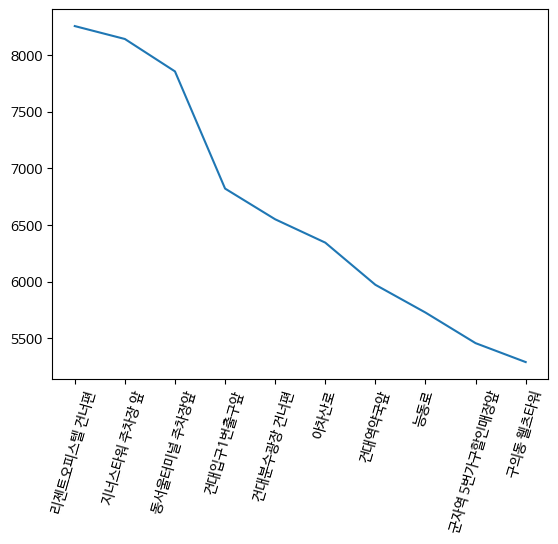

In [ ]:
plt.xticks(rotation=74)
plt.plot(chartdata1) #가장 간단한 기본 그림

Text(0.5, 1.0, '2015-2022년도의 불법주정차 단속 지점 top 10')

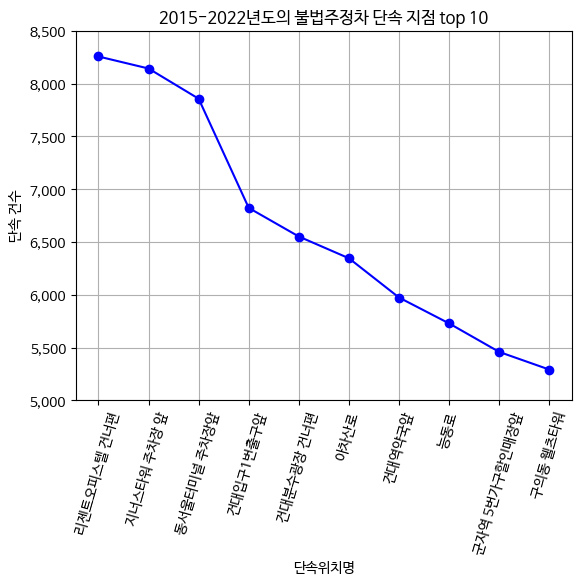

In [ ]:
#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 500
maxlim = (int(chartdata1.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(chartdata1, color='blue', linestyle='solid', marker='o')
values = np.arange(5000, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2015-2022년도의 불법주정차 단속 지점 top 10')

## 막대 그래프

<BarContainer object of 10 artists>

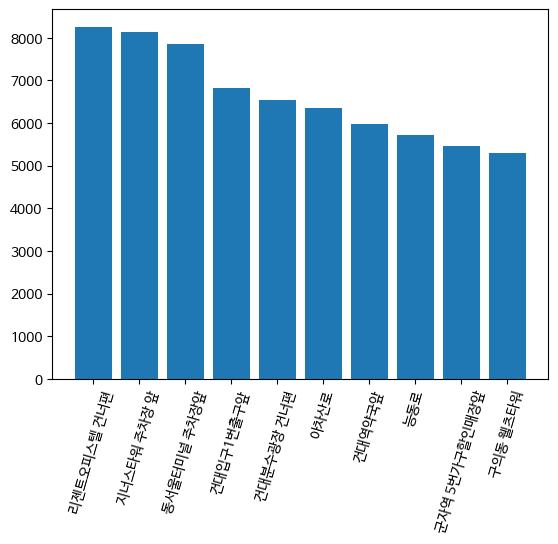

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata.index, chartdata) # 가장 기본이 되는 그래프

In [ ]:
# plt.bar() 메소드를 사용한 막대 그래프
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 500
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata.index, chartdata) # 가장 기본이 되는 그래프

# plt.bar() 메소드를 사용한 막대 그래프
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 500
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01


colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata)]


MakeBarChart01(x=chartdata.index, y=chartdata, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015-2022년도의 불법주정차 단속 지점 top 10')


In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata)]

8500
리젠트오피스텔 건너편      12.429617
지너스타워 주차장 앞      12.257987
동서울터미널 주차장앞      11.827407
건대입구1번출구앞        10.270693
건대분수광장 건너편        9.862696
아차산로              9.552558
건대역약국앞            8.992502
능동로               8.623649
군자역 5번가구할인매장앞     8.217157
구의동 웰츠타워          7.965734
Name: 단속장소, dtype: float64
6642.2


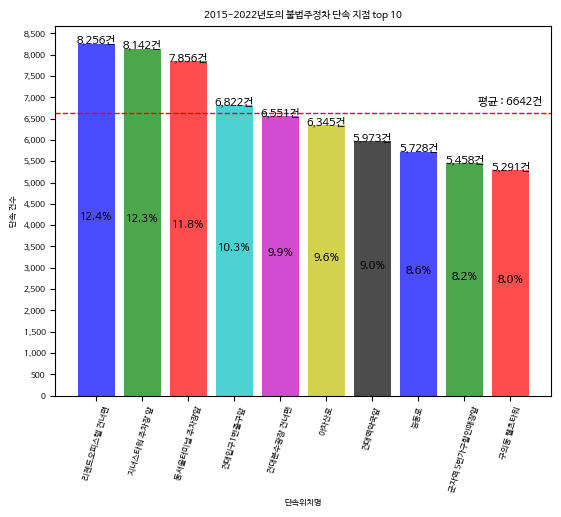

In [ ]:
MakeBarChart01(x=chartdata.index, y=chartdata, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015-2022년도의 불법주정차 단속 지점 top 10')


# 2.연도별로 가장 많이 단속하는 지점
동별로 많이 나옴 동
어떤 도로 유형이나 지역이 주로 단속 지점인지

In [ ]:
dfm

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시
0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리
1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인
3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인
...,...,...,...,...,...,...
39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인
39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인
39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인
39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인


## 연도별로 범주화하기

In [ ]:
def category_year(x):
    if x < '2016-%m-%d':
        return '2015'
    elif x < '2017-%m-%d':
        return '2016'
    elif x < '2018-%m-%d':
        return '2017'
    elif x < '2019-%m-%d':
        return '2018' 
    elif x < '2020-%m-%d':
        return '2019'   
    elif x < '2021-%m-%d':
        return '2020'
    elif x < '2022-%m-%d':
        return '2021'
    elif x < '2023-%m-%d':
        return '2022'
    else:
        return '2023'

In [ ]:
dfm['단속년도'] = dfm['단속일시'].apply(category_year) #이 열에다가 apply해라. 
print(dfm)

                      단속일시   단속원금  단속동               단속장소           위반내용  \
0         2015-01-01 06:44  40000  화양동              119-4          주정차금지   
1         2015-01-01 07:01  40000  화양동          건대입구1번출구앞    32조내지 34조위반   
2         2015-01-01 07:24  50000  구의동        동서울터미널 주차장앞    32조내지 34조위반   
3         2015-01-01 08:00  40000  화양동          건대입구1번출구앞    32조내지 34조위반   
4         2015-01-01 08:15  40000  화양동          건대입구1번출구앞    32조내지 34조위반   
...                    ...    ...  ...                ...            ...   
39727  2023-02-28 20:43:00  32000  군자동               군자빌딩  주정차금지(황색실선)구역   
39728  2023-02-28 21:23:00   8000  자양동  서울 광진구 자양동 659-32             보도   
39729  2023-02-28 21:38:00  32000  화양동     서울 광진구 능동로 154             보도   
39730  2023-02-28 22:36:00  32000  자양동   서울 광진구 자양동 12-10            교차로   
39731  2023-02-28 23:19:00  32000  자양동              02-02           횡단보도   

       견인지시  단속년도  
0      견인처리  2015  
1       미견인  2015  
2       미견인  2015  
3      

In [ ]:
dfm['단속년도'].info

<bound method Series.info of 0        2015
1        2015
2        2015
3        2015
4        2015
         ... 
39727    2023
39728    2023
39729    2023
39730    2023
39731    2023
Name: 단속년도, Length: 512806, dtype: object>

In [ ]:
chartdata_g = dfm.groupby('단속년도').value_counts()
chartdata_g

단속년도  단속일시                 단속원금   단속동  단속장소          위반내용           견인지시
2015  2015-08-25 20:08     40000  자양동  능동로           주정차위반          미견인     12
      2015-05-13 00:05     50000  구의동  동서울터미널        도로교통법 제32조     미견인     11
      2015-03-26 00:05     50000  구의동  동서울터미널        도로교통법 제32조     미견인     11
      2015-05-01 15:01     40000  중곡동  능동로           32조내지 34조위반    미견인     11
      2015-07-04 02:15     50000  구의동  동서울터미널        도로교통법 제32조     미견인     11
                                                                            ..
2023  2023-01-01 17:31:00  64000  광장동  453-7         특별구역           미견인      1
      2023-01-01 16:47:00  32000  구의동  지너스타워 주차장 앞   교통소통장애         미견인      1
      2023-01-01 16:25:00  40000  구의동  동서울터미널 주차장 앞  주정차금지(황색실선)구역  미견인      1
      2023-01-01 16:19:00  40000  중곡동  639-7         보도             미견인      1
      2023-02-28 23:19:00  32000  자양동  02-02         횡단보도           미견인      1
Length: 478395, dtype: int64

## 2015

In [ ]:
chartdata_2015 =dfm.loc[dfm['단속년도']== '2015']
chartdata_2015

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리,2015
1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인,2015
3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
...,...,...,...,...,...,...,...
67366,2015-12-31 20:46,40000,구의동,강변스파랜드앞,32조내지 34조위반,미견인,2015
67367,2015-12-31 21:08,40000,화양동,건대분수광장 건너편,32조내지 34조위반,미견인,2015
67368,2015-12-31 21:45,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인,2015
67369,2015-12-31 22:26,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인,2015


In [ ]:
chartdata_15 = chartdata_2015['단속장소'].value_counts().head(10)
chartdata_15

동서울터미널 주차장앞    3047
아차산로           2911
건대역약국앞         2776
건대입구1번출구앞      2667
능동로            2042
광나루로           1991
건대분수광장 건너편     1659
강변역1번출구        1370
리젠트오피스텔 건너편    1064
고신경정신과의원앞      1016
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata_15)

pandas.core.series.Series

In [ ]:
dchartdata_15 =pd.DataFrame(chartdata_15, columns=['단속장소'])
dchartdata_15

,단속장소
동서울터미널 주차장앞,3047
아차산로,2911
건대역약국앞,2776
건대입구1번출구앞,2667
능동로,2042
광나루로,1991
건대분수광장 건너편,1659
강변역1번출구,1370
리젠트오피스텔 건너편,1064
고신경정신과의원앞,1016


### 꺽은선 그래프

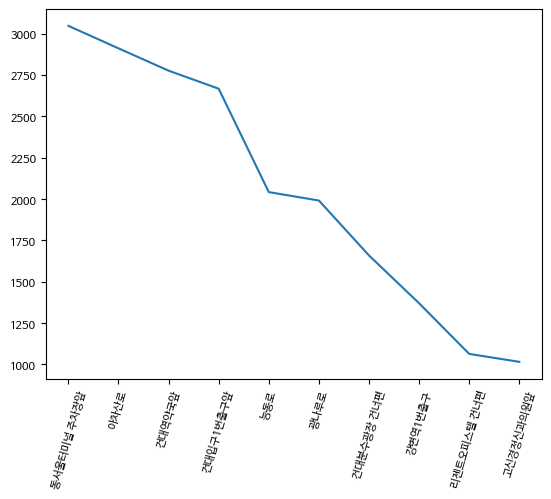

In [ ]:
plt.xticks(rotation=74)
plt.plot(dchartdata_15) #가장 간단한 기본 그림

Text(0.5, 1.0, '2015년도의 불법주정차 단속 지점 top 10')

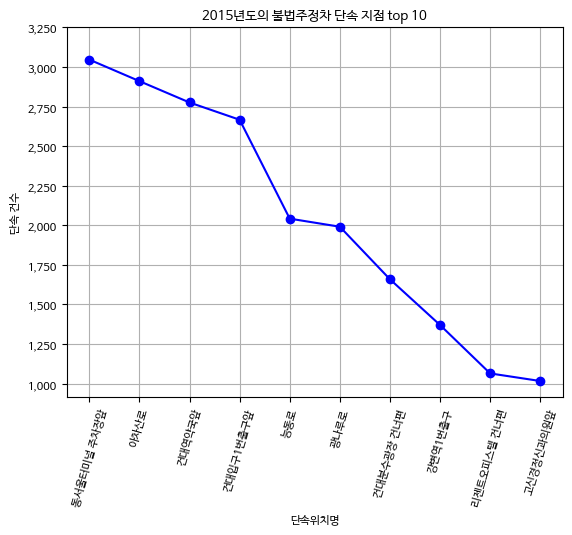

In [ ]:
#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 250
maxlim = (int(dchartdata_15.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_15, color='blue', linestyle='solid', marker='o')
values = np.arange(1000, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2015년도의 불법주정차 단속 지점 top 10')

### 막대그래프

<BarContainer object of 10 artists>

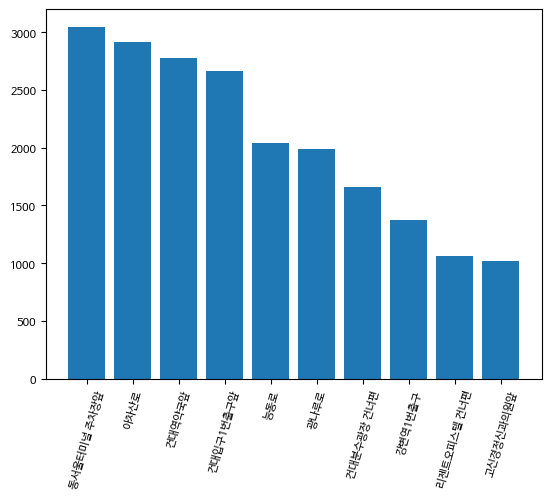

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata_15.index, chartdata_15) # 가장 기본이 되는 그래프

In [ ]:
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 250
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01


chartdata_2015 =dfm.loc[dfm['단속년도']== '2015']
chartdata_2015

chartdata_15 = chartdata_2015['단속장소'].value_counts().head(10)
chartdata_15

type (chartdata_15)

dchartdata_15 =pd.DataFrame(chartdata_15, columns=['단속장소'])
dchartdata_15


#<꺽은선 그래프>

plt.xticks(rotation=74)
plt.plot(dchartdata_15) #가장 간단한 기본 그림


#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 250
maxlim = (int(dchartdata_15.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_15, color='blue', linestyle='solid', marker='o')
values = np.arange(1000, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2015년도의 불법주정차 단속 지점 top 10')


#<막대그래프>

plt.xticks(rotation=74)
plt.bar(chartdata_15.index, chartdata_15) # 가장 기본이 되는 그래프



def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 250
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01


colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_15)]



MakeBarChart01(x=chartdata_15.index, y=chartdata_15, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015년도의 불법주정차 단속 지점 top 10')

In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_15)]

3250
동서울터미널 주차장앞    14.832303
아차산로           14.170277
건대역약국앞         13.513119
건대입구1번출구앞      12.982524
능동로             9.940126
광나루로            9.691866
건대분수광장 건너편      8.075744
강변역1번출구         6.668938
리젠트오피스텔 건너편     5.179380
고신경정신과의원앞       4.945724
Name: 단속장소, dtype: float64
2054.3


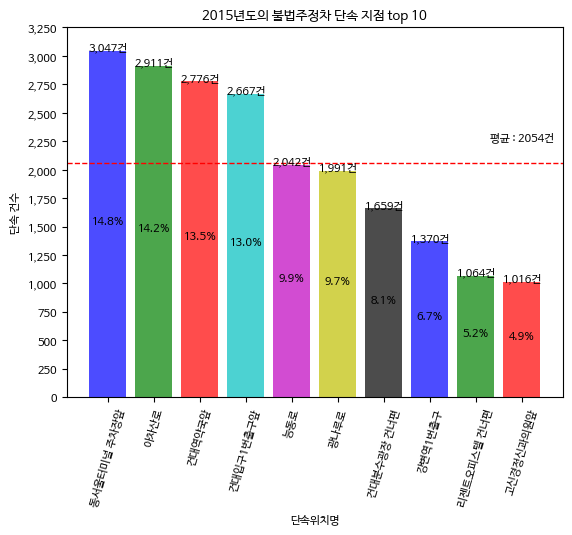

In [ ]:
MakeBarChart01(x=chartdata_15.index, y=chartdata_15, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015년도의 불법주정차 단속 지점 top 10')

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata.index, chartdata) # 가장 기본이 되는 그래프

# plt.bar() 메소드를 사용한 막대 그래프
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 500
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01


colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata)]


MakeBarChart01(x=chartdata.index, y=chartdata, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015-2022년도의 불법주정차 단속 지점 top 10')


## 2016

In [ ]:
chartdata_2016 =dfm.loc[dfm['단속년도']== '2016']
chartdata_2016

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
67371,2016-01-01 00:23,40000,화양동,건대역2번출구앞,도로교통법 제32조,미견인,2016
67372,2016-01-01 00:25,40000,화양동,건대역2번출구,도로교통법 제32조,미견인,2016
67373,2016-01-01 00:25,40000,화양동,건대역2번출구,도로교통법 제32조,미견인,2016
67374,2016-01-01 00:25,40000,구의동,건대역2번출구앞,도로교통법 제32조,미견인,2016
67375,2016-01-01 00:30,40000,화양동,건대역2번출구앞,도로교통법 제32조,미견인,2016
...,...,...,...,...,...,...,...
134987,2016-12-31 22:43,40000,화양동,114-5,주정차금지,견인처리,2016
134988,2016-12-31 22:47,40000,화양동,건대분수광장 건너편,32조내지 34조위반,미견인,2016
134989,2016-12-31 22:59,40000,화양동,건대분수광장 건너편,32조내지 34조위반,미견인,2016
134990,2016-12-31 23:32,40000,화양동,건대분수광장 건너편,32조내지 34조위반,미견인,2016


In [ ]:
chartdata_16 = chartdata_2016['단속장소'].value_counts().head(10)
chartdata_16

건대분수광장 건너편     1934
리젠트오피스텔 건너편    1894
동서울터미널 주차장앞    1446
구의동 웰츠타워       1295
동서울종합터미널        996
565             987
건대역약국앞          831
건대입구1번출구앞       831
570             824
아차산로            762
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata_16)

pandas.core.series.Series

In [ ]:
dchartdata_16 =pd.DataFrame(chartdata_16, columns=['단속장소'])
dchartdata_16

,단속장소
건대분수광장 건너편,1934
리젠트오피스텔 건너편,1894
동서울터미널 주차장앞,1446
구의동 웰츠타워,1295
동서울종합터미널,996
565,987
건대역약국앞,831
건대입구1번출구앞,831
570,824
아차산로,762


### 꺽은선 그래프

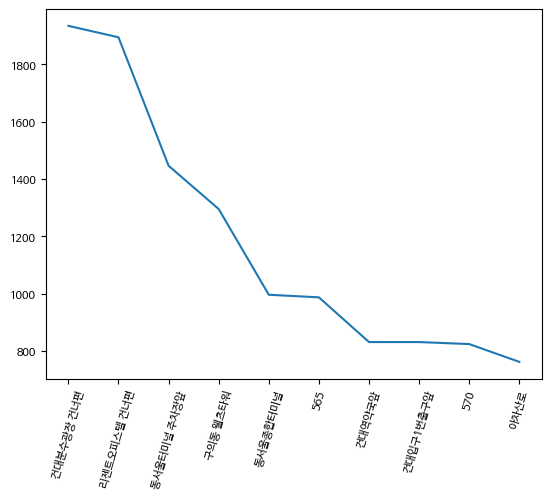

In [ ]:
plt.xticks(rotation=74)
plt.plot(dchartdata_16) #가장 간단한 기본 그림

Text(0.5, 1.0, '2016년도의 불법주정차 단속 지점 top 10')

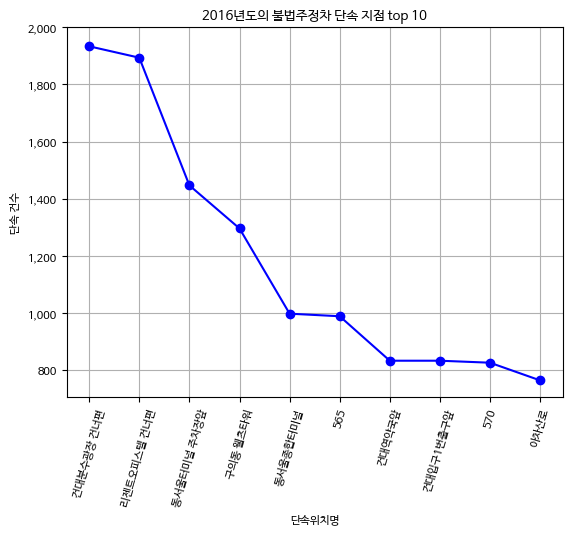

In [ ]:
#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 200
maxlim = (int(dchartdata_16.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_16, color='blue', linestyle='solid', marker='o')
values = np.arange(800, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2016년도의 불법주정차 단속 지점 top 10')

### 막대그래프

<BarContainer object of 10 artists>

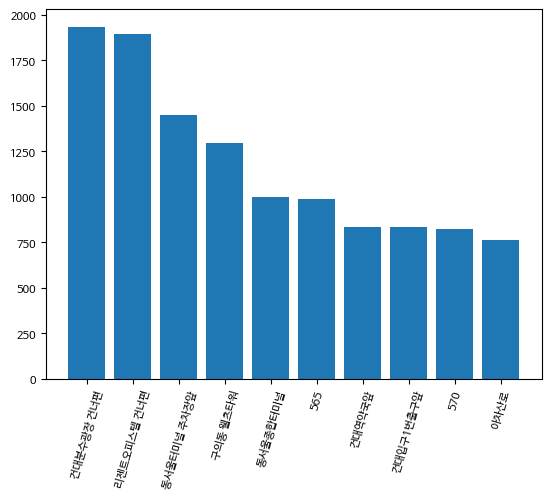

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata_16.index, chartdata_16) # 가장 기본이 되는 그래프

In [ ]:
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 200
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01

In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_16)]

2000
건대분수광장 건너편     16.389831
리젠트오피스텔 건너편    16.050847
동서울터미널 주차장앞    12.254237
구의동 웰츠타워       10.974576
동서울종합터미널        8.440678
565             8.364407
건대역약국앞          7.042373
건대입구1번출구앞       7.042373
570             6.983051
아차산로            6.457627
Name: 단속장소, dtype: float64
1180.0


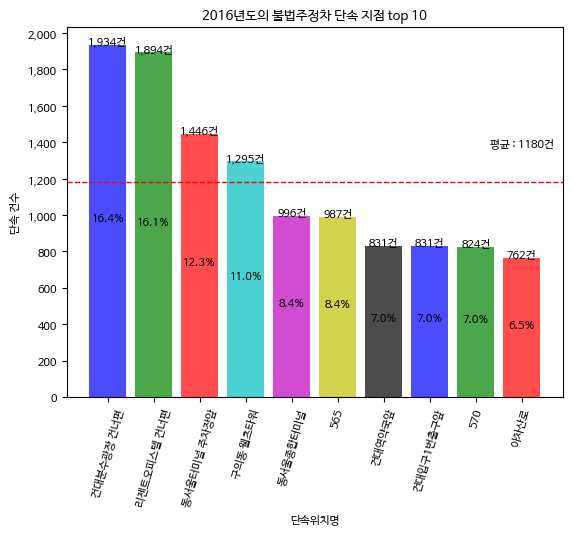

In [ ]:
MakeBarChart01(x=chartdata_16.index, y=chartdata_16, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2016년도의 불법주정차 단속 지점 top 10')

## 2017

In [ ]:
chartdata_2017 =dfm.loc[dfm['단속년도']== '2017']
chartdata_2017

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
134992,2017-01-01 00:40,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134993,2017-01-01 00:41,50000,구의동,구의강변로64,주정차금지,미견인,2017
134994,2017-01-01 00:41,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134995,2017-01-01 00:42,50000,구의동,동서울 일방통행로,주정차위반,미견인,2017
134996,2017-01-01 00:43,50000,구의동,동서울리젠트앞,주정차위반,미견인,2017
...,...,...,...,...,...,...,...
204978,2017-12-31 23:20,40000,군자동,능동로289앞,주차금지(황색점선)구역,미견인,2017
204979,2017-12-31 23:21,40000,군자동,능동로289앞,주차금지(황색점선)구역,미견인,2017
204980,2017-12-31 23:22,40000,군자동,능동로289앞,주차금지(황색점선)구역,미견인,2017
204981,2017-12-31 23:22,40000,군자동,능동로289앞,주차금지(황색점선)구역,미견인,2017


In [ ]:
chartdata_17 = chartdata_2017['단속장소'].value_counts().head(10)
chartdata_17

리젠트오피스텔 건너편      2324
동서울터미널 주차장앞      2280
건대분수광장 건너편       1725
구의동 웰츠타워         1714
지너스타워 주차장 앞      1659
군자역 5번가구할인매장앞    1149
두산위브 앞           1039
건대역약국앞           1016
군자역 1번명품갤러리앞     1000
건대입구1번출구앞         912
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata_17)

pandas.core.series.Series

In [ ]:
dchartdata_17 =pd.DataFrame(chartdata_17, columns=['단속장소'])
dchartdata_17

,단속장소
리젠트오피스텔 건너편,2324
동서울터미널 주차장앞,2280
건대분수광장 건너편,1725
구의동 웰츠타워,1714
지너스타워 주차장 앞,1659
군자역 5번가구할인매장앞,1149
두산위브 앞,1039
건대역약국앞,1016
군자역 1번명품갤러리앞,1000
건대입구1번출구앞,912


In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
dfl = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/위경도 변환.csv', encoding='CP949')
print(dfl)

           위도          경도              단속장소
0   37.532330  127.092934        리젠트오피스텔건너편
1   37.535500  127.093582         지너스타워주차장앞
2   37.540734  127.069262         건대입구1번출구앞
3   37.540762  127.067361            건대역약국앞
4   37.557633  127.088234             우리은행앞
..        ...         ...               ...
77  37.539081  127.100025  서울 광진구 광장동 486-1
78  37.550000  127.110620           아차산로78길
79  37.535500  127.092400             구의강변로
80  37.544830  127.099569          천호대로140길
81  37.538638  127.090169               431

[82 rows x 3 columns]


### 꺽은선 그래프

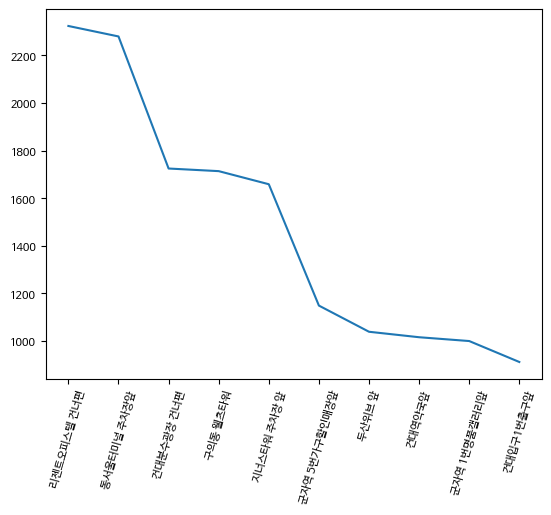

In [ ]:
plt.xticks(rotation=74)
plt.plot(dchartdata_17) #가장 간단한 기본 그림

Text(0.5, 1.0, '2017년도의 불법주정차 단속 지점 top 10')

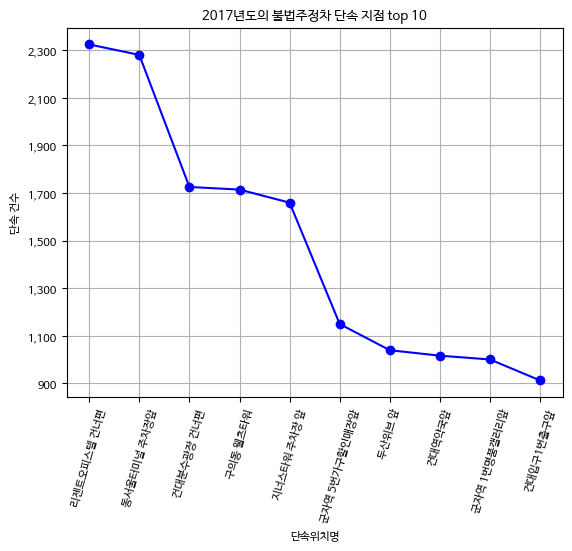

In [ ]:
#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 200
maxlim = (int(dchartdata_17.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_17, color='blue', linestyle='solid', marker='o')
values = np.arange(900, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2017년도의 불법주정차 단속 지점 top 10')

### 막대그래프

<BarContainer object of 10 artists>

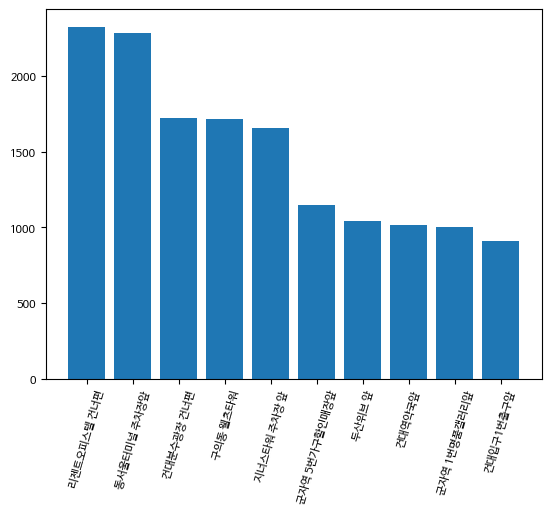

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata_17.index, chartdata_17) # 가장 기본이 되는 그래프

In [ ]:
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 200
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01

In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_17)]

2400
리젠트오피스텔 건너편      15.683628
동서울터미널 주차장앞      15.386692
건대분수광장 건너편       11.641247
구의동 웰츠타워         11.567013
지너스타워 주차장 앞      11.195843
군자역 5번가구할인매장앞     7.754083
두산위브 앞            7.011742
건대역약국앞            6.856526
군자역 1번명품갤러리앞      6.748549
건대입구1번출구앞         6.154677
Name: 단속장소, dtype: float64
1481.8


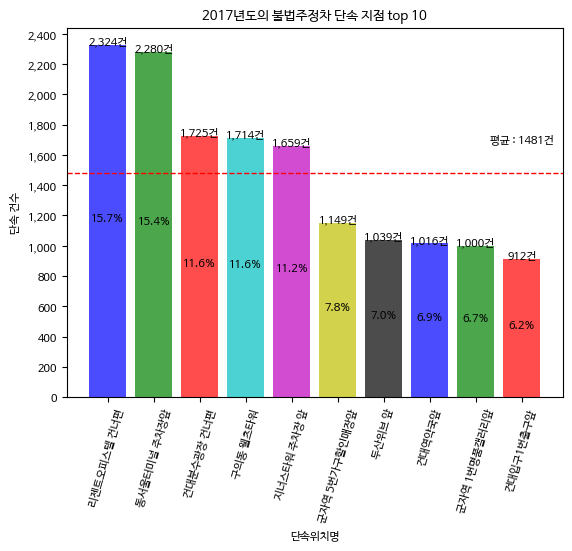

In [ ]:
MakeBarChart01(x=chartdata_17.index, y=chartdata_17, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2017년도의 불법주정차 단속 지점 top 10')

### 단속장소 시각화

In [ ]:
import folium

In [ ]:
import requests
import json

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

In [ ]:
m = folium.Map(
    location=[37.559819, 126.963895],
    zoom_start=11, 
    # 타일변경
    tiles='cartodbpositron'
)

folium.GeoJson(
    seoul_geo,
    name='지역구'
).add_to(m)

In [ ]:
bins = list(dcctv.quantile([0,0.25, 0.5, 0.75, 1]))
m.choropleth(geo_data=seoul_geo,
             data = dcctv,
             key_on='properties.name',
             bins = bins)

m  

## 2018

In [ ]:
chartdata_2018 =dfm.loc[dfm['단속년도']== '2018']
chartdata_2018

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
204983,2018-01-01 01:00,40000,광장동,강변북로,주차금지(황색점선)구역,미견인,2018
204984,2018-01-01 01:25,40000,구의동,자양로44길77,도로 모퉁이,미견인,2018
204985,2018-01-01 01:31,40000,중곡동,긴고랑126,횡단보도,미견인,2018
204986,2018-01-01 01:33,40000,중곡동,긴고랑126,횡단보도,미견인,2018
204987,2018-01-01 01:33,40000,중곡동,긴고랑126,횡단보도,미견인,2018
...,...,...,...,...,...,...,...
270611,2018-12-30 21:58,40000,자양동,건대역약국앞,주차금지(황색점선)구역,미견인,2018
270612,2018-12-30 23:29,40000,구의동,지너스타워 주차장 앞,주차금지(황색점선)구역,미견인,2018
270613,2018-12-30 23:33,40000,구의동,지너스타워 주차장 앞,주차금지(황색점선)구역,미견인,2018
270614,2018-12-31 13:50,40000,광장로1길,10,주차금지(황색점선)구역,미견인,2018


In [ ]:
chartdata_18 = chartdata_2018['단속장소'].value_counts().head(10)
chartdata_18

중곡지구대 앞          2106
MB모터스            1897
올포유 앞            1889
리젠트오피스텔 건너편      1819
우리은행 앞           1594
파리바게트앞           1488
지너스타워 주차장 앞      1401
건대입구1번출구앞        1386
강변스파랜드 앞         1164
군자역 5번가구할인매장앞    1124
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata_18)

pandas.core.series.Series

In [ ]:
dchartdata_18 =pd.DataFrame(chartdata_18, columns=['단속장소'])
dchartdata_18

,단속장소
중곡지구대 앞,2106
MB모터스,1897
올포유 앞,1889
리젠트오피스텔 건너편,1819
우리은행 앞,1594
파리바게트앞,1488
지너스타워 주차장 앞,1401
건대입구1번출구앞,1386
강변스파랜드 앞,1164
군자역 5번가구할인매장앞,1124


### 꺽은선 그래프

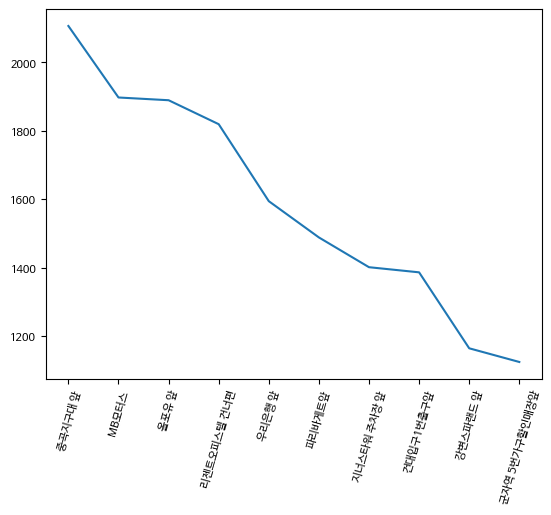

In [ ]:
plt.xticks(rotation=74)
plt.plot(dchartdata_18) #가장 간단한 기본 그림

Text(0.5, 1.0, '2018년도의 불법주정차 단속 지점 top 10')

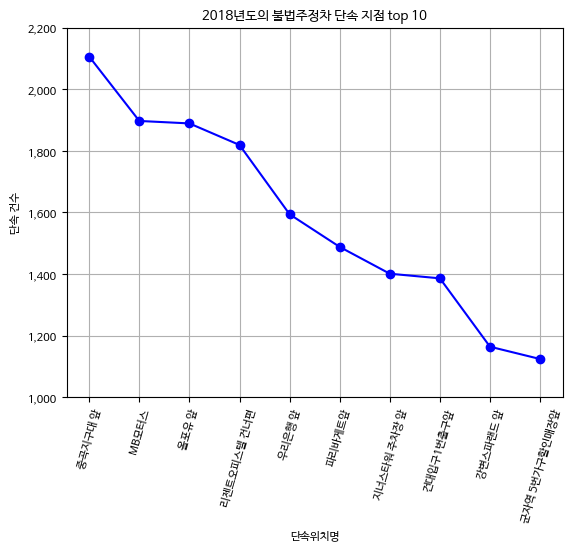

In [ ]:
#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 200
maxlim = (int(dchartdata_18.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_18, color='blue', linestyle='solid', marker='o')
values = np.arange(1000, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2018년도의 불법주정차 단속 지점 top 10')

### 막대그래프

<BarContainer object of 10 artists>

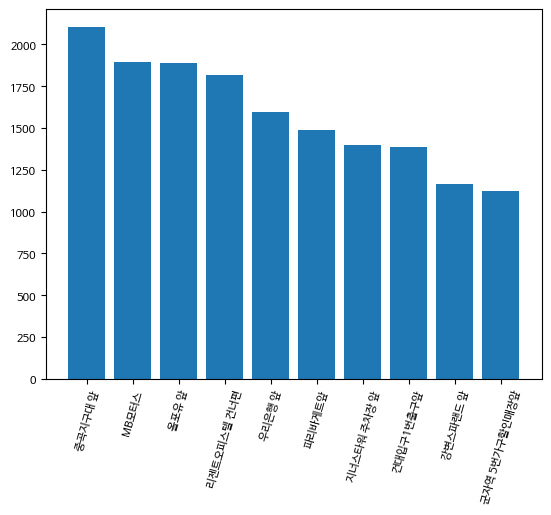

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata_18.index, chartdata_18) # 가장 기본이 되는 그래프

In [ ]:
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 250
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01

In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_18)]

2250
중곡지구대 앞          13.271994
MB모터스            11.954878
올포유 앞            11.904462
리젠트오피스텔 건너편      11.463322
우리은행 앞           10.045374
파리바게트앞            9.377363
지너스타워 주차장 앞       8.829090
건대입구1번출구앞         8.734560
강변스파랜드 앞          7.335518
군자역 5번가구할인매장앞     7.083438
Name: 단속장소, dtype: float64
1586.8


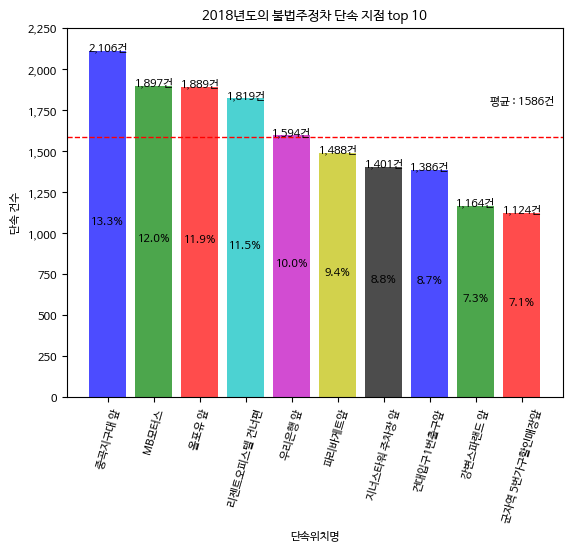

In [ ]:
MakeBarChart01(x=chartdata_18.index, y=chartdata_18, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2018년도의 불법주정차 단속 지점 top 10')

## 2019

In [ ]:
chartdata_2019 =dfm.loc[dfm['단속년도']== '2019']
chartdata_2019

,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
270616,2019-01-01 00:55,40000,뚝섬로62길,32-3 주차장앞,주차방법위반,미견인,2019
270617,2019-01-01 00:56,40000,뚝섬로62길,64 주차장앞,주차방법위반,미견인,2019
270618,2019-01-01 01:13,40000,동일로56라길,7 주차장앞,주차방법위반,미견인,2019
270619,2019-01-01 06:33,40000,군자로,186,주차방법위반,미견인,2019
270620,2019-01-01 07:00,40000,영화사로,77,횡단보도,미견인,2019
...,...,...,...,...,...,...,...
331892,2019-12-31 19:55,40000,능동,군자역 5번가구할인매장앞,주정차금지(황색실선)구역,미견인,2019
331893,2019-12-31 20:40,40000,능동,군자역 5번가구할인매장앞,주정차금지(황색실선)구역,미견인,2019
331894,2019-12-31 21:22,40000,능동,군자역 5번가구할인매장앞,주정차금지(황색실선)구역,미견인,2019
331895,2019-12-31 21:30,40000,중곡동,군자역 4번심서방앞,주정차금지(황색실선)구역,미견인,2019


In [ ]:
chartdata_19 = chartdata_2019['단속장소'].value_counts().head(10)
chartdata_19

리젠트오피스텔 건너편           1155
건대입구1번출구앞             1026
주차-009 지너스타워 주차장 앞     986
MB모터스                  971
주차-008 리젠트오피스텔 건너편     967
능동로                    927
중곡지구대 앞                926
아차산로                   879
군자역 5번가구할인매장앞          876
지너스타워 주차장 앞            720
Name: 단속장소, dtype: int64

In [ ]:
type (chartdata_19)

pandas.core.series.Series

In [ ]:
dchartdata_19 =pd.DataFrame(chartdata_19, columns=['단속장소'])
dchartdata_19

,단속장소
리젠트오피스텔 건너편,1155
건대입구1번출구앞,1026
주차-009 지너스타워 주차장 앞,986
MB모터스,971
주차-008 리젠트오피스텔 건너편,967
능동로,927
중곡지구대 앞,926
아차산로,879
군자역 5번가구할인매장앞,876
지너스타워 주차장 앞,720


### 꺽은선 그래프

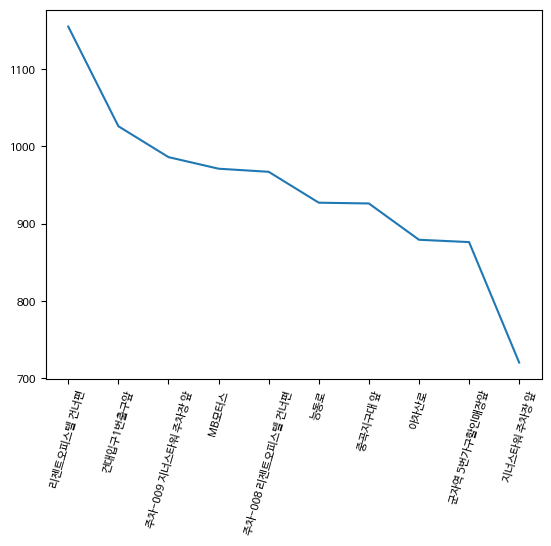

In [ ]:
plt.xticks(rotation=74)
plt.plot(dchartdata_19) #가장 간단한 기본 그림

Text(0.5, 1.0, '2019년도의 불법주정차 단속 지점 top 10')

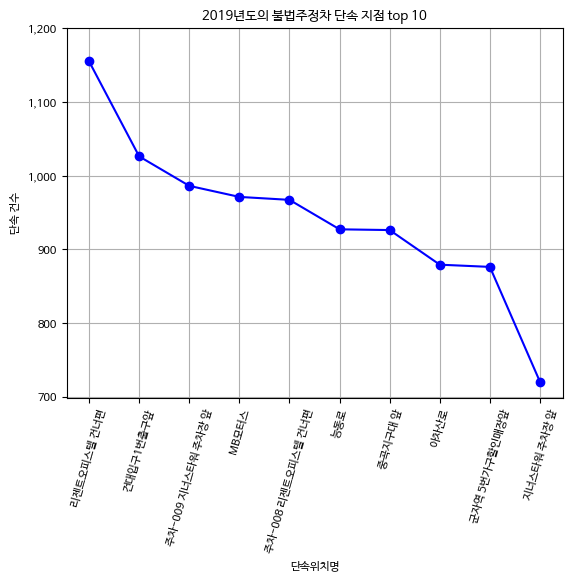

In [ ]:
YTICKS_INTERVAL = 100
maxlim = (int(dchartdata_19.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_19, color='blue', linestyle='solid', marker='o')
values = np.arange(700, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2019년도의 불법주정차 단속 지점 top 10')

### 막대그래프

<BarContainer object of 10 artists>

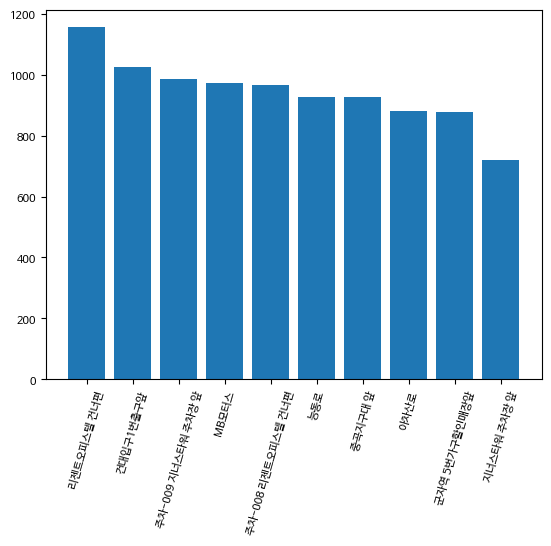

In [ ]:
plt.xticks(rotation=74)
plt.bar(chartdata_19.index, chartdata_19) # 가장 기본이 되는 그래프

In [ ]:
def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 200
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01

In [ ]:
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_19)]

1200
리젠트오피스텔 건너편           12.244249
건대입구1번출구앞             10.876709
주차-009 지너스타워 주차장 앞    10.452666
MB모터스                 10.293650
주차-008 리젠트오피스텔 건너편    10.251246
능동로                    9.827202
중곡지구대 앞                9.816601
아차산로                   9.318350
군자역 5번가구할인매장앞          9.286547
지너스타워 주차장 앞            7.632779
Name: 단속장소, dtype: float64
943.3


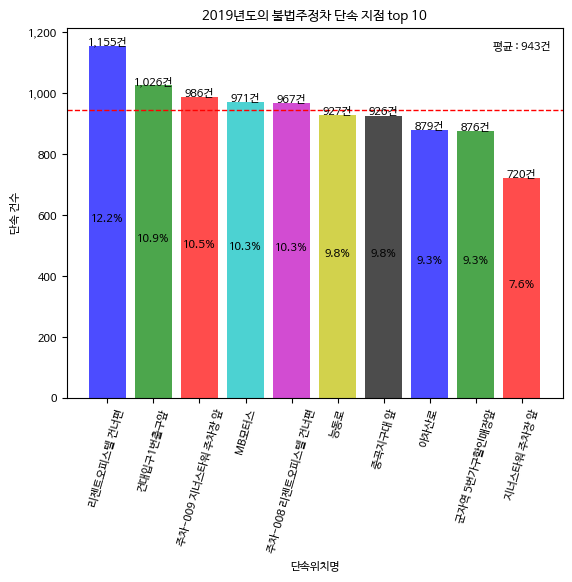

In [ ]:
MakeBarChart01(x=chartdata_19.index, y=chartdata_19, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2019년도의 불법주정차 단속 지점 top 10')

## 2020

In [ ]:
chartdata_2015 =dfm.loc[dfm['단속년도']== '2015']
chartdata_2015

chartdata_15 = chartdata_2015['단속장소'].value_counts().head(10)
chartdata_15

type (chartdata_15)

dchartdata_15 =pd.DataFrame(chartdata_15, columns=['단속장소'])
dchartdata_15


### 꺽은선 그래프

plt.xticks(rotation=74)
plt.plot(dchartdata_15) #가장 간단한 기본 그림


#위에서 추가적으로 더 준 그래프 
#추가 옵션 코드가 2주차_1 pppt에  나와있다.
YTICKS_INTERVAL = 250
maxlim = (int(dchartdata_15.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
plt.xticks(rotation=74)
plt.plot(dchartdata_15, color='blue', linestyle='solid', marker='o')
values = np.arange(1000, maxlim + 1, YTICKS_INTERVAL)
plt.yticks(values, ['%s' % format(val, ',') for val in values]) #천 단위에 , 찍어라.
plt.grid(True) #그리드
plt.xlabel('단속위치명')

plt.ylabel("단속 건수")
plt.title('2015년도의 불법주정차 단속 지점 top 10')


### 막대그래프

plt.xticks(rotation=74)
plt.bar(chartdata_15.index, chartdata_15) # 가장 기본이 되는 그래프



def MakeBarChart01(x, y, color, xlabel, ylabel, title):
    plt.figure() #그릴 영역 생성
    plt.xticks(rotation=74)
    plt.bar(x, y, color=color, alpha=0.7)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    # plt.grid(True)

    YTICKS_INTERVAL = 250
    
    maxlim = (int(y.max() / YTICKS_INTERVAL) + 1) * YTICKS_INTERVAL
    print(maxlim)

    values = np.arange(0, maxlim + 1, YTICKS_INTERVAL)

    plt.yticks(values, ['%s' % format(val, ',') for val in values])

    

    # 그래프 위에 건수와 비율 구하기
    ratio = 100 * y / y.sum()
    print(ratio)
    

    plt.rc('font', size=8)
    for idx in range(y.size):
        value = format(y[idx], ',') + '건'  # 예시 : 60건
        ratioval = '%.1f%%' % (ratio[idx])  # 예시 : 20.0%
        # 그래프의 위에 "건수" 표시
        plt.text(x=idx, y=y[idx] + 1, s=value, horizontalalignment='center')
        # 그래프의 중간에 비율 표시
        plt.text(x=idx, y=y[idx] / 2, s=ratioval, horizontalalignment='center')

    # 평균 값을 수평선으로 그리기
    meanval = y.mean()
    print(meanval)

    average = '평균 : %d건' % meanval
    plt.axhline(y=meanval, color='r', linewidth=1, linestyle='dashed')
    plt.text(x=y.size - 1, y=meanval + 200, s=average, horizontalalignment='center')

# def MakeBarChart01


colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k'] # 이 순서로 mycolor에 맵핑하고 싶을때
mycolor = colors[0:len(chartdata_15)]



MakeBarChart01(x=chartdata_15.index, y=chartdata_15, color= mycolor, xlabel='단속위치명', 
               ylabel="단속 건수", title='2015년도의 불법주정차 단속 지점 top 10')

## 3.불법 주정차 단속 위치 시각화하기

car_enf_2020 =car_enf.loc[dfm['단속년도']== '2020']
car_enf_2020

df_2020 = pd.DataFrame(car_enf_2020['단속장소'].value_counts()).reset_index()
df_2020 = df_2020 [:100]
df_2020.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2020=pd.DataFrame(df_2020)

df_2020

##### 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_20 = pd.merge(df_2020, dfl)
car_enf_20

m = folium.Map(
    location=[car_enf_20.위도.mean(), car_enf_20.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_20.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임
m

In [ ]:
dfm

,Unnamed: 0,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
0,0,2015-01-01 06:44,40000,화양동,119-4,주정차금지,견인처리,2015
1,1,2015-01-01 07:01,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
2,2,2015-01-01 07:24,50000,구의동,동서울터미널 주차장앞,32조내지 34조위반,미견인,2015
3,3,2015-01-01 08:00,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
4,4,2015-01-01 08:15,40000,화양동,건대입구1번출구앞,32조내지 34조위반,미견인,2015
...,...,...,...,...,...,...,...,...
512801,39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인,2023
512802,39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인,2023
512803,39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인,2023
512804,39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인,2023


In [ ]:
ddfm #2017년 이후의 연도만 추출

,Unnamed: 0,단속일시,단속원금,단속동,단속장소,위반내용,견인지시,단속년도
134992,134992,2017-01-01 00:40,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134993,134993,2017-01-01 00:41,50000,구의동,구의강변로64,주정차금지,미견인,2017
134994,134994,2017-01-01 00:41,50000,구의동,동서울일방통행로,주정차위반,미견인,2017
134995,134995,2017-01-01 00:42,50000,구의동,동서울 일방통행로,주정차위반,미견인,2017
134996,134996,2017-01-01 00:43,50000,구의동,동서울리젠트앞,주정차위반,미견인,2017
...,...,...,...,...,...,...,...,...
512801,39727,2023-02-28 20:43:00,32000,군자동,군자빌딩,주정차금지(황색실선)구역,미견인,2023
512802,39728,2023-02-28 21:23:00,8000,자양동,서울 광진구 자양동 659-32,보도,미견인,2023
512803,39729,2023-02-28 21:38:00,32000,화양동,서울 광진구 능동로 154,보도,미견인,2023
512804,39730,2023-02-28 22:36:00,32000,자양동,서울 광진구 자양동 12-10,교차로,미견인,2023


In [ ]:
# 단속동과 단속장소,단속년도와 단속일시만 뽑아온다. 

ddfm1=ddfm[['단속년도','단속일시','단속동','단속장소']]
ddfm1

,단속년도,단속일시,단속동,단속장소
134992,2017,2017-01-01 00:40,구의동,동서울일방통행로
134993,2017,2017-01-01 00:41,구의동,구의강변로64
134994,2017,2017-01-01 00:41,구의동,동서울일방통행로
134995,2017,2017-01-01 00:42,구의동,동서울 일방통행로
134996,2017,2017-01-01 00:43,구의동,동서울리젠트앞
...,...,...,...,...
512801,2023,2023-02-28 20:43:00,군자동,군자빌딩
512802,2023,2023-02-28 21:23:00,자양동,서울 광진구 자양동 659-32
512803,2023,2023-02-28 21:38:00,화양동,서울 광진구 능동로 154
512804,2023,2023-02-28 22:36:00,자양동,서울 광진구 자양동 12-10


In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
dfl = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/위경도 변환.csv', encoding='CP949')
print(dfl)

           위도          경도              단속장소
0   37.532330  127.092934        리젠트오피스텔건너편
1   37.535500  127.093582         지너스타워주차장앞
2   37.540734  127.069262         건대입구1번출구앞
3   37.540762  127.067361            건대역약국앞
4   37.557633  127.088234             우리은행앞
..        ...         ...               ...
77  37.539081  127.100025  서울 광진구 광장동 486-1
78  37.550000  127.110620           아차산로78길
79  37.535500  127.092400             구의강변로
80  37.544830  127.099569          천호대로140길
81  37.538638  127.090169               431

[82 rows x 3 columns]


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf = pd.merge(ddfm1, dfl, how='left', on='단속장소')
car_enf

,단속년도,단속일시,단속동,단속장소,위도,경도
0,2017,2017-01-01 00:40,구의동,동서울일방통행로,NaN,NaN
1,2017,2017-01-01 00:41,구의동,구의강변로64,NaN,NaN
2,2017,2017-01-01 00:41,구의동,동서울일방통행로,NaN,NaN
3,2017,2017-01-01 00:42,구의동,동서울 일방통행로,NaN,NaN
4,2017,2017-01-01 00:43,구의동,동서울리젠트앞,NaN,NaN
...,...,...,...,...,...,...
384260,2023,2023-02-28 20:43:00,군자동,군자빌딩,NaN,NaN
384261,2023,2023-02-28 21:23:00,자양동,서울 광진구 자양동 659-32,NaN,NaN
384262,2023,2023-02-28 21:38:00,화양동,서울 광진구 능동로 154,NaN,NaN
384263,2023,2023-02-28 22:36:00,자양동,서울 광진구 자양동 12-10,NaN,NaN


#### 2017 단속장소 시각화

In [ ]:
#2017년의 주요 단속장소
car_enf_2017 =car_enf.loc[car_enf['단속년도']== '2017']
car_enf_2017

,단속년도,단속일시,단속동,단속장소,위도,경도
0,2017,2017-01-01 00:40,구의동,동서울일방통행로,NaN,NaN
1,2017,2017-01-01 00:41,구의동,구의강변로64,NaN,NaN
2,2017,2017-01-01 00:41,구의동,동서울일방통행로,NaN,NaN
3,2017,2017-01-01 00:42,구의동,동서울 일방통행로,NaN,NaN
4,2017,2017-01-01 00:43,구의동,동서울리젠트앞,NaN,NaN
...,...,...,...,...,...,...
72127,2017,2017-12-31 23:20,군자동,능동로289앞,NaN,NaN
72128,2017,2017-12-31 23:21,군자동,능동로289앞,NaN,NaN
72129,2017,2017-12-31 23:22,군자동,능동로289앞,NaN,NaN
72130,2017,2017-12-31 23:22,군자동,능동로289앞,NaN,NaN


In [ ]:
df_2017 = pd.DataFrame(car_enf_2017['단속장소'].value_counts()).reset_index()
df_2017 = df_2017 [:100]
df_2017=df_2017['index']
df_2017=pd.DataFrame(df_2017)
df_2017

,index
0,리젠트오피스텔 건너편
1,동서울터미널 주차장앞
2,건대역약국앞
3,건대입구1번출구앞
4,건대분수광장 건너편
...,...
95,546-1
96,건대역1번2사이
97,용마초교길
98,드림디포옆


In [ ]:
df_2017.rename(columns = {'index':'단속장소'}, inplace=True)
df_2017

,단속장소
0,리젠트오피스텔 건너편
1,동서울터미널 주차장앞
2,건대역약국앞
3,건대입구1번출구앞
4,건대분수광장 건너편
...,...
95,546-1
96,건대역1번2사이
97,용마초교길
98,드림디포옆


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_17 = pd.merge(df_2017, dfl)
car_enf_17

,단속장소,위도,경도
0,건대역약국앞,37.540762,127.067361
1,건대역약국앞,37.540771,127.067372
2,건대입구1번출구앞,37.540734,127.069262
3,건대입구1번출구앞,37.540797,127.068967
4,강변역 1번출구,37.535157,127.094646
5,565,37.541794,127.098965
6,631-1,37.538767,127.098339
7,570,37.543736,127.092495
8,파리바게트앞,37.532199,127.079078
9,능동로,37.561152,127.081390


In [ ]:
import requests
import json

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)
seoul_geo

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'properties': {'code': '11250',
    'name': '강동구',
    'name_eng': 'Gangdong-gu',
    'base_year': '2013'},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[127.11519584981606, 37.557533180704915],
      [127.11879551821994, 37.557222485451305],
      [127.12146867175024, 37.55986003393365],
      [127.12435254630417, 37.56144246249796],
      [127.13593925898998, 37.56564793048277],
      [127.14930548011061, 37.56892250303897],
      [127.15511020940411, 37.57093642128295],
      [127.16683184366129, 37.57672487388627],
      [127.17038810813094, 37.576465605301046],
      [127.17607118428914, 37.57678573961056],
      [127.17905504160184, 37.57791388161732],
      [127.17747787800164, 37.57448983055031],
      [127.1781775408844, 37.571481967974336],
      [127.17995281860672, 37.569309661290504],
      [127.18122821955262, 37.56636089217979],
      [127.18169407550688, 37.56286338914073],
      [127.18408792

In [ ]:
car_enf_17  #뽑은것중에 32개만 해당되었따..

,단속장소,위도,경도
0,건대역약국앞,37.540762,127.067361
1,건대역약국앞,37.540771,127.067372
2,건대입구1번출구앞,37.540734,127.069262
3,건대입구1번출구앞,37.540797,127.068967
4,강변역 1번출구,37.535157,127.094646
5,565,37.541794,127.098965
6,631-1,37.538767,127.098339
7,570,37.543736,127.092495
8,파리바게트앞,37.532199,127.079078
9,능동로,37.561152,127.081390


In [ ]:
m = folium.Map(
    location=[car_enf_17.위도.mean(), car_enf_17.경도.mean()],
    zoom_start=14,
    control_scale=True
)
m

In [ ]:
for index, location_info in car_enf_17.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속장소"]).add_to(m) # 클릭하면 이름이 보임
m

#### 2018 단속장소 시각화

In [ ]:
#2018년의 주요 단속장소
car_enf_2018 =car_enf.loc[car_enf['단속년도']== '2018']
car_enf_2018

,단속년도,단속일시,단속동,단속장소,위도,경도
72132,2018,2018-01-01 01:00,광장동,강변북로,NaN,NaN
72133,2018,2018-01-01 01:25,구의동,자양로44길77,NaN,NaN
72134,2018,2018-01-01 01:31,중곡동,긴고랑126,NaN,NaN
72135,2018,2018-01-01 01:33,중곡동,긴고랑126,NaN,NaN
72136,2018,2018-01-01 01:33,중곡동,긴고랑126,NaN,NaN
...,...,...,...,...,...,...
140122,2018,2018-12-30 21:58,자양동,건대역약국앞,37.540771,127.067372
140123,2018,2018-12-30 23:29,구의동,지너스타워 주차장 앞,NaN,NaN
140124,2018,2018-12-30 23:33,구의동,지너스타워 주차장 앞,NaN,NaN
140125,2018,2018-12-31 13:50,광장로1길,10,NaN,NaN


In [ ]:
df_2018 = pd.DataFrame(car_enf_2018['단속장소'].value_counts()).reset_index()
df_2018 = df_2018 [:100]
df_2018.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2018=pd.DataFrame(df_2018)

df_2018

,단속장소,단속횟수
0,건대입구1번출구앞,2772
1,중곡지구대 앞,2106
2,MB모터스,1897
3,올포유 앞,1889
4,리젠트오피스텔 건너편,1819
...,...,...
95,361-26 홍콩반점,104
96,361,103
97,18,102
98,244,100


In [ ]:
df_2018 = pd.DataFrame(car_enf_2018['단속장소'].value_counts()).reset_index()
df_2018 = df_2018 [:100]
df_2018=df_2018['index']
df_2018=pd.DataFrame(df_2018)
df_2018.rename(columns = {'index':'단속장소'}, inplace=True)
df_2018

,단속장소
0,건대입구1번출구앞
1,중곡지구대 앞
2,MB모터스
3,올포유 앞
4,리젠트오피스텔 건너편
...,...
95,361-26 홍콩반점
96,361
97,18
98,244


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_18 = pd.merge(df_2018, dfl)
car_enf_18

,단속장소,위도,경도
0,건대입구1번출구앞,37.540734,127.069262
1,건대입구1번출구앞,37.540797,127.068967
2,중곡지구대 앞,37.560133,127.081457
3,MB모터스,37.563478,127.078246
4,올포유 앞,37.556948,127.088301
5,파리바게트앞,37.532199,127.079078
6,건대역약국앞,37.540762,127.067361
7,건대역약국앞,37.540771,127.067372
8,모두투어 앞,37.547563,127.106973
9,강변역 1번출구,37.535157,127.094646


In [ ]:
m = folium.Map(
    location=[car_enf_18.위도.mean(), car_enf_18.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_18.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"]).add_to(m) # 클릭하면 이름이 보임
m

#### 2019 단속장소 시각화

In [ ]:
car_enf_2019 =car_enf.loc[car_enf['단속년도']=='2019']
car_enf_2019

,단속년도,단속일시,단속동,단속장소,위도,경도
140127,2019,2019-01-01 00:55,뚝섬로62길,32-3 주차장앞,NaN,NaN
140128,2019,2019-01-01 00:56,뚝섬로62길,64 주차장앞,NaN,NaN
140129,2019,2019-01-01 01:13,동일로56라길,7 주차장앞,NaN,NaN
140130,2019,2019-01-01 06:33,군자로,186,NaN,NaN
140131,2019,2019-01-01 07:00,영화사로,77,NaN,NaN
...,...,...,...,...,...,...
203351,2019,2019-12-31 19:55,능동,군자역 5번가구할인매장앞,NaN,NaN
203352,2019,2019-12-31 20:40,능동,군자역 5번가구할인매장앞,NaN,NaN
203353,2019,2019-12-31 21:22,능동,군자역 5번가구할인매장앞,NaN,NaN
203354,2019,2019-12-31 21:30,중곡동,군자역 4번심서방앞,37.556908,127.081171


In [ ]:
df_2019 = pd.DataFrame(car_enf_2019['단속장소'].value_counts()).reset_index()
df_2019 = df_2019 [:100]
df_2019.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2019=pd.DataFrame(df_2019)

df_2019

,단속장소,단속횟수
0,건대입구1번출구앞,2052
1,건대역약국앞,1342
2,리젠트오피스텔 건너편,1155
3,주차-009 지너스타워 주차장 앞,986
4,MB모터스,971
...,...,...
95,군자 CGV 앞,149
96,40,148
97,3,148
98,85,147


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_19 = pd.merge(df_2019, dfl)
car_enf_19

,단속장소,단속횟수,위도,경도
0,건대입구1번출구앞,2052,37.540734,127.069262
1,건대입구1번출구앞,2052,37.540797,127.068967
2,건대역약국앞,1342,37.540762,127.067361
3,건대역약국앞,1342,37.540771,127.067372
4,MB모터스,971,37.563478,127.078246
5,능동로,927,37.561152,127.081390
6,중곡지구대 앞,926,37.560133,127.081457
7,아차산로,879,37.540302,127.094991
8,긴고랑로,677,37.560852,127.084480
9,동일로18길,598,37.539132,127.066250


In [ ]:
m = folium.Map(
    location=[car_enf_19.위도.mean(), car_enf_19.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_19.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임
m

#### 2020 단속장소 시각화

In [ ]:
car_enf_2020 =car_enf.loc[car_enf['단속년도']== '2020']
car_enf_2020

,단속년도,단속일시,단속동,단속장소,위도,경도
203356,2020,2020-01-01 00:05,군자로,152,NaN,NaN
203357,2020,2020-01-01 00:18,아차산로,334,NaN,NaN
203358,2020,2020-01-01 00:23,뚝섬로58가길,20 주차장막음,NaN,NaN
203359,2020,2020-01-01 00:33,자양번영로3나길,35 주차장앞,NaN,NaN
203360,2020,2020-01-01 00:45,동일로12길,28,NaN,NaN
...,...,...,...,...,...,...
263896,2020,2020-12-31 23:42,화양동,건대입구 1번 출구 앞,NaN,NaN
263897,2020,2020-12-31 23:43,화양동,건대입구 1번 출구 앞,NaN,NaN
263898,2020,2020-12-31 23:43,구의동,서울특별시 광진구 자양로22길 8,NaN,NaN
263899,2020,2020-12-31 23:47,자양동,서울특별시 광진구 자양로 131,NaN,NaN


In [ ]:
df_2020 = pd.DataFrame(car_enf_2020['단속장소'].value_counts()).reset_index()
df_2020 = df_2020 [:100]
df_2020.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2020=pd.DataFrame(df_2020)

df_2020

,단속장소,단속횟수
0,건대역약국 앞,1455
1,건대입구 1번 출구 앞,1364
2,지너스타워 주차장 앞,1049
3,MB모터스 옆,896
4,리젠트오피스텔건너편,869
...,...,...
95,10,99
96,11,99
97,공원약국 앞,99
98,서울 광진구 자양동 2-7,98


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_20 = pd.merge(df_2020, dfl)
car_enf_20

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,869,37.532330,127.092934
1,중곡지구대 앞,800,37.560133,127.081457
2,자양번영로,673,37.530693,127.074683
3,능동로,605,37.561152,127.081390
4,동일로18길,577,37.539132,127.066250
5,올포유 앞,570,37.556948,127.088301
6,아차산로,527,37.540302,127.094991
7,강변역 4번 출구,394,37.535365,127.094521
8,건대입구 3번 출구 앞,392,37.540651,127.071389
9,긴고랑로,384,37.560852,127.084480


In [ ]:
m = folium.Map(
    location=[car_enf_20.위도.mean(), car_enf_20.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_20.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임
m

In [ ]:
m.save('2020불법주정차 단속.html')
m

#### 2021 단속장소 시각화

In [ ]:
car_enf_2021 =car_enf.loc[car_enf['단속년도']== '2021']
car_enf_2021

,단속년도,단속일시,단속동,단속장소,위도,경도
263901,2021,2021-01-01 01:28,중곡동,서울 광진구 중곡동 296-29 주차장앞,NaN,NaN
263902,2021,2021-01-01 02:21,구의동,서울 광진구 구의로 22-1,NaN,NaN
263903,2021,2021-01-01 02:26,중곡동,서울 광진구 중곡동 438-3,NaN,NaN
263904,2021,2021-01-01 03:01,자양동,서울 광진구 중곡동 438-3,NaN,NaN
263905,2021,2021-01-01 03:05,자양동,서울 광진구 뚝섬로 492,NaN,NaN
...,...,...,...,...,...,...
322653,2021,2021-12-31 22:12,화양동,서울 광진구 화양동 46-22 주차장앞,NaN,NaN
322654,2021,2021-12-31 22:15,화양동,서울 광진구 화양동 46-22 주차장앞,NaN,NaN
322655,2021,2021-12-31 22:42,군자동,서울 광진구 군자동 29-65,NaN,NaN
322656,2021,2021-12-31 22:46,군자동,서울 광진구 군자동 45-41,NaN,NaN


In [ ]:
df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts()).reset_index()
df_2021 = df_2021 [:100]
df_2021.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2021=pd.DataFrame(df_2021)

df_2021

,단속장소,단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
95,서울 광진구 능동 280-1,71
96,서울 광진구 광장동 381-73,71
97,성자초등학교 옆,69
98,영화사로,68


In [ ]:
#df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts()).reset_index()
#df_2021.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
#df_2021['단속횟수']=pd.to_numeric(df_2021['단속횟수'])
#df_2021_100 = df_2021.loc[df_2021['단속횟수']>= 100]

#df_2021_100

,단속장소,단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
58,서울 광진구 광장동 383-16,112
59,서울 광진구 광장동 320-4,111
60,서울 광진구 자양동 550-2,110
61,어린이대공원 정문,107


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_21 = pd.merge(df_2021, dfl)
car_enf_21

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,1481,37.532330,127.092934
1,동서울터미널 주차장 앞,677,37.533969,127.093637
2,올포유 앞,617,37.556948,127.088301
3,강변 스파랜드 앞,570,37.534971,127.091240
4,중곡지구대 앞,559,37.560133,127.081457
5,강변역 4번 출구,538,37.535365,127.094521
6,중곡문화체육센터 앞,528,37.567763,127.084918
7,건대입구 3번 출구 앞,467,37.540651,127.071389
8,동일로18길,418,37.539132,127.066250
9,이튼타워리버3차 앞,415,37.532977,127.068044


In [ ]:
m = folium.Map(
    location=[car_enf_21.위도.mean(), car_enf_21.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_21.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임
m

m.save('2021불법주정차 단속.html')
m

#### 2022 단속장소 시각화

In [ ]:
car_enf_2022 =car_enf.loc[car_enf['단속년도']== '2022']
car_enf_2022

,단속년도,단속일시,단속동,단속장소,위도,경도
322658,2022,2022-01-01 02:29,중곡동,서울특별시 광진구 영화사로5길 19,NaN,NaN
322659,2022,2022-01-01 06:41,중곡동,150-196,NaN,NaN
322660,2022,2022-01-01 07:02,구의동,서울 광진구 구의동 660-1 주차장앞,NaN,NaN
322661,2022,2022-01-01 07:29,구의동,서울 광진구 구의동 6-4,NaN,NaN
322662,2022,2022-01-01 10:55,구의동,리젠트오피스텔건너편,37.532330,127.092934
...,...,...,...,...,...,...
380229,2022,2022-12-31 21:24:00,구의동,동서울터미널 주차장 앞,37.533969,127.093637
380230,2022,2022-12-31 21:34:00,화양동,건대입구 1번 출구 앞,NaN,NaN
380231,2022,2022-12-31 22:14:00,중곡동,263-1,NaN,NaN
380232,2022,2022-12-31 22:52:00,광장동,320-4,NaN,NaN


In [ ]:
d63=car_enf_2022[car_enf_2022['단속장소']=='486-1']
print(d63)
d63['단속동'].value_counts()

        단속년도                 단속일시  단속동   단속장소  위도  경도
322810  2022     2022-01-02 16:48  광장동  486-1 NaN NaN
322976  2022     2022-01-03 18:53  광장동  486-1 NaN NaN
323025  2022     2022-01-03 22:57  광장동  486-1 NaN NaN
323287  2022     2022-01-05 18:54  광장동  486-1 NaN NaN
323799  2022     2022-01-09 07:00  광장동  486-1 NaN NaN
...      ...                  ...  ...    ...  ..  ..
380191  2022  2022-12-30 21:58:00  광장동  486-1 NaN NaN
380193  2022  2022-12-30 23:16:00  광장동  486-1 NaN NaN
380198  2022  2022-12-31 08:17:00  광장동  486-1 NaN NaN
380208  2022  2022-12-31 12:49:00  광장동  486-1 NaN NaN
380219  2022  2022-12-31 16:11:00  광장동  486-1 NaN NaN

[309 rows x 6 columns]


광장동    309
Name: 단속동, dtype: int64

In [ ]:
df_2022 = pd.DataFrame(car_enf_2022['단속장소'].value_counts()).reset_index()
df_2022 = df_2022 [:100]
df_2022.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2022=pd.DataFrame(df_2022)

df_2022

,단속장소,단속횟수
0,리젠트오피스텔건너편,1811
1,지너스타워 주차장 앞,1698
2,구의동 웰츠타워 앞,1234
3,MB모터스 옆,1058
4,서울특별시 광진구 긴고랑로 43,955
...,...,...
95,공원약국 앞,76
96,서울특별시 광진구 천호대로 537,75
97,광장로,74
98,675,74


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_22 = pd.merge(df_2022, dfl)
car_enf_22

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,1811,37.532330,127.092934
1,CU 자양써밋플레이스점 건너,562,37.537518,127.068184
2,강변역 4번 출구,545,37.535365,127.094521
3,중곡문화체육센터 앞,530,37.567763,127.084918
4,동서울터미널 주차장 앞,519,37.533969,127.093637
5,강변 스파랜드 앞,486,37.534971,127.091240
6,아차산로,439,37.540302,127.094991
7,성동초등학교 앞,412,37.532918,127.089506
8,모두투어앞,375,37.547563,127.106973
9,광진광장,364,37.547741,127.073625


In [ ]:
m = folium.Map(
    location=[car_enf_22.위도.mean(), car_enf_22.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_22.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('2022불법주정차 단속.html')
m

#### 2023 단속장소 시각화

In [ ]:
car_enf_2023 =car_enf.loc[car_enf['단속년도']== '2023']
car_enf_2023

,단속년도,단속일시,단속동,단속장소,위도,경도
380234,2023,2023-01-01 00:25:00,자양강변길,740,NaN,NaN
380235,2023,2023-01-01 03:36:00,자양동,서울특별시 광진구 자양로 61,NaN,NaN
380236,2023,2023-01-01 03:38:00,자양동,서울특별시 광진구 자양로 61,NaN,NaN
380237,2023,2023-01-01 07:10:00,구의동,강변역 4번 출구,37.535365,127.094521
380238,2023,2023-01-01 07:12:00,구의동,지너스타워 주차장 앞,NaN,NaN
...,...,...,...,...,...,...
384260,2023,2023-02-28 20:43:00,군자동,군자빌딩,NaN,NaN
384261,2023,2023-02-28 21:23:00,자양동,서울 광진구 자양동 659-32,NaN,NaN
384262,2023,2023-02-28 21:38:00,화양동,서울 광진구 능동로 154,NaN,NaN
384263,2023,2023-02-28 22:36:00,자양동,서울 광진구 자양동 12-10,NaN,NaN


In [ ]:
df_2023 = pd.DataFrame(car_enf_2023['단속장소'].value_counts()).reset_index()
df_2020 = df_2023 [:100]
df_2023.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2023=pd.DataFrame(df_2023)

df_2023

,단속장소,단속횟수
0,리젠트오피스텔건너편,227
1,지너스타워 주차장 앞,175
2,신성슈퍼마켓 앞,148
3,구의동 웰츠타워 앞,125
4,건대입구 1번 출구 앞,79
...,...,...
1044,서울 광진구 자양동 510-9,1
1045,서울 광진구 자양로 95 (자양동),1
1046,서울 광진구 아차산로 438 (구의동),1
1047,서울 광진구 구천면로 13 (광장동),1


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_23 = pd.merge(df_2023, dfl)
car_enf_23

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,227,37.532330,127.092934
1,강변역 4번 출구,71,37.535365,127.094521
2,강변 스파랜드 앞,59,37.534971,127.091240
3,동서울터미널 주차장 앞,57,37.533969,127.093637
4,중곡문화체육센터 앞,50,37.567763,127.084918
5,광장 힐스테이 상가 건너편,49,37.543163,127.099000
6,건대입구 3번 출구 앞,39,37.540651,127.071389
7,광진광장,37,37.547741,127.073625
8,성동초등학교 앞,33,37.532918,127.089506
9,노인종합복지관 앞,31,37.551112,127.071500


In [ ]:
m = folium.Map(
    location=[car_enf_23.위도.mean(), car_enf_23.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_23.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('2023불법주정차 단속.html')
m

### 2017-2023년도에 대한 불법주정차 단속

In [ ]:
car_enf

,단속년도,단속일시,단속동,단속장소,위도,경도
0,2017,2017-01-01 00:40,구의동,동서울일방통행로,NaN,NaN
1,2017,2017-01-01 00:41,구의동,구의강변로64,NaN,NaN
2,2017,2017-01-01 00:41,구의동,동서울일방통행로,NaN,NaN
3,2017,2017-01-01 00:42,구의동,동서울 일방통행로,NaN,NaN
4,2017,2017-01-01 00:43,구의동,동서울리젠트앞,NaN,NaN
...,...,...,...,...,...,...
384260,2023,2023-02-28 20:43:00,군자동,군자빌딩,NaN,NaN
384261,2023,2023-02-28 21:23:00,자양동,서울 광진구 자양동 659-32,NaN,NaN
384262,2023,2023-02-28 21:38:00,화양동,서울 광진구 능동로 154,NaN,NaN
384263,2023,2023-02-28 22:36:00,자양동,서울 광진구 자양동 12-10,NaN,NaN


In [ ]:
df_1723= pd.DataFrame(car_enf['단속장소'].value_counts()).reset_index()
df_1723 = df_1723 [:]
df_1723.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_1723=pd.DataFrame(df_1723)
df_1723
d63=df_1723[df_1723['단속장소']=='신성슈퍼마켓 앞']
print(d63)

#d63['단속동'].value_counts()

         단속장소  단속횟수
248  신성슈퍼마켓 앞   207


In [ ]:
df_1723 = pd.DataFrame(car_enf['단속장소'].value_counts()).reset_index()
df_1723 = df_1723 [:100]
df_1723.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_1723=pd.DataFrame(df_1723)

df_1723

,단속장소,단속횟수
0,지너스타워 주차장 앞,8142
1,건대입구1번출구앞,6648
2,리젠트오피스텔 건너편,5298
3,중곡지구대 앞,5099
4,우리은행 앞,4930
...,...,...
95,광나루로,534
96,13,534
97,10,532
98,486-1,527


In [ ]:
# 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_1723 = pd.merge(df_1723, dfl)
car_enf_1723

,단속장소,단속횟수,위도,경도
0,건대입구1번출구앞,6648,37.540734,127.069262
1,건대입구1번출구앞,6648,37.540797,127.068967
2,중곡지구대 앞,5099,37.560133,127.081457
3,건대역약국앞,4732,37.540762,127.067361
4,건대역약국앞,4732,37.540771,127.067372
5,리젠트오피스텔건너편,4388,37.532330,127.092934
6,올포유 앞,4214,37.556948,127.088301
7,능동로,3299,37.561152,127.081390
8,MB모터스,3272,37.563478,127.078246
9,파리바게트앞,2688,37.532199,127.079078


In [ ]:
m = folium.Map(
    location=[car_enf_1723.위도.mean(), car_enf_1723.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_1723.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('2017-2023년도의 불법주정차 단속.html')
m

## 4.cctv장소와 2017-2023년도 불법주정차단속의 위치 동시에 뿌려주기

In [ ]:
import pandas as pd

# 코드입력
dfb = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/서울시광진구불법주정차위반단속CCTV위치정보.csv',encoding='cp949')
dfb

,고정형CCTV지번주소,위도,경도,자치구,단속지점명,현장구분
0,서울 광진구 광장동 334-2,37.547790,127.106990,광진구,SK강평주유소 앞,불법주정차구역
1,서울 광진구 광장동 445-3,37.543799,127.102410,광진구,광현교회 앞,불법주정차구역
2,서울 광진구 구의동 135,37.549593,127.081780,광진구,아차산역 5번출구 앞,불법주정차구역
3,서울 광진구 군자동 503,37.548609,127.071072,광진구,두산위브 앞,불법주정차구역
4,서울 광진구 구의동 66-62,37.545348,127.088420,광진구,국민은행 앞,불법주정차구역
5,서울 광진구 구의동 68-29,37.545976,127.086327,광진구,구의사거리,불법주정차구역
6,서울 광진구 구의동 546-1,37.533558,127.093389,광진구,리젠트오피스텔건너편,불법주정차구역
7,서울 광진구 구의동 546-11,37.535562,127.093359,광진구,지너스타워 주차장 앞,불법주정차구역
8,서울 광진구 구의동 611,37.538347,127.096620,광진구,현대2단지아파트 앞,불법주정차구역
9,서울 광진구 구의동 546-6,37.535668,127.094522,광진구,강변역 1번 출구,불법주정차구역


#### cctv와 불법주정차 단속 위치

In [ ]:
m = folium.Map(
    location=[car_enf_1723.위도.mean(), car_enf_1723.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in dfb.iterrows(): #iterrows는 하나하나 내려가면서 돌려줘.
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in car_enf_1723.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('cctv+ 2017-2023년도의 불법주정차 단속.html')
m

##### 구별

In [ ]:
m = folium.Map(
    location=[car_enf_1723.위도.mean(), car_enf_1723.경도.mean()],
    zoom_start=14,
    control_scale=True
)

folium.GeoJson(
    seoul_geo,
    name='지역구'
).add_to(m)

for index, location_info in dfb.iterrows(): #iterrows는 하나하나 내려가면서 돌려줘.
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in car_enf_1723.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('구별 cctv+ 2017-2023년도의 불법주정차 단속.html')
m

##### 동별

In [ ]:
# 서울 행정구역 json raw파일(githubcontent)
rd = requests.get('https://raw.githubusercontent.com/southkorea/southkorea-maps/master/kostat/2013/json/skorea_submunicipalities_geo_simple.json')
cd = rd.content
seoul_d_geo = json.loads(cd)
seoul_d_geo

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'properties': {'code': '3902062',
    'name': '예래동',
    'name_eng': 'Yeraedong',
    'base_year': '2013'},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[126.4507554288519, 33.35524840263458],
      [126.43109137134583, 33.31469904417688],
      [126.41904652914948, 33.238204238225975],
      [126.37030085931454, 33.22738115481318],
      [126.38172437948549, 33.29900798215933],
      [126.40359940546149, 33.28975729195352],
      [126.42548871172248, 33.31077300041721],
      [126.4354320681953, 33.33648480736013],
      [126.4507554288519, 33.35524840263458]]]}},
  {'type': 'Feature',
   'properties': {'code': '3902061',
    'name': '중문동',
    'name_eng': 'Jungmun-dong',
    'base_year': '2013'},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[126.5073141568715, 33.35440574064866],
      [126.47668302051052, 33.30988326907272],
      [126.48128253168437, 33.28413626673973],
      [126.4586133465440

In [ ]:
m = folium.Map(
    location=[car_enf_1723.위도.mean(), car_enf_1723.경도.mean()],
    zoom_start=14,
    control_scale=True
)

folium.GeoJson(
    seoul_d_geo,
    name='동'
).add_to(m)

for index, location_info in dfb.iterrows(): #iterrows는 하나하나 내려가면서 돌려줘.
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in car_enf_1723.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('동별 cctv+ 2017-2023년도의 불법주정차 단속.html')
m

## 5.Top 200 불법 주정차 단속 위치 시각화하기

car_enf_2020 =car_enf.loc[dfm['단속년도']== '2020']
car_enf_2020

df_2020 = pd.DataFrame(car_enf_2020['단속장소'].value_counts()).reset_index()
df_2020 = df_2020 [:100]
df_2020.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2020=pd.DataFrame(df_2020)

df_2020

##### 불법주정차 단속과 단속장소 위경도 데이터를 합쳐준다.
car_enf_20 = pd.merge(df_2020, dfl)
car_enf_20

m = folium.Map(
    location=[car_enf_20.위도.mean(), car_enf_20.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in car_enf_20.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임
m

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
top = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/Top 200_위경도 포함.xlsx')
print(top)

              단속장소   단속횟수         위도          경도
0       리젠트오피스텔건너편  11256  37.532330  127.092934
1        지너스타워주차장앞  10263  37.535500  127.093582
2        건대입구1번출구앞   8591  37.540734  127.069262
3            MB모터스   7617  37.563478  127.078246
4           건대역약국앞   7017  37.540762  127.067361
..             ...    ...        ...         ...
110  서울광진구중곡동266-5    266  37.558642  127.087635
111            361    250  37.548554  127.070197
112   서울광진구화양동8-60    263  37.541662  127.069500
113  서울광진구중곡동437-8    260  37.557384  127.095273
114  서울광진구중곡동266-1    255  37.564112  127.086804

[115 rows x 4 columns]


In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in top.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

m.save('top200.html')
m

### cctv와 Top200 장소 뿌려주기

In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in top.iterrows(): # 한행씩 반복하면서 내려가라 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

for index, location_info in dfb.iterrows(): #iterrows는 하나하나 내려가면서 돌려줘.
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

m.save('top200+cctv.html')
m

In [34]:
kg.loc[kg['단속장소']=='361-25']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
31,361-25,군자동,2086,37.548102,127.072312,78.84,1,1


In [37]:
m = folium.Map(
    location=[kg.위도.mean(), kg.경도.mean()],
    zoom_start=14,
    control_scale=True
)

    folium.Marker([37.548102, 127.072312], 
                  popup=location_info["단속장소"]).add_to(m) # 클릭하면 이름이 보임

m

### 새로운 설치 장소5 +cctv와 Top200 장소 뿌려주기

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
cctv5 = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/추가 cctv 장소.xlsx')
print(cctv5)

     단속지점명         위도          경도
0  아차산 등반로  37.554157  127.097940
1  장순루 사거리  37.547832  127.107777
2  신자초교 후문  37.530116  127.075169
3    용마사거리  37.562025  127.082365
4  어광수의원 앞  37.542578  127.098479


In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in top.iterrows(): # 기존 단속장소 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + top200 + cctv.html')
m

In [33]:
kg.loc[kg['단속장소']=='227-336']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
87,227-336,자양동,545,37.538325,127.074623,64.83,3,0


## 6.연도간 단속횟수 증감률 확인하기

In [ ]:
top #2017-2023년도 사이의 top200

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,11256,37.532330,127.092934
1,지너스타워주차장앞,10263,37.535500,127.093582
2,건대입구1번출구앞,8591,37.540734,127.069262
3,MB모터스,7617,37.563478,127.078246
4,건대역약국앞,7017,37.540762,127.067361
...,...,...,...,...
110,서울광진구중곡동266-5,266,37.558642,127.087635
111,361,250,37.548554,127.070197
112,서울광진구화양동8-60,263,37.541662,127.069500
113,서울광진구중곡동437-8,260,37.557384,127.095273


car_enf_2021 =car_enf.loc[car_enf['단속년도']== '2021']
car_enf_2022 =car_enf.loc[car_enf['단속년도']== '2022']
car_enf_2023 =car_enf.loc[car_enf['단속년도']== '2023']

df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts()).reset_index()
df_2021.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2021=pd.DataFrame(df_2021)

df_2022 = pd.DataFrame(car_enf_2022['단속장소'].value_counts()).reset_index()
df_2022.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2022=pd.DataFrame(df_2022)

df_2023 = pd.DataFrame(car_enf_2023['단속장소'].value_counts()).reset_index()
df_2023.rename(columns = {'index':'단속장소', '단속장소':'단속횟수'}, inplace=True)
df_2023=pd.DataFrame(df_2023)

In [ ]:
p20 = car_enf_2020['단속장소'].value_counts()
p20 = pd.DataFrame(p20)
p20_in = p20.reset_index()

p21 = car_enf_2021['단속장소'].value_counts()
p21 = pd.DataFrame(p21)
p21_in = p21.reset_index()

p22 = car_enf_2022['단속장소'].value_counts()
p22 = pd.DataFrame(p22)
p22_in = p22.reset_index()

p23 = car_enf_2023['단속장소'].value_counts()
p23 = pd.DataFrame(p23)
p23_in = p23.reset_index()

### <20-22년도>증감률

##### 기준치 제한 X
유의미하다고 판단한 경우
-  서울특별시 광진구 긴고랑로 43        |증감률 47650     |   최초값     2 |   최종값   955  
- 구의동 웰츠타워 앞                   | 증감률 4470.37  |  최초값     27 |  최종값    1234 
- 486-1                                | 증감률 1187.5   |  최초값      24 |   최종값   309 
- 484                                  |  3116.67  |        6 |      193 

In [40]:
kg.loc[kg['단속장소']=='구의동웰츠타워앞']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전


In [ ]:
# x = 최종값, y = 최초값
def rate1(x,y,x_in,y_in) : # x,y는 인덱스가 주소인 경우이고, x_in,y_in은 인덱스를 따로 만들어 주소를 컬럼으로 만들어준 것이다. -> 따로 한 이유는 x,y는 계산을 하기 위해서, x_in,y_in은 장소를 뽑기 위해서
  result = x_in[~x_in['index'].isin(y_in['index'])] # y(최초값)에 없는 장소를 뽑아준다.
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
  result = result.set_index("index") # 인덱스를 다시 정리해준다.
  p22a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.
  
  diff = x.sub(p22a, fill_value=0) / y  
  diff=diff*100                         # 최종값-최초값 / 최초값 * 100
  diff = diff['단속장소'].sort_values(ascending=False)
  diff = pd.DataFrame(diff)

# 최초값과 최종값을 함께 보여주기 위한 코드
  diff_in = diff.reset_index() # 주소를 인덱스에서 컬럼으로 옮겨준다.

  count = pd.merge(diff_in, y_in, on = 'index', how = 'inner' )
  count1 = pd.merge(count, x_in, on = 'index', how = 'inner')
  count1 = count1.rename(columns={'단속장소_x': '증감률', '단속장소_y': '최초값', '단속장소': '최종값'})

# 프린트를 예쁘게 해줌
  print(tabulate(count1.head(200),headers='keys', tablefmt='psql', showindex=True ))

In [ ]:
pd.set_option('display.max_rows', None) # 모두 출력

# x = 최종값, y = 최초값
# rate1(x, y, x_in, y_in)
rate1(p22, p20, p22_in, p20_in) # 예시로 데이터를 넣었다.

pd.reset_option('display.max_rows') # 모든 행 출력 취소

+-----+--------------------------------------+-----------+----------+----------+
|     | index                                |    증감률 |   최초값 |   최종값 |
|-----+--------------------------------------+-----------+----------+----------|
|   0 | 서울특별시 광진구 긴고랑로 43        | 47650     |        2 |      955 |
|   1 | 서울 광진구 능동 462                 | 11400     |        1 |      115 |
|   2 | 서울특별시 광진구 천호대로124길 20   |  9000     |        1 |       91 |
|   3 | 서울특별시 광진구 긴고랑로 71        |  8400     |        1 |       85 |
|   4 | 서울특별시 광진구 아차산로 345       |  6325     |        4 |      257 |
|   5 | 서울특별시 광진구 영화사로 17        |  6100     |        1 |       62 |
|   6 | 서울특별시 광진구 능동로 19          |  5400     |        1 |       55 |
|   7 | 서울 광진구 구의동 234-23            |  5000     |        1 |       51 |
|   8 | 631-1                                |  4700     |        1 |       48 |
|   9 | 서울 광진구 능동 257-26              |  4500     |        3 |      138 |
|  10 | 150-196                              |  45

<ipython-input-66-12971c3d5e2b>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
<ipython-input-66-12971c3d5e2b>:6: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  p22a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.


### <21-22년도>증감률

##### 기준치 제한 X
유의미하다고 판단한 경우
- 서울특별시 광진구 아차산로 345      | 증감률 3571.43  |       최초값 7 |   최종값   257 
- 서울특별시 광진구 긴고랑로 43       | 증감률 2120.93  |       최초값 43 | 최종값     955 
- 서울특별시 광진구 능동로 172         | 증감률 1292.86  |    최초값   14 |   최종값    195
-서울특별시 광진구 아차산로 200      | 1014.29  |       14 |      156 |
-서울 광진구 광장동 381-16           | 1012.5   |       16 |      178 

In [ ]:
# x = 최종값, y = 최초값
def rate1(x,y,x_in,y_in) : # x,y는 인덱스가 주소인 경우이고, x_in,y_in은 인덱스를 따로 만들어 주소를 컬럼으로 만들어준 것이다. -> 따로 한 이유는 x,y는 계산을 하기 위해서, x_in,y_in은 장소를 뽑기 위해서
  result = x_in[~x_in['index'].isin(y_in['index'])] # y(최초값)에 없는 장소를 뽑아준다.
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
  result = result.set_index("index") # 인덱스를 다시 정리해준다.
  p22a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.
  
  diff = x.sub(p22a, fill_value=0) / y  
  diff=diff*100                         # 최종값-최초값 / 최초값 * 100
  diff = diff['단속장소'].sort_values(ascending=False)
  diff = pd.DataFrame(diff)

# 최초값과 최종값을 함께 보여주기 위한 코드
  diff_in = diff.reset_index() # 주소를 인덱스에서 컬럼으로 옮겨준다.

  count = pd.merge(diff_in, y_in, on = 'index', how = 'inner' )
  count1 = pd.merge(count, x_in, on = 'index', how = 'inner')
  count1 = count1.rename(columns={'단속장소_x': '증감률', '단속장소_y': '최초값', '단속장소': '최종값'})

# 프린트를 예쁘게 해줌
  print(tabulate(count1.head(200),headers='keys', tablefmt='psql', showindex=True ))

In [ ]:
pd.set_option('display.max_rows', None) # 모두 출력

# x = 최종값, y = 최초값
# rate1(x, y, x_in, y_in)
rate1(p22, p21, p22_in, p21_in) # 예시로 데이터를 넣었다.

pd.reset_option('display.max_rows') # 모든 행 출력 취소

+-----+-------------------------------------+----------+----------+----------+
|     | index                               |   증감률 |   최초값 |   최종값 |
|-----+-------------------------------------+----------+----------+----------|
|   0 | 서울특별시 광진구 영화사로20길 25   | 6700     |        1 |       68 |
|   1 | 아차산로78가길                      | 6600     |        1 |       67 |
|   2 | 355-9                               | 4550     |        2 |       93 |
|   3 | 서울특별시 광진구 아차산로 320      | 4200     |        1 |       43 |
|   4 | 서울특별시 광진구 긴고랑로 16       | 3750     |        2 |       77 |
|   5 | 서울특별시 광진구 아차산로 345      | 3571.43  |        7 |      257 |
|   6 | 서울특별시 광진구 구의강변로 22     | 3500     |        1 |       36 |
|   7 | 서울특별시 광진구 영화사로20길 100  | 3300     |        3 |      102 |
|   8 | 서울특별시 광진구 광나루로 545      | 3150     |        2 |       65 |
|   9 | 서울 광진구 화양동 301-1            | 3100     |        1 |       32 |
|  10 | 서울특별시 광진구 영화사로 17       | 3000     |        2 |       62 |
|  11 | 서울특별시 광진

<ipython-input-36-12971c3d5e2b>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
<ipython-input-36-12971c3d5e2b>:6: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  p22a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.


#### 기준치 제한 O (100으로)

In [ ]:
car_enf_2021 =car_enf.loc[car_enf['단속년도']== '2021'] 
car_enf_2022 =car_enf.loc[car_enf['단속년도']== '2022'] 
car_enf_2023 =car_enf.loc[car_enf['단속년도']== '2023']

df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts())
df_2021_in=df_2021.reset_index() 
df_2021_in.rename(columns = {'index':'21단속장소', '단속장소':'21단속횟수'}, inplace=True) 
df_2021_in=pd.DataFrame(df_2021_in)

df_2022 = pd.DataFrame(car_enf_2022['단속장소'].value_counts())
df_2022_in = df_2022.reset_index() 
df_2022_in.rename(columns = {'index':'22단속장소', '단속장소':'22단속횟수'}, inplace=True) 
df_2022=pd.DataFrame(df_2022_in)

df_2023 = pd.DataFrame(car_enf_2023['단속장소'].value_counts())
df_2023_in=df_2023.reset_index() 
df_2023_in.rename(columns = {'index':'23단속장소', '단속장소':'23단속횟수'}, inplace=True) 
df_2023_in=pd.DataFrame(df_2023_in)

In [ ]:
df_2021_in

,21단속장소,21단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
9109,서울특별시 광진구 용마산로20길 9-4,1
9110,서울특별시 광진구 자양번영로4길 53-13 가게막음,1
9111,서울특별시 광진구 천호대로136길 56 주차장앞,1
9112,469-22,1


In [ ]:
df_2021_in['21단속횟수']=pd.to_numeric(df_2021_in['21단속횟수'])
df_2021_in_100 = df_2021_in.loc[df_2021_in['21단속횟수']>= 100]

df_2021_in_100

,21단속장소,21단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
58,서울 광진구 광장동 383-16,112
59,서울 광진구 광장동 320-4,111
60,서울 광진구 자양동 550-2,110
61,어린이대공원 정문,107


In [ ]:
df_2022_in['22단속횟수']=pd.to_numeric(df_2022_in['22단속횟수'])
df_2022_in_100 = df_2022_in.loc[df_2022_in['22단속횟수']>= 100]

df_2022_in_100

,22단속장소,22단속횟수
0,리젠트오피스텔건너편,1811
1,지너스타워 주차장 앞,1698
2,구의동 웰츠타워 앞,1234
3,MB모터스 옆,1058
4,서울특별시 광진구 긴고랑로 43,955
...,...,...
69,서울특별시 광진구 영화사로20길 100,102
70,아차산로78길,102
71,서울특별시 광진구 능동로 415,102
72,한국보건의료인 국가시험원 앞,102


In [ ]:
car_enf

,단속년도,단속일시,단속동,단속장소,위도,경도
0,2017,2017-01-01 00:40,구의동,동서울일방통행로,NaN,NaN
1,2017,2017-01-01 00:41,구의동,구의강변로64,NaN,NaN
2,2017,2017-01-01 00:41,구의동,동서울일방통행로,NaN,NaN
3,2017,2017-01-01 00:42,구의동,동서울 일방통행로,NaN,NaN
4,2017,2017-01-01 00:43,구의동,동서울리젠트앞,NaN,NaN
...,...,...,...,...,...,...
384260,2023,2023-02-28 20:43:00,군자동,군자빌딩,NaN,NaN
384261,2023,2023-02-28 21:23:00,자양동,서울 광진구 자양동 659-32,NaN,NaN
384262,2023,2023-02-28 21:38:00,화양동,서울 광진구 능동로 154,NaN,NaN
384263,2023,2023-02-28 22:36:00,자양동,서울 광진구 자양동 12-10,NaN,NaN


In [ ]:
p21 = car_enf_2021['단속장소'].value_counts()
p21 = pd.DataFrame(p21)
p21_in = p21.reset_index()

p22 = car_enf_2022['단속장소'].value_counts()
p22 = pd.DataFrame(p22)
p22_in = p22.reset_index()

p23 = car_enf_2023['단속장소'].value_counts()
p23 = pd.DataFrame(p23)
p23_in = p23.reset_index()

In [ ]:
car_enf_2021 =car_enf.loc[car_enf['단속년도']== '2021']
df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts())
df_2021_in=df_2021.reset_index()
df_2021

,단속장소
건대역약국 앞,1575
리젠트오피스텔건너편,1481
지너스타워 주차장 앞,1440
건대입구 1번 출구 앞,1287
우리은행 앞,1217
...,...
서울특별시 광진구 용마산로20길 9-4,1
서울특별시 광진구 자양번영로4길 53-13 가게막음,1
서울특별시 광진구 천호대로136길 56 주차장앞,1
469-22,1


In [ ]:
df_2021_in

,index,단속장소
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
9109,서울특별시 광진구 용마산로20길 9-4,1
9110,서울특별시 광진구 자양번영로4길 53-13 가게막음,1
9111,서울특별시 광진구 천호대로136길 56 주차장앞,1
9112,469-22,1


In [ ]:
df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts())
df_2021_in=df_2021.reset_index() 
df_2021_in.rename(columns = {'index':'21단속장소', '단속장소':'21단속횟수'}, inplace=True) 
df_2021_in=pd.DataFrame(df_2021_in)
df_2021_in_100

,단속장소,단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
58,서울 광진구 광장동 383-16,112
59,서울 광진구 광장동 320-4,111
60,서울 광진구 자양동 550-2,110
61,어린이대공원 정문,107


In [ ]:
car_enf_2021 =car_enf.loc[car_enf['단속년도']== '2021'] 
car_enf_2022 =car_enf.loc[car_enf['단속년도']== '2022'] 
car_enf_2023 =car_enf.loc[car_enf['단속년도']== '2023']

df_2021 = pd.DataFrame(car_enf_2021['단속장소'].value_counts())
df_2021_in=df_2021.reset_index() 
df_2021_in.rename(columns = {'index':'21단속장소', '단속장소':'21단속횟수'}, inplace=True) 
df_2021_in=pd.DataFrame(df_2021_in)
df_2021_in_100

df_2022 = pd.DataFrame(car_enf_2022['단속장소'].value_counts())
df_2022_in = df_2022.reset_index() 
df_2022_in.rename(columns = {'index':'22단속장소', '단속장소':'22단속횟수'}, inplace=True) 
df_2022=pd.DataFrame(df_2022_in)
df_2022_in_100

df_2023 = pd.DataFrame(car_enf_2023['단속장소'].value_counts())
df_2023_in=df_2023.reset_index() 
df_2023_in.rename(columns = {'index':'23단속장소', '단속장소':'23단속횟수'}, inplace=True) 
df_2023_in=pd.DataFrame(df_2023_in)
#df_2023_in_100

#p21 = car_enf_2021['단속장소'].value_counts()
#p21 = pd.DataFrame(p21)
#p21_in = p21.reset_index()


#p21=df_2021
#p21_in=df_2021_in_100

In [ ]:
# x = 최종값, y = 최초값
def rate1(x,y,x_in,y_in) : # x,y는 인덱스가 주소인 경우이고, x_in,y_in은 인덱스를 따로 만들어 주소를 컬럼으로 만들어준 것이다. -> 따로 한 이유는 x,y는 계산을 하기 위해서, x_in,y_in은 장소를 뽑기 위해서
  result = x_in[~x_in['index'].isin(y_in['index'])] # y(최초값)에 없는 장소를 뽑아준다.
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
  result = result.set_index("index") # 인덱스를 다시 정리해준다.
  p23a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.
  
  diff = x.sub(p23a, fill_value=0) / y  
  diff=diff*100                         # 최종값-최초값 / 최초값 * 100
  diff = diff['단속장소'].sort_values(ascending=False)
  diff = pd.DataFrame(diff)

# 최초값과 최종값을 함께 보여주기 위한 코드
  diff_in = diff.reset_index() # 주소를 인덱스에서 컬럼으로 옮겨준다.

  count = pd.merge(diff_in, y_in, on = 'index', how = 'inner' )
  count1 = pd.merge(count, x_in, on = 'index', how = 'inner')
  count1 = count1.rename(columns={'단속장소_x': '증감률', '단속장소_y': '최초값', '단속장소': '최종값'})

# 프린트를 예쁘게 해줌
  print(tabulate(count1.head(200),headers='keys', tablefmt='psql', showindex=True ))

In [ ]:
pd.set_option('display.max_rows', None) # 모두 출력

# x = 최종값, y = 최초값
# rate1(x, y, x_in, y_in)
rate1(df_2022_in_100, df_2021_in_100, p22_in, p21_in) # 예시로 데이터를 넣었다.

pd.reset_option('display.max_rows') # 모든 행 출력 취소

In [ ]:
df_2022_in_100

,단속장소,단속횟수
0,리젠트오피스텔건너편,1811
1,지너스타워 주차장 앞,1698
2,구의동 웰츠타워 앞,1234
3,MB모터스 옆,1058
4,서울특별시 광진구 긴고랑로 43,955
...,...,...
69,서울특별시 광진구 영화사로20길 100,102
70,아차산로78길,102
71,서울특별시 광진구 능동로 415,102
72,한국보건의료인 국가시험원 앞,102


In [ ]:
df_2021_in_100

,단속장소,단속횟수
0,건대역약국 앞,1575
1,리젠트오피스텔건너편,1481
2,지너스타워 주차장 앞,1440
3,건대입구 1번 출구 앞,1287
4,우리은행 앞,1217
...,...,...
58,서울 광진구 광장동 383-16,112
59,서울 광진구 광장동 320-4,111
60,서울 광진구 자양동 550-2,110
61,어린이대공원 정문,107


In [ ]:
# 증감률 계산

rate_2022 = (df_2022_in_100['단속횟수'] - df_2021_in_100['단속횟수']) / df_2021_in_100['단속횟수'] * 100
rate_2022.name = '2021-2022 증감률'

#rate_2023 = (df_2023['단속횟수'] - df_2022['단속횟수']) / df_2022['단속횟수'] * 100
#rate_2023.name = '2023-2022 증감률'


# 결과 데이터 프레임 출력

result = pd.concat([df_2021, rate_2022],#, df_2022, rate_2023
                  axis = 1)

result

,단속장소,2021-2022 증감률
건대역약국 앞,1575.0,NaN
리젠트오피스텔건너편,1481.0,NaN
지너스타워 주차장 앞,1440.0,NaN
건대입구 1번 출구 앞,1287.0,NaN
우리은행 앞,1217.0,NaN
...,...,...
69,NaN,NaN
70,NaN,NaN
71,NaN,NaN
72,NaN,NaN


### <22-23년도>증감률

##### 기준치 제한 X 
유의미하다고 판단한 경우
(현시점 4/17일인데 23년도는 2/28까지 약 3개월의 단속횟수 데이터만 제공된 상태에서도 22년과 비교 했을때 단속 횟수가 늘은 지점은 모두 유심히 볼 필요가 있다고 판단. 그 중에서도 많이 늘어난 곳은 더 잘 보고 있자. )
- 7호선 군자역 현대홈마트 인근                     | 증감률 3100      |     최초값   2 |   최종값    64 
-  신성슈퍼마켓 앞                                  |  증감률 150.847  |   최초값    59 |   최종값   148


In [ ]:
# x = 최종값, y = 최초값
def rate1(x,y,x_in,y_in) : # x,y는 인덱스가 주소인 경우이고, x_in,y_in은 인덱스를 따로 만들어 주소를 컬럼으로 만들어준 것이다. -> 따로 한 이유는 x,y는 계산을 하기 위해서, x_in,y_in은 장소를 뽑기 위해서
  result = x_in[~x_in['index'].isin(y_in['index'])] # y(최초값)에 없는 장소를 뽑아준다.
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
  result = result.set_index("index") # 인덱스를 다시 정리해준다.
  p23a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.
  
  diff = x.sub(p23a, fill_value=0) / y  
  diff=diff*100                         # 최종값-최초값 / 최초값 * 100
  diff = diff['단속장소'].sort_values(ascending=False)
  diff = pd.DataFrame(diff)

# 최초값과 최종값을 함께 보여주기 위한 코드
  diff_in = diff.reset_index() # 주소를 인덱스에서 컬럼으로 옮겨준다.

  count = pd.merge(diff_in, y_in, on = 'index', how = 'inner' )
  count1 = pd.merge(count, x_in, on = 'index', how = 'inner')
  count1 = count1.rename(columns={'단속장소_x': '증감률', '단속장소_y': '최초값', '단속장소': '최종값'})

# 프린트를 예쁘게 해줌
  print(tabulate(count1.head(200),headers='keys', tablefmt='psql', showindex=True ))

In [ ]:
pd.set_option('display.max_rows', None) # 모두 출력

# x = 최종값, y = 최초값
# rate1(x, y, x_in, y_in)
rate1(p23, p22, p23_in, p22_in) # 예시로 데이터를 넣었다.

pd.reset_option('display.max_rows') # 모든 행 출력 취소

+-----+--------------------------------------------------+-----------+----------+----------+
|     | index                                            |    증감률 |   최초값 |   최종값 |
|-----+--------------------------------------------------+-----------+----------+----------|
|   0 | 7호선 군자역 현대홈마트 인근                     | 3100      |        2 |       64 |
|   1 | 엘림학원 앞                                      |  800      |        1 |        9 |
|   2 | 서울 광진구 중곡동 246-8                         |  500      |        1 |        6 |
|   3 | 맘스터치 앞                                      |  400      |        2 |       10 |
|   4 | 서울 광진구 중곡동 131-9                         |  400      |        2 |       10 |
|   5 | 453-1                                            |  400      |        1 |        5 |
|   6 | 243-6                                            |  200      |        1 |        3 |
|   7 | 서울 광진구 중곡동 191-120                       |  200      |        1 |        3 |
|   8 | 서울 광진구 긴고랑로 43          

<ipython-input-38-aee96915b89c>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
<ipython-input-38-aee96915b89c>:6: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  p23a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.


### 6_1.기준치 적용 x 중에서 유의미한 데이터들 시각화해주기

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
# 기준치 적용안한 
X_100 = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/23년도는 최종값x4 해줌(기준치 적용x).xlsx')
X_100

,단속장소,증감률,최초값,최종값
0,서울특별시광진구긴고랑로43,47650.00,2,955
1,구의동웰츠타워,4470.37,27,1234
2,484,3116.67,6,183
3,486-1,1187.50,24,309
4,서울특별시광진구아차산로345,3571.43,7,257
5,서울특별시광진구능동로172,1292.86,14,195
6,서울특별시광진구아차산로200,1014.29,14,156
7,서울광진구광장동381-16,1012.50,16,178
8,7호선군자역현대홈마트인근,12700.00,2,256
9,신성슈퍼마켓앞,903.39,59,592


In [ ]:
d63=top[top['단속장소']=='7호선군자역현대홈마트']
print(d63)
#d63['단속동'].value_counts()

Empty DataFrame
Columns: [단속장소, 단속횟수, 위도, 경도]
Index: []


In [ ]:
top

,단속장소,단속횟수,위도,경도
0,리젠트오피스텔건너편,11256,37.532330,127.092934
1,지너스타워주차장앞,10263,37.535500,127.093582
2,건대입구1번출구앞,8591,37.540734,127.069262
3,MB모터스,7617,37.563478,127.078246
4,건대역약국앞,7017,37.540762,127.067361
...,...,...,...,...
110,서울광진구중곡동266-5,266,37.558642,127.087635
111,361,250,37.548554,127.070197
112,서울광진구화양동8-60,263,37.541662,127.069500
113,서울광진구중곡동437-8,260,37.557384,127.095273


In [ ]:
d63=ddfm[ddfm['단속장소']=='484']
print(d63)
d63['단속동'].value_counts()

        Unnamed: 0                 단속일시   단속원금  단속동 단속장소   위반내용 견인지시  단속년도
135220      135220     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135222      135222     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135223      135223     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135224      135224     2017-01-03 07:58  40000  광장동  484  주정차위반  미견인  2017
135397      135397     2017-01-03 16:42  40000  광장동  484  주정차위반  미견인  2017
...            ...                  ...    ...  ...  ...    ...  ...   ...
512120       39046  2023-02-19 07:52:00  32000  광장동  484  버스정류소  미견인  2023
512131       39057  2023-02-19 11:36:00  40000  광장동  484    교차로  미견인  2023
512233       39159  2023-02-21 08:15:00  96000  광장동  484   특별구역  미견인  2023
512444       39370  2023-02-23 21:43:00  32000  광장동  484    교차로  미견인  2023
512545       39471  2023-02-24 22:02:00  32000  광장동  484    교차로  미견인  2023

[1232 rows x 8 columns]


광장동     1213
군자동       14
아차산로       5
Name: 단속동, dtype: int64

In [ ]:
X_100_top = pd.merge(X_100, top, how='left', on='단속장소')
X_100_top

,단속장소,증감률,최초값,최종값,단속횟수,위도,경도
0,서울특별시광진구긴고랑로43,47650.00,2,955,1006.0,37.562927,127.081177
1,구의동웰츠타워,4470.37,27,1234,2999.0,37.538346,127.084093
2,484,3116.67,6,183,NaN,NaN,NaN
3,486-1,1187.50,24,309,499.0,37.539081,127.100025
4,서울특별시광진구아차산로345,3571.43,7,257,269.0,37.537491,127.081558
5,서울특별시광진구능동로172,1292.86,14,195,NaN,NaN,NaN
6,서울특별시광진구아차산로200,1014.29,14,156,NaN,NaN,NaN
7,서울광진구광장동381-16,1012.50,16,178,NaN,NaN,NaN
8,7호선군자역현대홈마트인근,12700.00,2,256,NaN,NaN,NaN
9,신성슈퍼마켓앞,903.39,59,592,NaN,NaN,NaN


In [ ]:
X_100_top.to_excel('X_100_top.xlsx')

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
# 기준치 적용안한 
X_100_위경도 = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/X_100_top_위경도.xlsx')
X_100_위경도

,단속장소,증감률,최초값,최종값,단속횟수,위도,경도
0,서울특별시광진구긴고랑로43,47650.00,2,955,1006,37.562927,127.081177
1,구의동웰츠타워,4470.37,27,1234,2999,37.538346,127.084093
2,484,3116.67,6,183,1232,37.540047,127.097786
3,486-1,1187.50,24,309,499,37.539081,127.100025
4,서울특별시광진구아차산로345,3571.43,7,257,269,37.537491,127.081558
5,서울특별시광진구능동로172,1292.86,14,195,223,37.546119,127.074008
6,서울특별시광진구아차산로200,1014.29,14,156,185,37.541132,127.065924
7,서울광진구광장동381-16,1012.50,16,178,218,37.549857,127.100028
8,7호선군자역현대홈마트인근,12700.00,2,256,66,37.556359,127.080627
9,신성슈퍼마켓앞,903.39,59,592,207,37.558065,127.088031


In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in X_100_위경도.iterrows(): # 기존 단속장소 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + X_100_위경도 + cctv.html')
m

##### 증감률에 따른 원의 크기

In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in X_100_위경도.iterrows(): # 기존 단속장소 
    folium.CircleMarker([location_info["위도"], location_info["경도"]], 
                  radius = math.sqrt(math.sqrt(location_info['증감률']))*2,
                  fill=True, 
                  color = '#3186cc',
                  fill_color = 'red',
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + X_100_위경도 + cctv.html')
m

In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in X_100_위경도.iterrows(): # 기존 단속장소 
    folium.CircleMarker([location_info["위도"], location_info["경도"]], 
                  radius = math.sqrt(math.sqrt(location_info['증감률']))*2,
                  fill=True, 
                  color = '#3186cc',
                  fill_color = 'red',
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + X_100_위경도 + cctv.html')
m

In [ ]:
import math
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in X_100_위경도.iterrows(): # 기존 단속장소 
    folium.CircleMarker([location_info["위도"], location_info["경도"]], 
                  radius = (math.log(location_info['증감률']))**1.7,
                  fill=True, 
                  color = '#3186cc',
                  fill_color = 'red',
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + X_100_위경도 + cctv.html')
m

### 어린이보호구역 데이터 전처리

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
data_d = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/어린이보호구역 위치도 (1).csv', encoding='CP949')
data_d

,아이디,geometry,관리번호,관할경찰서,구,동,시설명,시설구분,주소,x좌표,y좌표
0,1676,MULTIPOINT(940171.377319983 1951156.86643105),0,강서경찰서,강서구,NaN,공진초등학교병설유치원,유치원,서울특별시 강서구 마곡서로 33 (마곡동),126.822611,37.557822
1,1677,MULTIPOINT(941481.739880848 1949806.32386183),0,강서경찰서,강서구,NaN,윤희유치원,유치원,서울특별시 강서구 강서로 216-23,126.837554,37.545734
2,1678,MULTIPOINT(942024.423450618 1948312.2431702),0,강서경찰서,강서구,NaN,새화곡유치원,유치원,서울특별시 강서구 강서로15길 40 (화곡동),126.843815,37.532302
3,1679,MULTIPOINT(941557.595955593 1948294.99871383),0,강서경찰서,강서구,NaN,수미유치원,유치원,서울특별시 강서구 강서로17길 130 (화곡동),126.838533,37.532117
4,1680,MULTIPOINT(941611.621488849 1949180.52713669),0,강서경찰서,강서구,NaN,신월초등학교,초등학교,서울특별시 강서구 강서로31길 48 (화곡동),126.839074,37.540102
...,...,...,...,...,...,...,...,...,...,...,...
1554,3230,MULTIPOINT(962308.441537807 1960892.6519456),702,노원서,노원구,NaN,꿈동산,어린이집,서울시 노원구 중계1동361-1,127.072740,37.646745
1555,3231,MULTIPOINT(962360.408469301 1960632.07482687),704,노원서,노원구,NaN,동천,특수학교,서울시 노원구 하계1동 288-1,127.073343,37.644399
1556,3232,MULTIPOINT(962336.814524342 1959473.73714359),705,노원서,노원구,NaN,정민,특수학교,서울시 노원구 공릉로58길 24,127.073135,37.633957
1557,3233,MULTIPOINT(962141.991224926 1959486.86333818),707,노원서,노원구,NaN,청솔창의,어린이집,서울시 노원구 공릉로59가길 13,127.070927,37.634068


In [ ]:
data_d=data_d.loc[data_d['구']=='광진구']
data_d

,아이디,geometry,관리번호,관할경찰서,구,동,시설명,시설구분,주소,x좌표,y좌표
606,2277,MULTIPOINT(962452.511040574 1949891.98142482),0,광진경찰서,광진구,NaN,어린이회관유치원,유치원,서울특별시 광진구 광나루길 441,127.074938,37.547599
607,2278,MULTIPOINT(963491.283023257 1949536.09357659),0,광진경찰서,광진구,NaN,현정유치원,유치원,서울특별시 광진구 광나루로 534-1 (구의동),127.086715,37.544433
608,2279,MULTIPOINT(961193.00565172 1950061.30704031),0,광진경찰서,광진구,NaN,수정어린이집,어린이집,서울특별시 광진구 광나루로15길 17 (군자동),127.060671,37.549073
609,2280,MULTIPOINT(962120.220997693 1949375.92449068),0,광진경찰서,광진구,NaN,구의초등학교,초등학교,서울특별시 광진구 광나루로30길 49,127.071203,37.542934
610,2281,MULTIPOINT(962663.633282424 1949361.0380544),0,광진경찰서,광진구,NaN,구의병설유치원,유치원,서울특별시 광진구 광나루로30길 49,127.077355,37.542822
...,...,...,...,...,...,...,...,...,...,...,...
1147,2816,MULTIPOINT(964131.793128449 1950691.91578384),0,광진경찰서,광진구,NaN,경원유치원,유치원,서울특별시 광진구 영화사로 89,127.093909,37.554876
1148,2817,MULTIPOINT(963818.796121949 1950375.85595943),0,광진경찰서,광진구,NaN,슬기유치원,유치원,서울특별시 광진구 자양로 296 (구의동),127.090381,37.552015
1149,2818,MULTIPOINT(963713.703597008 1949895.58362842),0,광진경찰서,광진구,NaN,광진초등학교,초등학교,서울특별시 광진구 자양로 40길 41,127.089215,37.547682
1150,2819,MULTIPOINT(963561.398327365 1950174.28229601),0,광진경찰서,광진구,NaN,구의2동어린이집,어린이집,서울특별시 광진구 자양로44길 91 (구의동),127.087477,37.550188


In [ ]:
data_d.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 80 entries, 606 to 1151
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   아이디       80 non-null     int64  
 1   geometry  80 non-null     object 
 2   관리번호      80 non-null     int64  
 3   관할경찰서     80 non-null     object 
 4   구         80 non-null     object 
 5   동         0 non-null      object 
 6   시설명       80 non-null     object 
 7   시설구분      80 non-null     object 
 8   주소        80 non-null     object 
 9   x좌표       80 non-null     float64
 10  y좌표       80 non-null     float64
dtypes: float64(2), int64(2), object(7)
memory usage: 7.5+ KB


In [ ]:
#data_d=data_d.drop(['동'],axis=1)
data_d

,아이디,geometry,관리번호,관할경찰서,구,시설명,시설구분,주소,x좌표,y좌표
606,2277,MULTIPOINT(962452.511040574 1949891.98142482),0,광진경찰서,광진구,어린이회관유치원,유치원,서울특별시 광진구 광나루길 441,127.074938,37.547599
607,2278,MULTIPOINT(963491.283023257 1949536.09357659),0,광진경찰서,광진구,현정유치원,유치원,서울특별시 광진구 광나루로 534-1 (구의동),127.086715,37.544433
608,2279,MULTIPOINT(961193.00565172 1950061.30704031),0,광진경찰서,광진구,수정어린이집,어린이집,서울특별시 광진구 광나루로15길 17 (군자동),127.060671,37.549073
609,2280,MULTIPOINT(962120.220997693 1949375.92449068),0,광진경찰서,광진구,구의초등학교,초등학교,서울특별시 광진구 광나루로30길 49,127.071203,37.542934
610,2281,MULTIPOINT(962663.633282424 1949361.0380544),0,광진경찰서,광진구,구의병설유치원,유치원,서울특별시 광진구 광나루로30길 49,127.077355,37.542822
...,...,...,...,...,...,...,...,...,...,...
1147,2816,MULTIPOINT(964131.793128449 1950691.91578384),0,광진경찰서,광진구,경원유치원,유치원,서울특별시 광진구 영화사로 89,127.093909,37.554876
1148,2817,MULTIPOINT(963818.796121949 1950375.85595943),0,광진경찰서,광진구,슬기유치원,유치원,서울특별시 광진구 자양로 296 (구의동),127.090381,37.552015
1149,2818,MULTIPOINT(963713.703597008 1949895.58362842),0,광진경찰서,광진구,광진초등학교,초등학교,서울특별시 광진구 자양로 40길 41,127.089215,37.547682
1150,2819,MULTIPOINT(963561.398327365 1950174.28229601),0,광진경찰서,광진구,구의2동어린이집,어린이집,서울특별시 광진구 자양로44길 91 (구의동),127.087477,37.550188


In [ ]:
data_d=data_d.reset_index
data_d

<bound method DataFrame.reset_index of        아이디                                       geometry  관리번호  관할경찰서    구  \
606   2277  MULTIPOINT(962452.511040574 1949891.98142482)     0  광진경찰서  광진구   
607   2278  MULTIPOINT(963491.283023257 1949536.09357659)     0  광진경찰서  광진구   
608   2279   MULTIPOINT(961193.00565172 1950061.30704031)     0  광진경찰서  광진구   
609   2280  MULTIPOINT(962120.220997693 1949375.92449068)     0  광진경찰서  광진구   
610   2281   MULTIPOINT(962663.633282424 1949361.0380544)     0  광진경찰서  광진구   
...    ...                                            ...   ...    ...  ...   
1147  2816  MULTIPOINT(964131.793128449 1950691.91578384)     0  광진경찰서  광진구   
1148  2817  MULTIPOINT(963818.796121949 1950375.85595943)     0  광진경찰서  광진구   
1149  2818  MULTIPOINT(963713.703597008 1949895.58362842)     0  광진경찰서  광진구   
1150  2819  MULTIPOINT(963561.398327365 1950174.28229601)     0  광진경찰서  광진구   
1151  2820   MULTIPOINT(963539.693343513 1948247.7949016)     0  광진경찰서  광진구   

           시

In [ ]:
data_d.to_csv("어린이보호구역.csv", index = True)

In [ ]:
data_d.to_excel("어린이보호구역.xlsx", index = True)

In [ ]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
children = pd.read_excel('/content/gdrive/MyDrive/광진구_아웃라이어/어린이보호구역_전처리완.xlsx')
children

,시설명,시설구분,주소,경도,위도
0,어린이회관유치원,유치원,서울특별시 광진구 광나루길 441,127.074938,37.547599
1,현정유치원,유치원,서울특별시 광진구 광나루로 534-1 (구의동),127.086715,37.544433
2,수정어린이집,어린이집,서울특별시 광진구 광나루로15길 17 (군자동),127.060671,37.549073
3,구의초등학교,초등학교,서울특별시 광진구 광나루로30길 49,127.071203,37.542934
4,구의병설유치원,유치원,서울특별시 광진구 광나루로30길 49,127.077355,37.542822
...,...,...,...,...,...
75,경원유치원,유치원,서울특별시 광진구 영화사로 89,127.093909,37.554876
76,슬기유치원,유치원,서울특별시 광진구 자양로 296 (구의동),127.090381,37.552015
77,광진초등학교,초등학교,서울특별시 광진구 자양로 40길 41,127.089215,37.547682
78,구의2동어린이집,어린이집,서울특별시 광진구 자양로44길 91 (구의동),127.087477,37.550188


In [ ]:
m = folium.Map(
    location=[children.위도.mean(), children.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in children.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["시설명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

m

In [ ]:
m = folium.Map(
    location=[top.위도.mean(), top.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in X_100_위경도.iterrows(): # 기존 단속장소 
    folium.CircleMarker([location_info["위도"], location_info["경도"]], 
                  radius = math.sqrt(math.sqrt(location_info['증감률']))*2,
                  fill=True, 
                  color = '#3186cc',
                  fill_color = 'red',
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속횟수"]).add_to(m) # 클릭하면 이름이 보임

for index, location_info in children.iterrows(): # 어린이보호구역장소
    folium.CircleMarker([location_info["위도"], location_info["경도"]], 
                        popup=location_info["시설명"],
                        radius = 2,
                        color = 'red').add_to(m)



m.save('새로운 cctv5 + X_100_위경도 + cctv + 어린이보호구역.html')
m

## 7.모델링 데이터 전처리

In [3]:
# top 200 데이터
kg = pd.read_csv('/content/gdrive/MyDrive/광진구_분석 파일/top(4 27)/top200윤수림.csv', encoding='CP949')
print(kg)

              단속장소   단속동   단속건수         위도          경도
0          리젠트오피스텔   구의동  14782  37.533558  127.093389
1        건대입구1번출구앞   화양동  11711  37.541118  127.067913
2        지너스타워주차장앞   구의동  11400  37.535562  127.093359
3           건대역약국앞   자양동  10624  37.541005  127.067410
4     동서울종합터미널주차장앞   구의동   9541  37.533556  127.092096
..             ...   ...    ...        ...         ...
204    서울광진구군자동498   군자동    194  37.556622  127.078036
205            235  아차산로    194  37.540725  127.069567
206          양진초교길   광장동    194  37.544507  127.098222
207            294   능동로    194  37.555846  127.079076
208  서울광진구자양동16-35   자양동    193  37.539655  127.064407

[209 rows x 5 columns]


In [44]:
kg.sort_values(by='단속건수',ascending=False)

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0,1
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0,0
...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2,0
203,235,화양동,194,37.540725,127.069567,73.02,1,0
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2,1
205,294,능동,194,37.555846,127.079076,42.42,2,1


In [46]:
kg.loc[kg['단속장소']=='구의동웰츠타워']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
6,구의동웰츠타워,구의동,7825,37.538346,127.084093,71.52,1,0


In [4]:
# 정체데이터
jd = pd.read_csv('/content/gdrive/MyDrive/광진구_분석 파일/top(4 27)/정체데이터.csv')
print(jd)

      구     동  혼잡빈도강도
0   광진구  중곡4동   63.46
1   광진구  중곡3동   70.09
2   광진구  중곡2동   88.45
3   광진구  자양2동   58.40
4   광진구  구의2동   90.67
5   광진구  자양3동   64.16
6   광진구  구의1동   74.69
7   광진구   화양동   73.02
8   광진구  자양4동   81.75
9   광진구  자양1동   55.01
10  광진구    능동   42.42
11  광진구  구의3동   49.19
12  광진구   광장동   63.30
13  광진구   군자동   78.84
14  광진구  중곡1동   72.47


In [5]:
jd.to_excel('정체데이터 동 평균.xlsx', sheet_name='new_name')

In [6]:
kg.to_excel('top_동 전처리.xlsx', sheet_name='new_name')

In [7]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
kid = pd.read_excel('/content/gdrive/MyDrive/광진구_분석 파일/top(4 27)/어린이보호구역_전처리완.xlsx')
print(kid)

         시설명  시설구분                          주소          경도         위도
0   어린이회관유치원   유치원          서울특별시 광진구 광나루길 441  127.074938  37.547599
1      현정유치원   유치원  서울특별시 광진구 광나루로 534-1 (구의동)  127.086715  37.544433
2     수정어린이집  어린이집  서울특별시 광진구 광나루로15길 17 (군자동)  127.060671  37.549073
3     구의초등학교  초등학교        서울특별시 광진구 광나루로30길 49  127.071203  37.542934
4    구의병설유치원   유치원        서울특별시 광진구 광나루로30길 49  127.077355  37.542822
..       ...   ...                         ...         ...        ...
75     경원유치원   유치원           서울특별시 광진구 영화사로 89  127.093909  37.554876
76     슬기유치원   유치원     서울특별시 광진구 자양로 296 (구의동)  127.090381  37.552015
77    광진초등학교  초등학교        서울특별시 광진구 자양로 40길 41  127.089215  37.547682
78  구의2동어린이집  어린이집   서울특별시 광진구 자양로44길 91 (구의동)  127.087477  37.550188
79    성동초등학교  초등학교          서울특별시 광진구 자양로4길 63  127.087327  37.532823

[80 rows x 5 columns]


In [ ]:
! pip install haversine

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [8]:
distance_compare_list=[]

for index, location_info in kg.iterrows(): #top 200 위경도
   kg_위경도= [location_info["위도"], location_info["경도"]]

for index, location_info in kid.iterrows(): #top 200 위경도
   kid_위경도= [location_info["위도"], location_info["경도"]]

result=haversine(kg_위경도, kid_위경도, unit = 'm')
distance_compare_list.append(result)

In [9]:
distance_compare_list

[2159.027645876584]

In [ ]:
distance_compare_list=[]

def distance(x,y) :
  for index, location_info in x.iterrows(): #top 200 위경도
    x_위경도= [location_info["위도"], location_info["경도"]]

  for index, location_info in y.iterrows(): #top 200 위경도
    y_위경도= [location_info["위도"], location_info["경도"]]

result=haversine(x_위경도, y_위경도, unit = 'm')
distance_compare_list.append(result)

In [ ]:
distance_compare_list=[]

for i in range(kg.shape[0]):
  kg_위경도=(kg['위도'][i],kg['경도'][i])
  kid_위경도=(kid['위도'][i],kid['경도'][i])
  result=haversine(kg_위경도, kid_위경도, unit = 'm')
  distance_compare_list.append(result)

In [10]:
def rate1(x,y,x_in,y_in) : # x,y는 인덱스가 주소인 경우이고, x_in,y_in은 인덱스를 따로 만들어 주소를 컬럼으로 만들어준 것이다. -> 따로 한 이유는 x,y는 계산을 하기 위해서, x_in,y_in은 장소를 뽑기 위해서
  result = x_in[~x_in['index'].isin(y_in['index'])] # y(최초값)에 없는 장소를 뽑아준다.
  result.loc[:, '단속장소']= 1 # x(최종값)에서 뽑았으므로 값을 '1'로 지정해준다.
  result = result.set_index("index") # 인덱스를 다시 정리해준다.
  p23a = y.append(result, ignore_index = False)  # y(최초값)에 붙여주면 0이 아닌 1이 되기 때문에 계산이 가능해진다.
  
  diff = x.sub(p23a, fill_value=0) / y  
  diff=diff*100                         # 최종값-최초값 / 최초값 * 100
  diff = diff['단속장소'].sort_values(ascending=False)
  diff = pd.DataFrame(diff)

# 최초값과 최종값을 함께 보여주기 위한 코드
  diff_in = diff.reset_index() # 주소를 인덱스에서 컬럼으로 옮겨준다.

  count = pd.merge(diff_in, y_in, on = 'index', how = 'inner' )
  count1 = pd.merge(count, x_in, on = 'index', how = 'inner')
  count1 = count1.rename(columns={'단속장소_x': '증감률', '단속장소_y': '최초값', '단속장소': '최종값'})

# 프린트를 예쁘게 해줌
  print(tabulate(count1.head(200),headers='keys', tablefmt='psql', showindex=True ))

In [11]:
haversine(kg_위경도, kid_위경도, unit = 'm')

2159.027645876584

코드 참고

In [12]:
# top 200 데이터
kg = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/top_동 전처리.csv', encoding='CP949')
print(kg)

              단속장소  단속동   단속건수         위도          경도
0          리젠트오피스텔  구의동  14782  37.533558  127.093389
1        건대입구1번출구앞  화양동  11711  37.541118  127.067913
2        지너스타워주차장앞  구의동  11400  37.535562  127.093359
3           건대역약국앞  자양동  10624  37.541005  127.067410
4     동서울종합터미널주차장앞  구의동   9541  37.533556  127.092096
..             ...  ...    ...        ...         ...
202    서울광진구군자동498  군자동    194  37.556622  127.078036
203            235  화양동    194  37.540725  127.069567
204          양진초교길  광장동    194  37.544507  127.098222
205            294   능동    194  37.555846  127.079076
206  서울광진구자양동16-35  자양동    193  37.539655  127.064407

[207 rows x 5 columns]


In [13]:
# encoding='CP949' 가 없을때 에러나는 거 보기 위해
kid = pd.read_excel('/content/gdrive/MyDrive/광진구_분석 파일/top(4 27)/어린이보호구역_전처리완.xlsx')
print(kid)

         시설명  시설구분                          주소          경도         위도
0   어린이회관유치원   유치원          서울특별시 광진구 광나루길 441  127.074938  37.547599
1      현정유치원   유치원  서울특별시 광진구 광나루로 534-1 (구의동)  127.086715  37.544433
2     수정어린이집  어린이집  서울특별시 광진구 광나루로15길 17 (군자동)  127.060671  37.549073
3     구의초등학교  초등학교        서울특별시 광진구 광나루로30길 49  127.071203  37.542934
4    구의병설유치원   유치원        서울특별시 광진구 광나루로30길 49  127.077355  37.542822
..       ...   ...                         ...         ...        ...
75     경원유치원   유치원           서울특별시 광진구 영화사로 89  127.093909  37.554876
76     슬기유치원   유치원     서울특별시 광진구 자양로 296 (구의동)  127.090381  37.552015
77    광진초등학교  초등학교        서울특별시 광진구 자양로 40길 41  127.089215  37.547682
78  구의2동어린이집  어린이집   서울특별시 광진구 자양로44길 91 (구의동)  127.087477  37.550188
79    성동초등학교  초등학교          서울특별시 광진구 자양로4길 63  127.087327  37.532823

[80 rows x 5 columns]


In [14]:
# 정체데이터
jd = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/정체데이터 동 평균.csv',encoding='CP949')
jd

,동,혼잡빈도강도
0,중곡동,73.62
1,자양동,64.83
2,구의동,71.52
3,화양동,73.02
4,능동,42.42
5,광장동,63.30
6,군자동,78.84


In [ ]:
kid

,시설명,시설구분,주소,경도,위도
0,어린이회관유치원,유치원,서울특별시 광진구 광나루길 441,127.074938,37.547599
1,현정유치원,유치원,서울특별시 광진구 광나루로 534-1 (구의동),127.086715,37.544433
2,수정어린이집,어린이집,서울특별시 광진구 광나루로15길 17 (군자동),127.060671,37.549073
3,구의초등학교,초등학교,서울특별시 광진구 광나루로30길 49,127.071203,37.542934
4,구의병설유치원,유치원,서울특별시 광진구 광나루로30길 49,127.077355,37.542822
...,...,...,...,...,...
75,경원유치원,유치원,서울특별시 광진구 영화사로 89,127.093909,37.554876
76,슬기유치원,유치원,서울특별시 광진구 자양로 296 (구의동),127.090381,37.552015
77,광진초등학교,초등학교,서울특별시 광진구 자양로 40길 41,127.089215,37.547682
78,구의2동어린이집,어린이집,서울특별시 광진구 자양로44길 91 (구의동),127.087477,37.550188


In [15]:
kg.rename(columns={'단속동':'동'}, inplace=True)
kg

,단속장소,동,단속건수,위도,경도
0,리젠트오피스텔,구의동,14782,37.533558,127.093389
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359
3,건대역약국앞,자양동,10624,37.541005,127.067410
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096
...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036
203,235,화양동,194,37.540725,127.069567
204,양진초교길,광장동,194,37.544507,127.098222
205,294,능동,194,37.555846,127.079076


In [16]:
kg = pd.merge(kg, jd, on='동', how='left')
kg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52
...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84
203,235,화양동,194,37.540725,127.069567,73.02
204,양진초교길,광장동,194,37.544507,127.098222,63.30
205,294,능동,194,37.555846,127.079076,42.42


In [ ]:
kg.to_csv("최종_top_동 전처리.csv", index = True)

In [17]:
a = 0
lst=[]
for i, row1 in kg.iterrows():
  for j, row2 in kid.iterrows():
    distance = haversine((row1['위도'], row1['경도']), (row2['위도'], row2['경도']), unit='m')
    if distance <= 300:
      a += 1
  lst.append(a)
  a=0

In [18]:
kg['어린이보호구역'] = lst

In [19]:
kg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0
...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2
203,235,화양동,194,37.540725,127.069567,73.02,1
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2
205,294,능동,194,37.555846,127.079076,42.42,2


In [20]:
fire = pd.read_csv('/content/gdrive/MyDrive/광진구_분석 파일/top(4 27)/광진구소방용수시설.csv')
fire

,시설유형코드,시군구명,소재지도로명주소,소재지지번주소,위도,경도,상세위치
0,1,광진구,서울특별시 광진구 광나루로 480,서울특별시 광진구 구의동 253-23,37.544826,127.082779,없음
1,4,광진구,서울특별시 광진구 자양로 203,서울특별시 광진구 구의동 80-41,37.545690,127.085518,없음
2,2,광진구,서울특별시 광진구 광나루로30나길 11,서울특별시 광진구 구의동 637-5,37.543650,127.082437,없음
3,2,광진구,서울특별시 광진구 광나루로30다길 17,서울특별시 광진구 구의동 643-6,37.543075,127.082483,없음
4,2,광진구,서울특별시 광진구 광나루로 505,서울특별시 광진구 구의동 68-35 티월드,37.545292,127.085725,티월드
...,...,...,...,...,...,...,...
1641,6,광진구,서울특별시 광진구 뚝섬로51길 37,서울특별시 광진구 자양동 622-38 자양전통시장,37.534082,127.080491,자양전통시장
1642,6,광진구,서울특별시 광진구 자양로13나길 32,서울특별시 광진구 자양동 621-52 자양전통시장,37.534410,127.079654,자양전통시장
1643,6,광진구,서울특별시 광진구 자양로15길 83,서울특별시 광진구 자양동 613-7 자양전통시장,37.534702,127.079188,자양전통시장
1644,6,광진구,서울특별시 광진구 영화사로 16,서울특별시 광진구 중곡동 79-12 신성골목시장,37.557713,127.089027,신성골목시장


In [21]:
a = 0
lst=[]
for i, row1 in kg.iterrows():
  for j, row2 in fire.iterrows():
    distance = haversine((row1['위도'], row1['경도']), (row2['위도'], row2['경도']), unit='m')
    if distance <= 20:
      a += 1
  lst.append(a)
  a=0

In [22]:
kg['소화전'] = lst

In [23]:
kg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0,1
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0,0
...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2,0
203,235,화양동,194,37.540725,127.069567,73.02,1,0
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2,1
205,294,능동,194,37.555846,127.079076,42.42,2,1


In [ ]:
kg.to_csv("최종_개수_top_동 전처리.csv", index = False)

#### 7_1.zcore로 표준화

In [ ]:
from scipy import stats

In [ ]:
kgz=kg.iloc[:,2:]
kgz

,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,14782,37.533558,127.093389,71.52,0,0
1,11711,37.541118,127.067913,73.02,0,0
2,11400,37.535562,127.093359,71.52,0,0
3,10624,37.541005,127.067410,64.83,0,0
4,9541,37.533556,127.092096,71.52,0,0
...,...,...,...,...,...,...
202,194,37.556622,127.078036,78.84,2,0
203,194,37.540725,127.069567,73.02,1,0
204,194,37.544507,127.098222,63.30,2,0
205,194,37.555846,127.079076,42.42,2,0


In [ ]:
kgz1=stats.zscore(kgz)
kgz1

,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,5.972817,-1.175113,0.801153,0.459652,-1.074414,-0.121268
1,4.610526,-0.339011,-1.211608,0.667498,-1.074414,-0.121268
2,4.472567,-0.953479,0.798782,0.459652,-1.074414,-0.121268
3,4.128334,-0.351508,-1.251348,-0.467343,-1.074414,-0.121268
4,3.647917,-1.175334,0.698998,0.459652,-1.074414,-0.121268
...,...,...,...,...,...,...
202,-0.498399,1.375652,-0.411829,1.473942,0.311279,-0.121268
203,-0.498399,-0.382530,-1.080931,0.667498,-0.381568,-0.121268
204,-0.498399,0.035764,1.182989,-0.679346,0.311279,-0.121268
205,-0.498399,1.289874,-0.329662,-3.572568,0.311279,-0.121268


In [ ]:
kg0=kg.iloc[:,0:2]
kg0

,단속장소,동
0,리젠트오피스텔,구의동
1,건대입구1번출구앞,화양동
2,지너스타워주차장앞,구의동
3,건대역약국앞,자양동
4,동서울종합터미널주차장앞,구의동
...,...,...
202,서울광진구군자동498,군자동
203,235,화양동
204,양진초교길,광장동
205,294,능동


In [ ]:
kg = pd.concat([kg0,kgz1],axis=1)
kg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,리젠트오피스텔,구의동,5.972817,-1.175113,0.801153,0.459652,-1.074414,-0.121268
1,건대입구1번출구앞,화양동,4.610526,-0.339011,-1.211608,0.667498,-1.074414,-0.121268
2,지너스타워주차장앞,구의동,4.472567,-0.953479,0.798782,0.459652,-1.074414,-0.121268
3,건대역약국앞,자양동,4.128334,-0.351508,-1.251348,-0.467343,-1.074414,-0.121268
4,동서울종합터미널주차장앞,구의동,3.647917,-1.175334,0.698998,0.459652,-1.074414,-0.121268
...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,-0.498399,1.375652,-0.411829,1.473942,0.311279,-0.121268
203,235,화양동,-0.498399,-0.382530,-1.080931,0.667498,-0.381568,-0.121268
204,양진초교길,광장동,-0.498399,0.035764,1.182989,-0.679346,0.311279,-0.121268
205,294,능동,-0.498399,1.289874,-0.329662,-3.572568,0.311279,-0.121268


In [ ]:
processed_data = kg.copy()

In [ ]:
plt.figure(figsize = (10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
<ipython-input-58-abf4091fb3de>:7: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_in

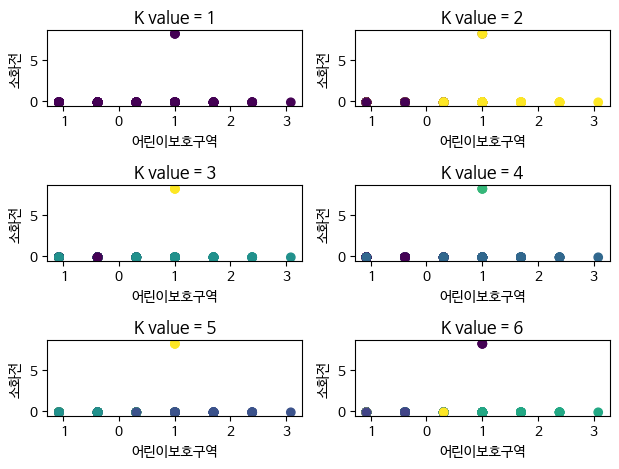

In [ ]:
for i in range(1, 7):
       # 클러스터 생성
       estimator = KMeans(n_clusters = i)
       ids = estimator.fit_predict(processed_data[['단속건수','위도',	'경도',	'혼잡빈도강도','어린이보호구역','소화전']])
       # 2행 3열을 가진 서브플롯 추가 (인덱스 = i)
       plt.subplot(3, 2, i)
       plt.tight_layout()
       # 서브플롯의 라벨링
       plt.title("K value = {}".format(i))
       plt.xlabel('어린이보호구역')
       plt.ylabel('소화전')
       # 클러스터링 그리기
       plt.scatter(processed_data['어린이보호구역'], processed_data['소화전'], c=ids)  
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
<ipython-input-59-37e0f73d91ec>:7: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_in

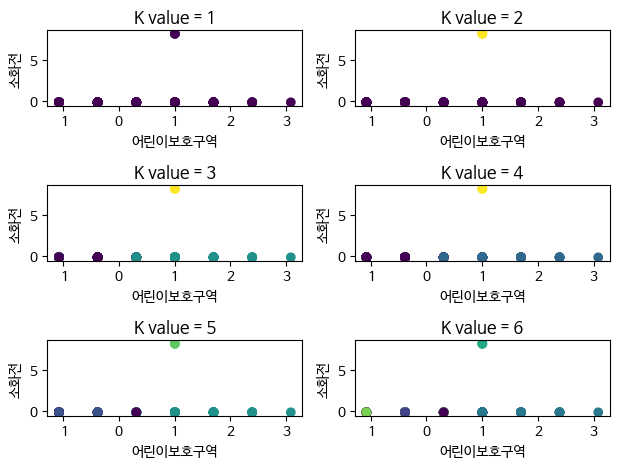

In [ ]:
for i in range(1, 7):
       # 클러스터 생성
       estimator = KMeans(n_clusters = i)
       ids = estimator.fit_predict(processed_data[['단속건수','혼잡빈도강도','어린이보호구역','소화전']])
       # 2행 3열을 가진 서브플롯 추가 (인덱스 = i)
       plt.subplot(3, 2, i)
       plt.tight_layout()
       # 서브플롯의 라벨링
       plt.title("K value = {}".format(i))
       plt.xlabel('어린이보호구역')
       plt.ylabel('소화전')
       # 클러스터링 그리기
       plt.scatter(processed_data['어린이보호구역'], processed_data['소화전'], c=ids)  
plt.show()

In [ ]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

print(kgz1)
x, y = kgz1(n_samples = 207, n_features = 2, centers = 3,
                  cluster_std = 0.5, shuffle = True, random_state = 0)
print("x.shape: ", x.shape, ", y.shape: ", y.shape)

plt.scatter(x[:, 0], x[:,1], marker = "o", s = 50)
plt.grid()
plt.show()

         단속건수        위도        경도    혼잡빈도강도   어린이보호구역       소화전
0    5.972817 -1.175113  0.801153  0.459652 -1.074414 -0.121268
1    4.610526 -0.339011 -1.211608  0.667498 -1.074414 -0.121268
2    4.472567 -0.953479  0.798782  0.459652 -1.074414 -0.121268
3    4.128334 -0.351508 -1.251348 -0.467343 -1.074414 -0.121268
4    3.647917 -1.175334  0.698998  0.459652 -1.074414 -0.121268
..        ...       ...       ...       ...       ...       ...
202 -0.498399  1.375652 -0.411829  1.473942  0.311279 -0.121268
203 -0.498399 -0.382530 -1.080931  0.667498 -0.381568 -0.121268
204 -0.498399  0.035764  1.182989 -0.679346  0.311279 -0.121268
205 -0.498399  1.289874 -0.329662 -3.572568  0.311279 -0.121268
206 -0.498843 -0.500790 -1.488603 -0.467343 -1.074414 -0.121268

[207 rows x 6 columns]


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

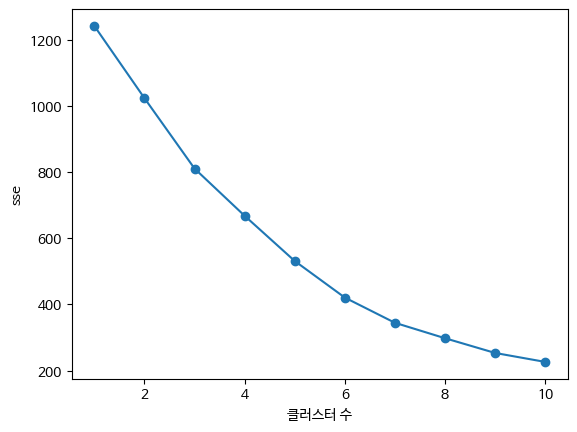

In [ ]:
def elbow(x):
    sse = [] #오차제곱합이 최소가 되도록 클러스터의 중심을 결정
    for i in range(1, 11):
        km = KMeans(n_clusters = i, init = "k-means++", random_state = 0)
        km.fit(x)
        sse.append(km.inertia_)
    plt.plot(range(1, 11), sse, marker = "o")
    plt.xlabel("클러스터 수")
    plt.ylabel("sse")
    plt.show()
    
elbow(kgz1)

In [ ]:
from sklearn.cluster import KMeans
init_centroid = "random" # 초기 클러스터 중심을 임의적
#init_centroid = "k-means++" # 기본값

kmodel = KMeans(n_clusters = 3, init = init_centroid, random_state = 0)
print(kmodel)
pred = kmodel.fit_predict(x)
print("pred: ", pred)
plt.scatter(x[pred == 0, 0], x[pred == 0, 1], marker = "o", s = 50, c = "red", label = "cluster1")
plt.scatter(x[pred == 1, 0], x[pred == 1, 1], marker = "s", s = 50, c = "green", label = "cluster2")
plt.scatter(x[pred == 2, 0], x[pred == 2, 1], marker = "v", s = 50, c = "blue", label = "cluster3")

plt.scatter(kmodel.cluster_centers_[:,0], kmodel.cluster_centers_[:,1],
            marker = "+", s = 80, c = "black", label = "center")
plt.legend()
plt.grid()
plt.show()

In [ ]:
clusters = linkage(y=kgz1, method='complete', metric='euclidean')
clusters
clusters.shape

In [ ]:
model = KMeans(n_clusters=4, algorithm='auto') # k = 4
model.fit(kgz1)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1366: FutureWarning: algorithm='auto' is deprecated, it will be removed in 1.3. Using 'lloyd' instead.
  warnings.warn(


KMeans(algorithm='auto', n_clusters=4)

In [ ]:
kgz1

,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,5.972817,-1.175113,0.801153,0.459652,-1.074414,-0.121268
1,4.610526,-0.339011,-1.211608,0.667498,-1.074414,-0.121268
2,4.472567,-0.953479,0.798782,0.459652,-1.074414,-0.121268
3,4.128334,-0.351508,-1.251348,-0.467343,-1.074414,-0.121268
4,3.647917,-1.175334,0.698998,0.459652,-1.074414,-0.121268
...,...,...,...,...,...,...
202,-0.498399,1.375652,-0.411829,1.473942,0.311279,-0.121268
203,-0.498399,-0.382530,-1.080931,0.667498,-0.381568,-0.121268
204,-0.498399,0.035764,1.182989,-0.679346,0.311279,-0.121268
205,-0.498399,1.289874,-0.329662,-3.572568,0.311279,-0.121268


In [ ]:
pred = model.predict(kgz1)
pred

In [ ]:
plt.scatter(x=kgz1['x'], y=kgz1['y'], c=pred)

##### (어린이+ 소화전) 해준다음 위경도 제외하고 표준화 다시하기.

In [ ]:
# top 200 데이터
kg1 = pd.read_csv('/content/gdrive/MyDrive/광진구_아웃라이어/데이터/최종_개수_top_동 전처리.csv')
kg1

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0,0
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0,0
...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2,0
203,235,화양동,194,37.540725,127.069567,73.02,1,0
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2,0
205,294,능동,194,37.555846,127.079076,42.42,2,0


In [ ]:
kg1.sort_values(by=['어린이보호구역','소화전'],ascending=False)

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
191,청구아파트,광장동,203,37.542454,127.096273,63.30,6,0
75,이튼타워리버3차앞,자양동,710,37.533363,127.068534,64.83,5,0
126,530-39,광장동,323,37.542058,127.095254,63.30,5,0
162,능동로4길,자양동,248,37.533084,127.069062,64.83,5,0
164,566,광장동,238,37.541805,127.096996,63.30,5,0
...,...,...,...,...,...,...,...,...
193,정립회관입구,구의동,200,37.550616,127.097845,71.52,0,0
196,서울광진구중곡동482-1,중곡동,197,37.558899,127.093532,73.62,0,0
199,아차산로78가길,광장동,196,37.549263,127.109850,63.30,0,0
201,119안전센터,능동,195,37.551658,127.076967,42.42,0,0


In [ ]:
kgs=kg1[['어린이보호구역','소화전']]
kg1['갯수합']=kgs.sum(axis=1)
kg1

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전,갯수합
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0,0,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0,0,0
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0,0,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0,0,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0,0,0
...,...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2,0,2
203,235,화양동,194,37.540725,127.069567,73.02,1,0,1
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2,0,2
205,294,능동,194,37.555846,127.079076,42.42,2,0,2


In [ ]:
kg1=kg1.sort_values(by=['소화전','갯수합'],ascending=False)
kg1.head()
kg1.drop('갯수합',axis=1)
kg1.to_csv("갯수.csv", index = False)

In [ ]:
kgz=kg1.loc[:,['단속건수','혼잡빈도강도','어린이보호구역',	'소화전',	'갯수합']]
kgz

,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합
0,14782,71.52,0,0,0
1,11711,73.02,0,0,0
2,11400,71.52,0,0,0
3,10624,64.83,0,0,0
4,9541,71.52,0,0,0
...,...,...,...,...,...
202,194,78.84,2,0,2
203,194,73.02,1,0,1
204,194,63.30,2,0,2
205,194,42.42,2,0,2


In [ ]:
kgz1=stats.zscore(kgz)
kgz1

,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합
0,5.972817,0.459652,-1.074414,-0.121268,-1.070094
1,4.610526,0.667498,-1.074414,-0.121268,-1.070094
2,4.472567,0.459652,-1.074414,-0.121268,-1.070094
3,4.128334,-0.467343,-1.074414,-0.121268,-1.070094
4,3.647917,0.459652,-1.074414,-0.121268,-1.070094
...,...,...,...,...,...
202,-0.498399,1.473942,0.311279,-0.121268,0.297248
203,-0.498399,0.667498,-0.381568,-0.121268,-0.386423
204,-0.498399,-0.679346,0.311279,-0.121268,0.297248
205,-0.498399,-3.572568,0.311279,-0.121268,0.297248


In [ ]:
kgz11=kgz1.loc[:,['단속건수','혼잡빈도강도','갯수합']]
kgz11

,단속건수,혼잡빈도강도,갯수합
0,5.972817,0.459652,-1.070094
1,4.610526,0.667498,-1.070094
2,4.472567,0.459652,-1.070094
3,4.128334,-0.467343,-1.070094
4,3.647917,0.459652,-1.070094
...,...,...,...
202,-0.498399,1.473942,0.297248
203,-0.498399,0.667498,-0.386423
204,-0.498399,-0.679346,0.297248
205,-0.498399,-3.572568,0.297248


In [ ]:
kg0=kg1.iloc[:,0:2]
kg0

,단속장소,동
0,리젠트오피스텔,구의동
1,건대입구1번출구앞,화양동
2,지너스타워주차장앞,구의동
3,건대역약국앞,자양동
4,동서울종합터미널주차장앞,구의동
...,...,...
202,서울광진구군자동498,군자동
203,235,화양동
204,양진초교길,광장동
205,294,능동


In [ ]:
kg2 = pd.concat([kg0,kgz1],axis=1)
kg2

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합
0,리젠트오피스텔,구의동,5.972817,0.459652,-1.074414,-0.121268,-1.070094
1,건대입구1번출구앞,화양동,4.610526,0.667498,-1.074414,-0.121268,-1.070094
2,지너스타워주차장앞,구의동,4.472567,0.459652,-1.074414,-0.121268,-1.070094
3,건대역약국앞,자양동,4.128334,-0.467343,-1.074414,-0.121268,-1.070094
4,동서울종합터미널주차장앞,구의동,3.647917,0.459652,-1.074414,-0.121268,-1.070094
...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,-0.498399,1.473942,0.311279,-0.121268,0.297248
203,235,화양동,-0.498399,0.667498,-0.381568,-0.121268,-0.386423
204,양진초교길,광장동,-0.498399,-0.679346,0.311279,-0.121268,0.297248
205,294,능동,-0.498399,-3.572568,0.311279,-0.121268,0.297248


In [ ]:
kg00=kg1.loc[:,['위도','경도']]
kg00

,위도,경도
0,37.533558,127.093389
1,37.541118,127.067913
2,37.535562,127.093359
3,37.541005,127.067410
4,37.533556,127.092096
...,...,...
202,37.556622,127.078036
203,37.540725,127.069567
204,37.544507,127.098222
205,37.555846,127.079076


In [ ]:
kg3 = pd.concat([kg2,kg00],axis=1)
kg3

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합,위도,경도
0,리젠트오피스텔,구의동,5.972817,0.459652,-1.074414,-0.121268,-1.070094,37.533558,127.093389
1,건대입구1번출구앞,화양동,4.610526,0.667498,-1.074414,-0.121268,-1.070094,37.541118,127.067913
2,지너스타워주차장앞,구의동,4.472567,0.459652,-1.074414,-0.121268,-1.070094,37.535562,127.093359
3,건대역약국앞,자양동,4.128334,-0.467343,-1.074414,-0.121268,-1.070094,37.541005,127.067410
4,동서울종합터미널주차장앞,구의동,3.647917,0.459652,-1.074414,-0.121268,-1.070094,37.533556,127.092096
...,...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,-0.498399,1.473942,0.311279,-0.121268,0.297248,37.556622,127.078036
203,235,화양동,-0.498399,0.667498,-0.381568,-0.121268,-0.386423,37.540725,127.069567
204,양진초교길,광장동,-0.498399,-0.679346,0.311279,-0.121268,0.297248,37.544507,127.098222
205,294,능동,-0.498399,-3.572568,0.311279,-0.121268,0.297248,37.555846,127.079076


In [ ]:
processed_data = kg2.copy()

In [ ]:
plt.figure(figsize = (10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
<ipython-input-116-8709c92b0e45>:7: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_i

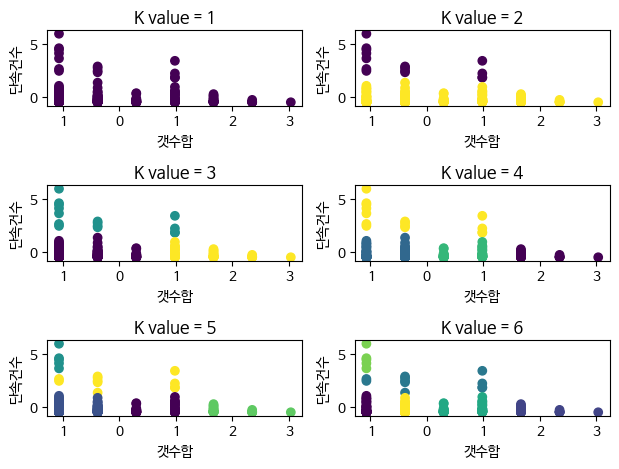

In [ ]:
for i in range(1, 7):
       # 클러스터 생성
       estimator = KMeans(n_clusters = i)
       ids = estimator.fit_predict(processed_data[['단속건수','갯수합']])
       # 2행 3열을 가진 서브플롯 추가 (인덱스 = i)
       plt.subplot(3, 2, i)
       plt.tight_layout()
       # 서브플롯의 라벨링
       plt.title("K value = {}".format(i))
       plt.xlabel('갯수합')
       plt.ylabel('단속건수')
       # 클러스터링 그리기
       plt.scatter(processed_data['갯수합'], processed_data['단속건수'], c=ids)  
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

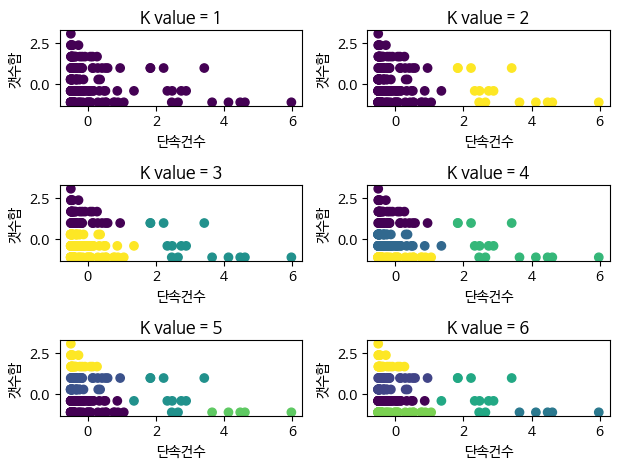

In [ ]:
for i in range(1, 7):
       # 클러스터 생성
       estimator = KMeans(n_clusters = i)
       ids = estimator.fit_predict(processed_data[['단속건수','갯수합']])
       # 2행 3열을 가진 서브플롯 추가 (인덱스 = i)
       plt.subplot(3, 2, i)
       plt.tight_layout()
       # 서브플롯의 라벨링
       plt.title("K value = {}".format(i))
       plt.xlabel('단속건수')
       plt.ylabel('갯수합')
       # 클러스터링 그리기
       plt.scatter(processed_data['단속건수'], processed_data['갯수합'], c=ids)  
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

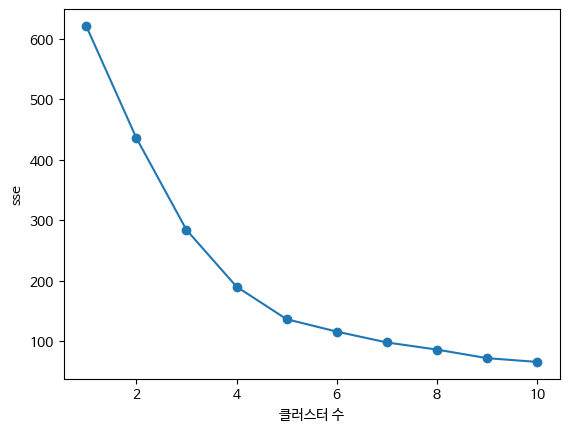

In [ ]:
def elbow(x):
    sse = [] #오차제곱합이 최소가 되도록 클러스터의 중심을 결정
    for i in range(1, 11):
        km = KMeans(n_clusters = i, init = "k-means++", random_state = 0)
        km.fit(x)
        sse.append(km.inertia_)
    plt.plot(range(1, 11), sse, marker = "o")
    plt.xlabel("클러스터 수")
    plt.ylabel("sse")
    plt.show()
    
elbow(kgz11)

##### 클러스터링 4

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1366: FutureWarning: algorithm='auto' is deprecated, it will be removed in 1.3. Using 'lloyd' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


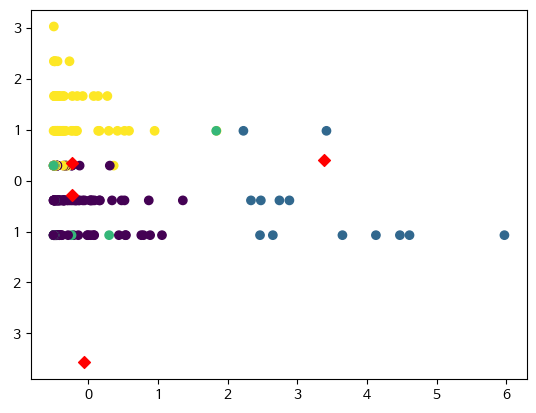

In [ ]:
model = KMeans(n_clusters=4, algorithm='auto') # k = 4
model.fit(kgz11)

# kMeans 예측치
pred = model.predict(kgz11)
pred 

plt.scatter(x=kgz11['단속건수'], y=kgz11['갯수합'], c=pred)

centers = model.cluster_centers_
centers

plt.scatter(x=centers[:,0], y=centers[:,1], marker='D', c='r')
plt.show()

In [ ]:
kg2

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합
0,리젠트오피스텔,구의동,5.972817,0.459652,-1.074414,-0.121268,-1.070094
1,건대입구1번출구앞,화양동,4.610526,0.667498,-1.074414,-0.121268,-1.070094
2,지너스타워주차장앞,구의동,4.472567,0.459652,-1.074414,-0.121268,-1.070094
3,건대역약국앞,자양동,4.128334,-0.467343,-1.074414,-0.121268,-1.070094
4,동서울종합터미널주차장앞,구의동,3.647917,0.459652,-1.074414,-0.121268,-1.070094
...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,-0.498399,1.473942,0.311279,-0.121268,0.297248
203,235,화양동,-0.498399,0.667498,-0.381568,-0.121268,-0.386423
204,양진초교길,광장동,-0.498399,-0.679346,0.311279,-0.121268,0.297248
205,294,능동,-0.498399,-3.572568,0.311279,-0.121268,0.297248


In [ ]:
kg22=kg2.loc[:,['단속장소','동','단속건수',	'혼잡빈도강도','갯수합']]

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


/usr/local/lib/python3.10/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  func(*args, **kwargs)
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


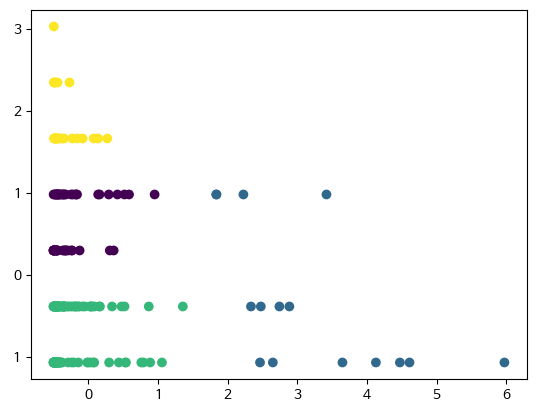

In [ ]:
estimator = KMeans(n_clusters = 4)

# 클러스터링 생성
cluster_ids = estimator.fit_predict(kg22[['단속건수','갯수합']])

# create a scatter plot
plt.scatter(kg22['단속건수'], kg22['갯수합'], c=cluster_ids)

# 제품과 클러스터 id로 데이터에 범례 달기
for location, dong, count, confusion,sum in kg22.itertuples():
    plt.annotate("Clu{}: {}".format(cluster_ids[location], dong),(confusion, sum))
    
plt.xlabel('단속건수')
plt.ylabel('갯수합')
plt.show()

In [ ]:
kg221=kg22[ cluster_ids == 1 ]
kg221.sort_values(by=['단속건수','갯수합'])

,단속장소,동,단속건수,혼잡빈도강도,갯수합
14,군자역5번가구할인매장앞,능동,1.836704,-3.572568,0.980919
13,올포유앞,자양동,1.840253,-0.467343,0.980919
12,파리바게트앞,자양동,2.226627,-0.467343,0.980919
11,강변스파랜드앞,구의동,2.334865,0.459652,-0.386423
10,우리은행앞,중곡동,2.464839,0.750637,-1.070094
9,건대분수광장건너편,화양동,2.476817,0.667498,-0.386423
8,강변역1번출구,구의동,2.648933,0.459652,-1.070094
7,중곡지구대앞,중곡동,2.743419,0.750637,-0.386423
6,구의동웰츠타워,구의동,2.886702,0.459652,-0.386423
5,MB모터스,중곡동,3.418576,0.750637,0.980919


In [ ]:
kg31=kg3[ cluster_ids == 1 ]
kg31=kg31.sort_values(by=['갯수합','단속건수'],ascending=False)
kg31

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합,위도,경도
5,MB모터스,중곡동,3.418576,0.750637,1.004125,-0.121268,0.980919,37.563661,127.078227
12,파리바게트앞,자양동,2.226627,-0.467343,1.004125,-0.121268,0.980919,37.532199,127.079078
13,올포유앞,자양동,1.840253,-0.467343,1.004125,-0.121268,0.980919,37.536186,127.064528
14,군자역5번가구할인매장앞,능동,1.836704,-3.572568,1.004125,-0.121268,0.980919,37.556729,127.079541
6,구의동웰츠타워,구의동,2.886702,0.459652,-0.381568,-0.121268,-0.386423,37.538346,127.084093
7,중곡지구대앞,중곡동,2.743419,0.750637,-0.381568,-0.121268,-0.386423,37.563888,127.082772
9,건대분수광장건너편,화양동,2.476817,0.667498,-0.381568,-0.121268,-0.386423,37.542164,127.071299
11,강변스파랜드앞,구의동,2.334865,0.459652,-0.381568,-0.121268,-0.386423,37.535074,127.091264
0,리젠트오피스텔,구의동,5.972817,0.459652,-1.074414,-0.121268,-1.070094,37.533558,127.093389
1,건대입구1번출구앞,화양동,4.610526,0.667498,-1.074414,-0.121268,-1.070094,37.541118,127.067913


In [ ]:
kg22[ cluster_ids == 2 ]

,단속장소,동,단속건수,혼잡빈도강도,갯수합
16,능동로,중곡동,1.057745,0.750637,-1.070094
18,태양주유소앞,중곡동,0.887846,0.750637,-1.070094
20,두산위브앞,군자동,0.791586,1.473942,-1.070094
21,강변역4번출구,구의동,0.760977,0.459652,-1.070094
23,동일로18길,자양동,0.540509,-0.467343,-1.070094
24,긴고랑로,중곡동,0.531637,0.750637,-1.070094
28,동서울종합터미널,구의동,0.439368,0.459652,-1.070094
33,어린이대공원정문,능동,0.299191,-3.572568,-1.070094
42,해모로리버뷰,구의동,0.084489,0.459652,-1.070094
43,강변역로4길,구의동,0.078279,0.459652,-1.070094


In [ ]:
kg22[ cluster_ids == 0 ]

,단속장소,동,단속건수,혼잡빈도강도,갯수합
17,고신경정신과의원앞,중곡동,0.952168,0.750637,0.980919
22,565,광장동,0.584869,-0.679346,0.980919
25,570,광장동,0.520103,-0.679346,0.980919
29,군자역1번명품갤러리앞,중곡동,0.418963,0.750637,0.980919
30,자양번영로,자양동,0.364400,-0.467343,0.297248
32,아차산로,구의동,0.308950,0.459652,0.297248
34,631-1,구의동,0.293868,0.459652,0.980919
37,노인종합복지관앞,군자동,0.160788,1.473942,0.980919
39,국민은행앞,구의동,0.142157,0.459652,0.980919
54,면목로,중곡동,-0.124002,0.750637,0.297248


In [ ]:
dfb

,고정형CCTV지번주소,위도,경도,자치구,단속지점명,현장구분
0,서울 광진구 광장동 334-2,37.547790,127.106990,광진구,SK강평주유소 앞,불법주정차구역
1,서울 광진구 광장동 445-3,37.543799,127.102410,광진구,광현교회 앞,불법주정차구역
2,서울 광진구 구의동 135,37.549593,127.081780,광진구,아차산역 5번출구 앞,불법주정차구역
3,서울 광진구 군자동 503,37.548609,127.071072,광진구,두산위브 앞,불법주정차구역
4,서울 광진구 구의동 66-62,37.545348,127.088420,광진구,국민은행 앞,불법주정차구역
5,서울 광진구 구의동 68-29,37.545976,127.086327,광진구,구의사거리,불법주정차구역
6,서울 광진구 구의동 546-1,37.533558,127.093389,광진구,리젠트오피스텔건너편,불법주정차구역
7,서울 광진구 구의동 546-11,37.535562,127.093359,광진구,지너스타워 주차장 앞,불법주정차구역
8,서울 광진구 구의동 611,37.538347,127.096620,광진구,현대2단지아파트 앞,불법주정차구역
9,서울 광진구 구의동 546-6,37.535668,127.094522,광진구,강변역 1번 출구,불법주정차구역


In [ ]:
kg31

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합,위도,경도
14,군자역5번가구할인매장앞,능동,1.836704,-3.572568,1.004125,-0.121268,0.980919,37.556729,127.079541
13,올포유앞,자양동,1.840253,-0.467343,1.004125,-0.121268,0.980919,37.536186,127.064528
12,파리바게트앞,자양동,2.226627,-0.467343,1.004125,-0.121268,0.980919,37.532199,127.079078
11,강변스파랜드앞,구의동,2.334865,0.459652,-0.381568,-0.121268,-0.386423,37.535074,127.091264
10,우리은행앞,중곡동,2.464839,0.750637,-1.074414,-0.121268,-1.070094,37.557633,127.088234
9,건대분수광장건너편,화양동,2.476817,0.667498,-0.381568,-0.121268,-0.386423,37.542164,127.071299
8,강변역1번출구,구의동,2.648933,0.459652,-1.074414,-0.121268,-1.070094,37.535668,127.094522
7,중곡지구대앞,중곡동,2.743419,0.750637,-0.381568,-0.121268,-0.386423,37.563888,127.082772
6,구의동웰츠타워,구의동,2.886702,0.459652,-0.381568,-0.121268,-0.386423,37.538346,127.084093
5,MB모터스,중곡동,3.418576,0.750637,1.004125,-0.121268,0.980919,37.563661,127.078227


In [ ]:
# 위도
latitude = 37.556729
# 경도
longitude = 127.079541


m = folium.Map(location=[latitude,longitude],
               zoom_start=18, 
               width=750, 
               height=500
              )

folium.Marker([latitude, longitude],
              popup="군자역5번가구할인매장앞", #옵션으로 
              tooltip="군자역5번가구할인매장앞").add_to(m) # 내가 만들어 놓은 지도 m위레다가 이 작업 해줘.
m

In [ ]:
# 위도
latitude = 37.5422876
# 경도
longitude = 127.101455


m = folium.Map(location=[latitude,longitude],
               zoom_start=18, 
               width=750, 
               height=500
              )

folium.Marker([latitude, longitude],
              popup="570", #옵션으로 
              tooltip="570").add_to(m) # 내가 만들어 놓은 지도 m위레다가 이 작업 해줘.
m

In [ ]:
# 위도
latitude = 37.536186
# 경도
longitude = 127.064528


m = folium.Map(location=[latitude,longitude],
               zoom_start=18, 
               width=750, 
               height=500
              )

folium.Marker([latitude, longitude],
              popup="올포유앞", #옵션으로 
              tooltip="올포유앞").add_to(m) # 내가 만들어 놓은 지도 m위레다가 이 작업 해줘.
m

In [ ]:
m = folium.Map(
    location=[kg31.위도.mean(), kg31.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in kg31.iterrows(): # 기존 단속장소 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속건수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + 클러스터링 + cctv.html')
m

In [ ]:
m = folium.Map(
    location=[kg31.위도.mean(), kg31.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in kg31.iterrows(): # 기존 단속장소 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속건수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + 클러스터링 + cctv.html')
m

-> 올포유앞, 군자역5번가구할인매장앞 가 유일하게 기존cctv와 겹치지 않는다. 

In [ ]:
kg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
0,리젠트오피스텔,구의동,14782,37.533558,127.093389,71.52,0,0
1,건대입구1번출구앞,화양동,11711,37.541118,127.067913,73.02,0,0
2,지너스타워주차장앞,구의동,11400,37.535562,127.093359,71.52,0,0
3,건대역약국앞,자양동,10624,37.541005,127.067410,64.83,0,0
4,동서울종합터미널주차장앞,구의동,9541,37.533556,127.092096,71.52,0,0
...,...,...,...,...,...,...,...,...
202,서울광진구군자동498,군자동,194,37.556622,127.078036,78.84,2,0
203,235,화양동,194,37.540725,127.069567,73.02,1,0
204,양진초교길,광장동,194,37.544507,127.098222,63.30,2,0
205,294,능동,194,37.555846,127.079076,42.42,2,0


In [24]:
kg.loc[kg['단속장소']=='올포유앞']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
13,올포유앞,자양동,5466,37.536186,127.064528,64.83,3,1


In [25]:
kg.loc[kg['단속장소']=='군자역5번가구할인매장앞']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
14,군자역5번가구할인매장앞,능동,5458,37.556729,127.079541,42.42,3,1


In [26]:
kg.loc[kg['단속장소']=='570']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
25,570,광장동,2490,37.542288,127.101455,63.3,3,2


In [32]:
kg.loc[kg['단속장소']=='동일로18길']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
23,동일로18길,자양동,2536,37.539132,127.06625,64.83,0,0


In [29]:
kkg=kg.sort_values(by=['소화전'],ascending=False)
kkg.head()
kkg

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
35,484,광장동,1935,37.540047,127.097786,63.30,4,3
38,361-23,군자동,1675,37.548066,127.072640,78.84,1,3
168,471-6,광장동,234,37.541138,127.096667,63.30,4,2
25,570,광장동,2490,37.542288,127.101455,63.30,3,2
122,동일로,자양동,341,37.539890,127.063162,64.83,0,2
...,...,...,...,...,...,...,...,...
87,227-336,자양동,545,37.538325,127.074623,64.83,3,0
88,아차산공원입구,구의동,543,37.550865,127.101659,71.52,1,0
89,구의강변로,구의동,537,37.534971,127.091240,71.52,1,0
91,광나루로,광장동,531,37.541066,127.096362,63.30,4,0


In [30]:
kkg.to_csv("다시.csv", index = False)

In [ ]:
kg32=kg3[ cluster_ids == 2 ]
kg32=kg32.sort_values(by=['단속건수','갯수합'],ascending=False)
kg32

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합,위도,경도
16,능동로,중곡동,1.057745,0.750637,-1.074414,-0.121268,-1.070094,37.562710,127.082241
18,태양주유소앞,중곡동,0.887846,0.750637,-1.074414,-0.121268,-1.070094,37.561855,127.074665
20,두산위브앞,군자동,0.791586,1.473942,-1.074414,-0.121268,-1.070094,37.548609,127.071072
21,강변역4번출구,구의동,0.760977,0.459652,-1.074414,-0.121268,-1.070094,37.535668,127.094522
23,동일로18길,자양동,0.540509,-0.467343,-1.074414,-0.121268,-1.070094,37.539132,127.066250
24,긴고랑로,중곡동,0.531637,0.750637,-1.074414,-0.121268,-1.070094,37.560852,127.084480
28,동서울종합터미널,구의동,0.439368,0.459652,-1.074414,-0.121268,-1.070094,37.533969,127.093637
33,어린이대공원정문,능동,0.299191,-3.572568,-1.074414,-0.121268,-1.070094,37.546696,127.078784
42,해모로리버뷰,구의동,0.084489,0.459652,-1.074414,-0.121268,-1.070094,37.533330,127.092143
43,강변역로4길,구의동,0.078279,0.459652,-1.074414,-0.121268,-1.070094,37.534132,127.092200


In [ ]:
#대략 12개만 뽑기(단속장소0근처 이상인것만)
kg32_10=kg32.iloc[0:12,:]
kg32_10

,단속장소,동,단속건수,혼잡빈도강도,어린이보호구역,소화전,갯수합,위도,경도
16,능동로,중곡동,1.057745,0.750637,-1.074414,-0.121268,-1.070094,37.562710,127.082241
18,태양주유소앞,중곡동,0.887846,0.750637,-1.074414,-0.121268,-1.070094,37.561855,127.074665
20,두산위브앞,군자동,0.791586,1.473942,-1.074414,-0.121268,-1.070094,37.548609,127.071072
21,강변역4번출구,구의동,0.760977,0.459652,-1.074414,-0.121268,-1.070094,37.535668,127.094522
23,동일로18길,자양동,0.540509,-0.467343,-1.074414,-0.121268,-1.070094,37.539132,127.066250
24,긴고랑로,중곡동,0.531637,0.750637,-1.074414,-0.121268,-1.070094,37.560852,127.084480
28,동서울종합터미널,구의동,0.439368,0.459652,-1.074414,-0.121268,-1.070094,37.533969,127.093637
33,어린이대공원정문,능동,0.299191,-3.572568,-1.074414,-0.121268,-1.070094,37.546696,127.078784
42,해모로리버뷰,구의동,0.084489,0.459652,-1.074414,-0.121268,-1.070094,37.533330,127.092143
43,강변역로4길,구의동,0.078279,0.459652,-1.074414,-0.121268,-1.070094,37.534132,127.092200


In [ ]:
m = folium.Map(
    location=[kg32_10.위도.mean(), kg32_10.경도.mean()],
    zoom_start=14,
    control_scale=True
)

for index, location_info in cctv5.iterrows(): #새로 추가된 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="green", icon="info-sign")).add_to(m)

for index, location_info in dfb.iterrows(): #기존의 cctv 장소
    folium.Marker([location_info["위도"], location_info["경도"]], popup=location_info["단속지점명"],
                   icon=folium.Icon(color="red", icon="info-sign")).add_to(m)

for index, location_info in kg32_10.iterrows(): # 기존 단속장소 
    folium.Marker([location_info["위도"], location_info["경도"]], 
                  popup=location_info["단속장소"],
                  tooltip=location_info["단속건수"]).add_to(m) # 클릭하면 이름이 보임


m.save('새로운 cctv5 + 클러스터링2 + cctv.html')
m

->동일로18길, 능동로

In [ ]:
kg.loc[kg['단속장소']=='능동로']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
16,능동로,중곡동,3702,37.562710,127.082241,73.62,0,0
65,능동로,화양동,859,37.542679,127.071583,73.02,1,0
66,능동로,자양동,845,37.537806,127.068999,64.83,0,0
175,능동로,능동,226,37.550678,127.074103,42.42,0,0


In [ ]:
kg.loc[kg['단속장소']=='동일로18길']

,단속장소,동,단속건수,위도,경도,혼잡빈도강도,어린이보호구역,소화전
23,동일로18길,자양동,2536,37.539132,127.06625,64.83,0,0


###### 결론-> 올포유앞, 군자역5번가구할인매장앞, 동일로18길, 능동로 

##### 클러스터링 5

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1366: FutureWarning: algorithm='auto' is deprecated, it will be removed in 1.3. Using 'lloyd' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


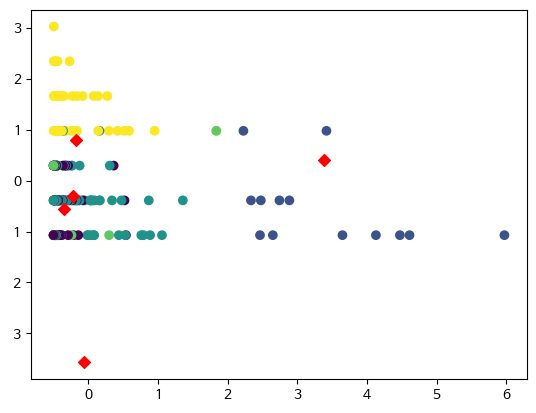

In [ ]:
model = KMeans(n_clusters=5, algorithm='auto') # k = 5
model.fit(kgz11)

# kMeans 예측치
pred = model.predict(kgz11)
pred 

plt.scatter(x=kgz11['단속건수'], y=kgz11['갯수합'], c=pred)

centers = model.cluster_centers_
centers

plt.scatter(x=centers[:,0], y=centers[:,1], marker='D', c='r')
plt.show()

In [ ]:
kg22[ cluster_ids == 1 ]

,단속장소,동,단속건수,혼잡빈도강도,갯수합
0,리젠트오피스텔,구의동,5.972817,0.459652,-1.070094
1,건대입구1번출구앞,화양동,4.610526,0.667498,-1.070094
2,지너스타워주차장앞,구의동,4.472567,0.459652,-1.070094
3,건대역약국앞,자양동,4.128334,-0.467343,-1.070094
4,동서울종합터미널주차장앞,구의동,3.647917,0.459652,-1.070094
5,MB모터스,중곡동,3.418576,0.750637,0.980919
6,구의동웰츠타워,구의동,2.886702,0.459652,-0.386423
7,중곡지구대앞,중곡동,2.743419,0.750637,-0.386423
8,강변역1번출구,구의동,2.648933,0.459652,-1.070094
9,건대분수광장건너편,화양동,2.476817,0.667498,-0.386423


In [ ]:
kg22[ cluster_ids == 2 ]

,단속장소,동,단속건수,혼잡빈도강도,갯수합
15,프라임아파트정문(213동),구의동,1.357174,0.459652,-0.386423
16,능동로,중곡동,1.057745,0.750637,-1.070094
18,태양주유소앞,중곡동,0.887846,0.750637,-1.070094
19,건대입구3번출구앞,화양동,0.868328,0.667498,-0.386423
20,두산위브앞,군자동,0.791586,1.473942,-1.070094
...,...,...,...,...,...
199,아차산로78가길,광장동,-0.497512,-0.679346,-1.070094
200,아차산로,화양동,-0.497955,0.667498,-0.386423
201,119안전센터,능동,-0.497955,-3.572568,-1.070094
203,235,화양동,-0.498399,0.667498,-0.386423
